# RiskMatch V3 — Quantitative Research Lab

One notebook for the whole project. The 27 chapter numbers are navigation anchors. Execution follows the [roadmap](../docs/ROADMAP.md), [A–Z checklist](../CHECKLIST_A_Z.md) and [prerequisite registry](../docs/TASK_DEPENDENCIES.csv).

Start with chapters 01 and 12 (mandate and 11 objectives) and 02 (Discovery), alongside data work. Validate the minimal ETF backtest (BT00, chapter 23) before advanced models. Test Explore on baselines, then improve and validate all candidates before final matching.

## Table of Contents
- [01 — Client Mandate](#chapitre-01)
- [02 — Behavioral Discovery](#chapitre-02)
- [03 — US Universe](#chapitre-03)
- [04 — Sources and Licenses](#chapitre-04)
- [05 — Point-in-Time Ingestion](#chapitre-05)
- [06 — Returns and FX](#chapitre-06)
- [07 — Descriptive Statistics](#chapitre-07)
- [08 — Return Forecasting](#chapitre-08)
- [09 — Volatility and Covariance](#chapitre-09)
- [10 — Factors and Regressions](#chapitre-10)
- [11 — Tail Risk](#chapitre-11)
- [12 — Financial Objectives](#chapitre-12)
- [13 — Baselines](#chapitre-13)
- [14 — Mean-Variance](#chapitre-14)
- [15 — Black-Litterman](#chapitre-15)
- [16 — Risk Parity and Hierarchical Methods](#chapitre-16)
- [17 — Downside Optimization](#chapitre-17)
- [18 — Advanced Optimization](#chapitre-18)
- [19 — Passive and Active Strategies](#chapitre-19)
- [20 — Alternative Strategies](#chapitre-20)
- [21 — US Treasuries](#chapitre-21)
- [22 — Futures](#chapitre-22)
- [23 — Walk-Forward Backtesting](#chapitre-23)
- [24 — Stress and Monte Carlo](#chapitre-24)
- [25 — Improvement, Matching and Comparison](#chapitre-25)
- [26 — Dynamic Management](#chapitre-26)
- [27 — Integration and Validation](#chapitre-27)

### Version présentée dans la web app

Le mandat personnalisé utilise 60 rendements totaux mensuels USD par titre,
de janvier 2021 à décembre 2025 pour les poids affichés. À la coupure, le
catalogue présente 642 actions US, 15 ETF d’actions, 5 ETF du Trésor et une
poche de cash USD Fama-French. Le replay utilise des listes d’actions datées.
Il sépare 35 mois de développement et 25 mois de test commun. Les expériences
historiques à 575 titres des chapitres de recherche ont leurs propres dates
et périmètres. On peut les reproduire dans ce notebook.

Dans la web app, Recherche donne accès à Univers, Sources et données
manquantes, Catalogue des stratégies et Méthodologie. Les dates de publication
manquantes, le registre rétrospectif des ETF, la sélection par couverture et
la courte période de test limitent l’interprétation. Le suivi des positions
demande un flux de cours configuré sur le serveur.

La sélection présente jusqu’à six portefeuilles compatibles et distincts,
avec une comparaison de toutes les cartes disponibles, un benchmark SPY et
des motifs quand un backtest est incomplet. Les rendements communs sont
régularisés vers la médiane de leur classe d’actifs. Le catalogue distingue
47 stratégies candidates, le benchmark SPY et les méthodes de recherche Sortino et Omega.
Sur le mandat standard testé à 18/30, les 47 candidates disposent d’un
replay complet et donnent 45 cartes. Sur Trésor + cash, 28 méthodes
terminent le replay et donnent 8 cartes. Le replay prend en compte les
règlements de fusion documentés. Le signal défensif intègre la valeur
d’ouverture de sa fenêtre et le diagnostic multi-stratégies distingue
les corrélations observées du plancher de volatilité des budgets.
Sortino et Omega ont terminé les deux replays dans un essai local avec
règle de départage. Les cartes client gardent leur statut de recherche.

Dans Mes matchs, quatre modes répartissent les budgets entre les cartes
retenues. La projection confirmée utilise les poids consolidés, 60 mois de
rendements alignés, 1 000 trajectoires et les flux du mandat. Le bilan sépare
les poids consolidés, le backtest, le capital restant, le gain net simulé
et sa valeur actuelle à un taux annuel réglable. Les exclusions de sociétés
et de secteurs utilisent la classification datée des actions directes.
Le moteur de projection couvre jusqu’à 50 ans. Après toute modification des
budgets, une nouvelle confirmation est nécessaire. La revue académique
propose un parcours de démonstration du mandat jusqu’au bilan.
Voir l’[audit des
stratégies et du portefeuille](../docs/AUDIT_STRATEGIES_ET_PORTEFEUILLE.md).


## Reproduire l’étude

Depuis la racine du projet, lancer `./INSTALL.command` avec Python 3.12, puis `.venv/bin/jupyter lab notebooks/RiskMatch_V3.ipynb`. Dans Jupyter, choisir **Restart Kernel and Run All Cells**. Le parcours par défaut utilise les exemples versionnés et des séries synthétiques à graines fixes. Les résultats enregistrés correspondent à ce parcours. Les valeurs décimales de rendement se lisent ainsi : 0,01 = 1 %.

Pour reproduire également le cas historique, lancer Jupyter avec `RISKMATCH_NOTEBOOK_HISTORY=1` dans l’environnement. Chaque chapitre appelle le moteur de la web app avec un scénario daté reproductible. Les rapports détaillés, statuts des actifs, budgets, tests de sensibilité et registres de transactions sont dépliables. Les chapitres 1, 2, 25, 26 et 27 partagent le même mandat fictif USD. Conserver les sorties historiques dans son espace privé. Les méthodes, archives attendues et limites sont détaillées dans les chapitres.

Les listes dépliables reprennent les cases de la checklist à chaque exécution. Un test numérique réussi établit le résultat de son exemple. Le statut de validation du projet se lit dans la checklist.

Pour générer la version locale complète destinée à la revue : `.venv/bin/python scripts/execute_notebook.py --historical --save-outputs`. Le résultat se trouve dans `data/reports/RiskMatch_V3_professeur.ipynb`. Il contient des résultats dérivés des données locales : vérifier les droits avant tout partage.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'riskmatch').exists())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
import os
import platform
import hashlib
import re
from html import escape
from importlib.metadata import version
from IPython.display import HTML, display
from collections import defaultdict
import csv

historical_mode = os.environ.get("RISKMATCH_NOTEBOOK_HISTORY", "0") == "1"
checklist_path = root / "CHECKLIST_A_Z.md"
checklist = checklist_path.read_text(encoding="utf-8")
tasks = defaultdict(list)
for line in checklist.splitlines():
    if line.startswith("## "):
        section = line[3:].strip()
        subgroup = ""
    elif line.startswith("### "):
        subgroup = line[4:].strip()
    elif task := re.match(r"^- \[([ xX])\] (.*)", line):
        tasks[section].append((subgroup, task[1].lower() == "x", task[2]))
catalog_sections = {0: ['Setup and Organization', 'Usage and Traceability'], 12: ['Catalog — 11 Client Objectives'], 14: ['Catalog — 22 Construction Methods'], 19: ['Catalog — 19 Strategies'], 10: ['Catalog — 13 Factors'], 26: ['Catalog — 10 Dynamic Models'], 23: ['Cross-Cutting Catalog — Portfolio Metrics'], 27: ['Final Validation']}


ticket_states = {}
for entries in tasks.values():
    for _, done, description in entries:
        if match := re.match(r"^\*\*([A-Z0-9.]+)\*\*", description):
            ticket_states[match[1]] = done
with (root / "docs/TASK_DEPENDENCIES.csv").open(encoding="utf-8") as stream:
    ticket_dependencies = {row["ticket"]: [p.strip() for p in row["direct_prerequisites"].split(";") if p.strip()]
                           for row in csv.DictReader(stream)}
assert ticket_states.keys() == ticket_dependencies.keys()
ready_tickets = [ticket for ticket, done in ticket_states.items()
                 if not done and all(ticket_states[p] for p in ticket_dependencies[ticket])]
print(f"Tickets formels : {sum(ticket_states.values())}/{len(ticket_states)} clôturés.")
print("Tickets prêts à traiter :", ", ".join(ready_tickets))

def show_checklist(number):
    chapter = int(number)
    sections = [s for s in tasks if s.startswith(f"{chapter:02}. ")]
    sections += catalog_sections.get(chapter, [])
    for section in sections:
        entries = tasks[section]
        rows = []
        last = None
        for group, done, description in entries:
            if group and group != last:
                rows.append(f"<h5>{escape(group)}</h5>")
            last = group
            label = escape(description.replace("**", ""))
            note = ""
            if not done and (match := re.match(r"^\*\*([A-Z0-9.]+)\*\*", description)):
                blocked = [p for p in ticket_dependencies[match[1]] if not ticket_states[p]]
                state = "Prérequis ouverts : " + ", ".join(blocked) if blocked else "Prêt à traiter — preuve requise"
                note = f" <small style='color:#806030'>({escape(state)})</small>"
            rows.append(f"<div>{'☑' if done else '☐'} {label}{note}</div>")
        display(HTML(f"<details><summary>{escape(section)} · {sum(x[1] for x in entries)}/{len(entries)} cochés</summary>{''.join(rows)}</details>"))

mapped = [s for s in tasks if re.match(r"^\d{2}\. ", s)]
mapped += [s for sections in catalog_sections.values() for s in sections]
assert sorted(mapped) == sorted(tasks), "Vérifier le rattachement des nouvelles sections."
print("Python", platform.python_version(), "|", {p: version(p) for p in ("numpy", "scipy", "pandas", "scikit-learn")})
print("Mode historique :", historical_mode, "| Checklist SHA-256 :", hashlib.sha256(checklist.encode()).hexdigest())
show_checklist("00")
if historical_mode:
    if str(root) not in sys.path:
        sys.path.insert(0, str(root))
    from scripts.notebook_evidence import Evidence
    review = Evidence(root)

Tickets formels : 222/1230 clôturés.
Tickets prêts à traiter : UNIV.01, CH02.16, CH04.03, CH27.08
Python 3.12.6 | {'numpy': '2.2.5', 'scipy': '1.15.2', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}
Mode historique : False | Checklist SHA-256 : 048435d5854775b8fce31205e056f34ce20a3170e75a730b958f8bb19c13f8fd


### INFRA.01 — Environment validation (2026-11-24)

**Observed baseline:** macOS arm64, Python 3.12.6, pip 24.2, Node 23.11.1. The active virtual environment inherits system packages. Installed research libraries: NumPy 2.2.5, pandas 2.2.3, SciPy 1.15.2, JupyterLab 4.5.6 and nbformat 5.10.4.

**Evidence:** `pip check` reported no broken requirements; 8 Python unit tests and 5 JavaScript tests passed. A non-blocking pip cache permission warning was observed.

**Gap:** CI targets Python 3.11, the local environment uses 3.12, and inherited packages and unpinned transitive dependencies prevent repeatable clean installation.

**Decision D001 (approved by owner, 2026-11-24):** standardize on Python 3.12, isolate the virtual environment, pin all shared dependencies in `requirements.lock`, and preserve licensed data locally. CI now uses Python 3.12. WRDS, other licensed datasets, derived files, browser saves, credentials and logs stay outside Git.

**Implementation evidence:** fresh `.venv` created from the lock using INSTALL.command (the old environment is preserved in `.venv-legacy`). `pip check` passed, 13 Python tests and 5 Web tests passed, and eight explicitly synthetic notebook cells executed with the Python 3.12 kernel. The Jupyter runtime now lives under ignored `.run/`; optional SOCKS support is locked for proxy environments. The web health endpoint returned success and Jupyter returned HTTP 302. Process inspection is restricted, so STOP remains to be verified in the owner's Terminal. No UI or licensed data change. Linux CI remains to be verified remotely.

### G00 — Shared contracts and eligibility (CH27.01–02, SYS.01–02)

Prepare the versioned interfaces before financial modeling: ClientProfile, ConstraintSet, GoalSpec, Card, MarketSnapshot, ForecastBundle, RiskReport, StrategySpec, OptimizerSpec, PortfolioCandidate, Evaluation and Selection. All new contract outputs use a UTC timestamp, run ID, model and schema versions, explicit units, status, warnings and provenance. Keep forecasts separate from risk, strategy from optimizer, and funded weights from futures contracts. Detailed mandate inputs are defined in chapter 01; the legacy demonstration is not a validated financial model.

The eligibility registry covers 22 optimizers, 19 strategies, 13 factors and 10 dynamic methods. It fails closed without independent validation, necessary data, instrument verification, capacity, frequency, and required permissions or margin evidence. The 11 objectives are not methods. No method is approved merely because its interface exists. See `src/riskmatch/contracts.py`, `src/riskmatch/eligibility.py`, `tests/unit/test_contracts.py` and [architecture](../docs/ARCHITECTURE.md).

Collaboration conventions and experiment registry: [CONTRIBUTING](../CONTRIBUTING.md), [experiment registry](../docs/EXPERIMENT_REGISTRY.md). D002: public repository for now; restricted data remain local. Commit c05aaee was confirmed on origin/main and the owner reported green GitHub Actions. Both local ports stopped responding after the owner ran STOP.command. D003: solo development, direct validated pushes permitted; require collaborator access controls, PR review and main protection before collaboration. G00 closed in solo mode. Next: chapter 01 Client Mandate, together with the objective specifications in chapter 12.

In [2]:
from datetime import datetime, timezone
from riskmatch.contracts import RunMetadata, ForecastBundle, RiskReport
from riskmatch.eligibility import REGISTRY, assess
meta = RunMetadata(as_of=datetime(2026, 11, 24, tzinfo=timezone.utc), run_id='synthetic-g00',
                   model_version='fixture-v1', units=(('return', 'decimal'),), provenance=('synthetic',))
forecast = ForecastBundle(meta=meta, snapshot_id='fixture', instrument_ids=('ETF-A',),
                          expected_returns=(0.01,), horizon_periods=1, frequency='monthly', currency='USD')
risk = RiskReport(meta=meta, snapshot_id='fixture', instrument_ids=('ETF-A',),
                  covariance=((0.002,),), frequency='monthly', currency='USD')
eligibility = assess('OPT01', instruments=frozenset({'equity_etf'}), data=REGISTRY['OPT01'].data,
                     frequency='monthly', capacity_verified=True)
assert not eligibility.eligible and 'method_not_validated' in eligibility.reasons
len(REGISTRY), forecast.meta.status, eligibility.reasons

(64, <Status.EXPERIMENTAL: 'experimental'>, ('method_not_validated',))

<a id="chapitre-01"></a>

## 01 — Client Mandate

**Objective:** Define ClientProfile, hard constraints, preferences and feasibility.

Reference: [A–Z Guide, chapter 1](../docs/QUANT_GUIDE_A_Z.md).

Status: chapter 01 implementation, deterministic validation only. Full portfolio feasibility and advisory suitability are not evaluated. See [Client Mandate](../docs/CLIENT_MANDATE.md).

### 01.1 Theory and Assumptions
CH01.01–05: choose CHF/USD; cash, liquid investments, other assets, debt and reserve are distinct. Net worth = cash + investments + other assets − debt; investable wealth = cash + investments − reserve. Capital is allocated from investable wealth. All flows use the base currency; mixed-currency goals require an explicit CHF/USD scenario. Real targets = current purchasing power × (1+inflation)^T. Dates are ACT/365.25. Contributions and withdrawals have separate signs and dates; goals have objective IDs, currency, basis, priority and penalty.

CH01.06: W(T)=C(1+r)^T+Σ CF_i(1+r)^(T−t_i); solve required return by Brent root finding in log(1+r), rejecting ambiguous sign patterns and interim borrowing. Zero-return funding gaps are diagnostics, not a market forecast.

CH01.07–12: explicit loss capacity capped by capital, liquid wealth and minimum zero-return balance over the next 12 months. Stress cap = min(declared stress cap, loss budget, capacity/capital). Risk willingness and required risk remain distinct. Experience and permissions are independent. Hard limits never relax silently; missing optional limits are null. Structural conflicts are returned explicitly.

CH01.13–15: version 2.0.0 payload, synthetic fixture, API preview, before/after review and explicit confirmation. Restricted real data remain outside Git; older minimal saves retain legacy scope. The USD demo cannot evaluate CHF or unmodeled hard constraints. No model approval is implied.

[Note de recherche du projet](../docs/CLIENT_MANDATE.md)

Version 2.0.0, simulation only. Implementation: `src/riskmatch/profiling/mandate.py`; API: `POST /api/mandate/preview`; form: `apps/web/mandate.js`. SciPy is now a runtime dependency for the dated cash-flow solver; its pinned version is unchanged. A structural validation is not a suitability assessment, financial advice, market feasibility, or approval to trade. Use fictional profiles only.

#### Formulaire client actuel

- Le parcours USD présente dix objectifs. « Croissance » couvre `OBJ05` et le même comportement de classement que l'ancien `OBJ06`. Les sauvegardes existantes restent lisibles. Une fiche `OBJ06` s'affiche comme « Croissance » lors de la révision du mandat et utilise `OBJ05` lors de la nouvelle confirmation.
- « Revenu » renvoie vers les retraits mensuels ou ponctuels. La couverture dépend de ces flux. Le formulaire masque le montant, la devise, la base et la pénalité de cet objectif.
- Les autres actifs et les dettes se trouvent dans **Bilan patrimonial facultatif**. Le solde à investir, les liquidités, les placements disponibles, la réserve et les flux restent dans le parcours principal.
- La pénalité de déficit demeure accessible dans les réglages avancés d'un objectif chiffré, avec 1 par défaut. L'inflation apparaît pour une cible réelle ou un objectif de protection contre l'inflation. Le taux de change apparaît pour une cible chiffrée en devise étrangère.
- Les deux questions de perte restent distinctes. Les choix d'actifs couvrent actions américaines et ETF d'actions, ETF du Trésor américain et cash USD. La volatilité et le plafond par actif sont facultatifs, avec les modes « À respecter absolument » et « À privilégier ».
- Le serveur conserve les onze identifiants et les champs hérités du schéma pour la lecture des anciennes sauvegardes et les modules de recherche. Les classes retirées bloquent le nouveau calcul personnalisé jusqu'à la révision du mandat.

#### Data and units (CH01.01–05)

| Input | Unit / interpretation |
|---|---|
| Reference currency | CHF or USD; all balance sheet amounts and recurring/dated flows use this currency |
| FX | Optional CHF per USD scenario; USD→CHF multiply, CHF→USD divide; required for mixed-currency goal amounts, no forecast |
| Inflation | Effective annual decimal rate, explicitly required for real goals; target nominal amount = real amount × (1+inflation)^years |
| Wealth | cash + liquid investments + other assets − debt; reserve is already included in cash |
| Investable wealth | cash + liquid investments − emergency reserve; allocated capital is a subset, not an additional asset |
| Income and expenses | Monthly net income and spending; surplus = income − spending; contributions cannot exceed positive surplus in the initial model |
| Flows | Positive contributions, negative withdrawals/liability payments; recurring monthly from the valuation date; explicit dated events must lie inside horizon |
| Horizon | Valuation and end date, ACT/365.25 year fraction; next withdrawal (including funded goals) is separate |
| Goals | Catalog ID, due date, optional amount, currency, nominal/real basis, priority 1–5, nonnegative relative shortfall penalty, explicit funded obligation flag |

Do not double count liabilities in monthly expenses, dated flows and goal obligations. Debt balance reduces net worth; debt repayment timing is a separate dated cash-flow input. The 11 objectives retain their stable catalog IDs. Income is periodic; never treat it as a terminal liability. Goal-Based and LDI require an explicitly funded dated target. Other styles may be non-financial preferences or an explicit funded monetary obligation. A monetary target for a non-funded objective is assessed independently; funded objectives are combined into the cash-flow schedule. Priority weights are priority divided by sum of priorities; penalty is a separate dimensionless multiplier, reserved for normalized shortfall scoring in chapter 12. Objective definitions do not select an optimizer or a benchmark.

| ID | Client intent | Quantitative target to implement later |
|---|---|---|
| OBJ01 | Capital preservation | Minimize probability and magnitude of nominal/real loss |
| OBJ02 | Recurring income | Net periodic income target and stability; withdrawals are cash flows |
| OBJ03 | Conservative | Strict loss/volatility budget, with return secondary |
| OBJ04 | Balanced | Risk-return trade-off constrained by mandate |
| OBJ05 | Growth | Terminal wealth or real return, not automatic leverage |
| OBJ06 | Aggressive growth (legacy ID) | Same orientation and scoring rule as OBJ05 in personalized matching |
| OBJ07 | Inflation protection | Purchasing-power target and inflation sensitivity |
| OBJ08 | Absolute return | Net excess return versus cash and downside control |
| OBJ09 | Liability-driven | Dated liability coverage; duration/DV01 mismatch later |
| OBJ10 | Goal-based | Funding success probability and expected shortfall later |
| OBJ11 | Capital protection | Conditional floor, gap risk and hedge costs; no guarantee |

#### Deterministic funding mathematics (CH01.06)

At constant annual effective nominal return r, dated deposits and withdrawals satisfy

`W(T) = C(1+r)^T + Σ CF_i (1+r)^(T−t_i)`.

Without flows, `r = (G/C)^(1/T)−1`. With flows, solve the discounted cash-flow equation with Brent's method in log(1+r) on [−20, 20], after grouping same-date flows. More than one chronological sign change produces an explicit ambiguous-root diagnostic, not a selected IRR. A root implying intermediate borrowing is rejected. Individual zero-return gap = max(0, target − capital available by its date); separately report the aggregate scheduled balance including all funded goals, without double counting. Zero-return deficit is a warning rather than proof that market funding is impossible. A required return is not a forecast or required volatility. No inflation forecasts or FX forecasts are inferred.

#### Ability, willingness and required risk (CH01.07–08)

The client declares maximum financially absorbable loss in currency units. Cap it by allocated capital, investable wealth and the minimum modeled zero-return balance over the next 12 months (or shorter horizon). The effective hypothetical stress cap is the minimum of declared stress limit, hard loss budget and capacity/capital. This is a conservative deterministic screening rule, not an empirical capacity model. No behavior score or return target increases the cap. Willingness is measured separately in chapter 02; required risk needs a validated return/risk engine. Technical knowledge (none/basic/advanced) and practical experience (none/limited/experienced) are self-reported separately for equity, Treasuries, futures, leverage, and short selling; absence of either conflicts with advanced permission. It is not a qualification test.

#### Restrictions and feasibility (CH01.09–12)

Hard stress and loss budgets are required and share one input in new drafts. The current form offers annual volatility and per-holding weight limits. Historical payloads can also carry issuer/sector, turnover, cost, liquidity or exposure limits, ESG/tax/FX preferences and advanced permissions. The personalized engine handles the [current portfolio universe and supported constraints](../docs/PERSONALIZED_MATCHING.md). A required restriction outside that scope blocks personalized generation. Null means the optional limit is unspecified. Capital above investable wealth, contributions above surplus and uncovered spending deficits are structural conflicts.

#### Versioning, consent and UI (CH01.13–15)

Schema version 2.0.0 covers both the client and constraint payload; the previous minimal schema is preserved only for old simulation saves. The browser stores the confirmed payload locally using the existing encrypted save mechanism; a four-digit PIN is not for real client information. Draft preview does not replace the confirmed mandate. Explicit confirmation updates the save and resets discovery/portfolio choices; before/after review displays the old and proposed stress cap, capital and dated goals. Conflicts disable confirmation. The API validates on both preview and candidate requests; it stores no profile. EN/FR labels preserve canonical English API keys. `configs/mandate-example.json` is wholly synthetic. Tests cover balances, dated returns, FX/inflation, constraints, no short/leverage inference, malformed amounts, negative/zero capital, unsupported currency, missing consent, horizon mismatch, uncovered withdrawals, and UI confirmation; CI executes synthetic notebook cells only.

#### Decision log — provisional assumptions for owner review

- CHF/USD only, mixed goals use an explicit scenario FX rate, no live FX conversion.
- Loss capacity uses a 12-month minimum zero-return liquidity cushion, not a psychometric or regulated capacity assessment.
- Recurring contributions are funded by positive monthly surplus; reserve is part of cash. Dated obligations are kept separate from debt stock.
- Goal priorities 1–5 and separate shortfall penalty; all amounts nominal by default unless explicitly real.
- No advanced permission by default; optional hard restrictions block demo Explore until they are evaluated. No real financial data, recommendations or orders.

In [3]:
import json
from riskmatch.profiling.mandate import validate_mandate
profile = json.loads((root / 'configs' / 'mandate-example.json').read_text())
mandate_report = validate_mandate(profile)
assert mandate_report['status'] == 'structurally_valid'
assert mandate_report['net_worth'] == 180000 and mandate_report['investable_wealth'] == 130000
assert mandate_report['goals'][0]['zero_return_gap'] == 20000
{k: mandate_report[k] for k in ('net_worth', 'investable_wealth', 'monthly_surplus', 'effective_stress_limit', 'goals', 'combined_required_return')}

{'net_worth': 180000.0,
 'investable_wealth': 130000.0,
 'monthly_surplus': 2500.0,
 'effective_stress_limit': 0.2,
 'goals': [{'goal_index': 0,
   'objective_id': 'OBJ10',
   'due_date': '2036-11-25',
   'target_nominal_base': 240000.0,
   'funding': True,
   'priority': 3,
   'shortfall_penalty': 1.0,
   'required_return': {'status': 'calculated',
    'annual_return': 0.011964521054906196},
   'zero_return_gap': 20000.0,
   'priority_weight': 1.0}],
 'combined_required_return': {'status': 'calculated',
  'annual_return': 0.011964521054906196}}

### 01.2 Validation

### 01.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [4]:
if historical_mode:
    review.chapter(1)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [5]:
show_checklist('01')

<a id="chapitre-02"></a>

## 02 — Behavioral Discovery

**Objective:** Version cards, responses, coverage, score and sensitivity.

Reference: [A–Z Guide, chapter 20](../docs/QUANT_GUIDE_A_Z.md).

Status: implemented experimental Discovery v3.0.0 (CH02.01–15 and CH02.21). Human validation CH02.16–20 remains open. See [behavioral protocol](../docs/RISKMATCH_BEHAVIORAL.md) and [draft pilot](../docs/BEHAVIORAL_PILOT.md).

### 02.1 Theory and Assumptions

Version `discovery-v3.0.0`. Le questionnaire actif contient 30 cartes fixes, dans le même ordre et avec la même position des options pour tous les participants d’une même version. La graine de session ne change plus les questions. Les mêmes montants nominaux sont présentés dans la devise du mandat, en français ou en anglais. Le questionnaire porte sur des choix simulés.

#### Six blocs

| Bloc | Cartes | Ce qu’il explore |
|---|---:|---|
| Gains et pertes possibles | 8 | Comparaison avec un solde inchangé. Deux tailles de perte (100 ou 500) et quatre ratios gain/perte par taille, avec probabilités de 50 %. |
| Risque face aux gains | 6 | Gain garanti ou gain incertain. La probabilité et l’écart de gain moyen varient. |
| Risque face aux pertes | 6 | Perte certaine ou risque de perdre davantage avec une possibilité de ne rien perdre. |
| Événements rares | 4 | Deux gains et deux pertes, de probabilité 1 % ou 5 %, comparés à un montant certain de même valeur espérée. |
| Baisses temporaires | 4 | Deux chemins depuis un indice de 100, mêmes résultats finaux à un an, mêmes probabilités et mêmes frais. Le creux en cours de route varie. |
| Vérification des choix | 2 | Comprendre une probabilité de 1 % et répondre de nouveau à la première situation avec les options inversées. |

#### Les 30 cartes dans l’ordre affiché

Les formulations ci-dessous prennent le CHF comme exemple. « Non » garde l’option actuelle et « Oui » accepte l’alternative. Les cartes monétaires indiquent un solde fictif de 10 000. Pour les trajectoires, les deux résultats à un an sont équiprobables et les frais sont identiques. La carte CT01 demande combien de fois un événement de probabilité 1 % se produirait **en moyenne** sur 100 essais. La colonne finale indique la réponse comptée comme prudente pour l’indice de prudence provisoire.

| Ordre | ID | Bloc | Option actuelle (Non) | Alternative (Oui) | Indice de prudence |
|---:|---|---|---|---|---|
| 1 | GN01 | Risque face aux gains | gagner 100 CHF à coup sûr | accepter 50 % de chances de gagner 200 CHF, avec un solde inchangé sinon | Non |
| 2 | MX01 | Gains et pertes possibles | garder ton solde inchangé | accepter 50 % de chances de gagner 150 CHF et 50 % de risques de perdre 100 CHF | Diagnostic |
| 3 | TR01 | Baisses temporaires | 97 à 3 mois, 95 à 6 mois, puis 95 ou 112 à 1 an | 94 à 3 mois, 85 à 6 mois, puis 95 ou 112 à 1 an | Non |
| 4 | LS01 | Risque face aux pertes | perdre 100 CHF à coup sûr | accepter 50 % de chances de perdre 200 CHF, avec un solde inchangé sinon | Non |
| 5 | RR01 | Événements rares | perdre 10 CHF à coup sûr | accepter 1 % de chances de perdre 1000 CHF, avec un solde inchangé sinon | Non |
| 6 | CT01 | Vérification des choix | répondre « 10 fois en moyenne » | répondre « 1 fois en moyenne » | Diagnostic |
| 7 | GN02 | Risque face aux gains | accepter 25 % de chances de gagner 400 CHF, avec un solde inchangé sinon | gagner 80 CHF à coup sûr | Oui |
| 8 | MX02 | Gains et pertes possibles | garder ton solde inchangé | accepter 50 % de chances de gagner 500 CHF et 50 % de risques de perdre 500 CHF | Diagnostic |
| 9 | TR02 | Baisses temporaires | 83 à 3 mois, 91 à 6 mois, puis 100 ou 116 à 1 an | 94 à 3 mois, 97 à 6 mois, puis 100 ou 116 à 1 an | Oui |
| 10 | LS02 | Risque face aux pertes | accepter 75 % de chances de perdre 160 CHF, avec un solde inchangé sinon | perdre 100 CHF à coup sûr | Oui |
| 11 | RR02 | Événements rares | accepter 1 % de chances de gagner 1000 CHF, avec un solde inchangé sinon | gagner 10 CHF à coup sûr | Oui |
| 12 | GN03 | Risque face aux gains | gagner 120 CHF à coup sûr | accepter 75 % de chances de gagner 160 CHF, avec un solde inchangé sinon | Non |
| 13 | MX03 | Gains et pertes possibles | accepter 50 % de chances de gagner 100 CHF et 50 % de risques de perdre 100 CHF | garder ton solde inchangé | Diagnostic |
| 14 | TR03 | Baisses temporaires | 93 à 3 mois, 93 à 6 mois, puis 90 ou 120 à 1 an | 93 à 3 mois, 82 à 6 mois, puis 90 ou 120 à 1 an | Non |
| 15 | LS03 | Risque face aux pertes | perdre 100 CHF à coup sûr | accepter 25 % de chances de perdre 400 CHF, avec un solde inchangé sinon | Non |
| 16 | RR03 | Événements rares | accepter 5 % de chances de perdre 1000 CHF, avec un solde inchangé sinon | perdre 50 CHF à coup sûr | Oui |
| 17 | GN04 | Risque face aux gains | accepter 50 % de chances de gagner 600 CHF, avec un solde inchangé sinon | gagner 240 CHF à coup sûr | Oui |
| 18 | MX04 | Gains et pertes possibles | accepter 50 % de chances de gagner 1000 CHF et 50 % de risques de perdre 500 CHF | garder ton solde inchangé | Diagnostic |
| 19 | TR04 | Baisses temporaires | 80 à 3 mois, 85 à 6 mois, puis 98 ou 108 à 1 an | 90 à 3 mois, 97 à 6 mois, puis 98 ou 108 à 1 an | Oui |
| 20 | LS04 | Risque face aux pertes | accepter 50 % de chances de perdre 600 CHF, avec un solde inchangé sinon | perdre 320 CHF à coup sûr | Oui |
| 21 | RR04 | Événements rares | gagner 50 CHF à coup sûr | accepter 5 % de chances de gagner 1000 CHF, avec un solde inchangé sinon | Non |
| 22 | GN05 | Risque face aux gains | gagner 220 CHF à coup sûr | accepter 25 % de chances de gagner 800 CHF, avec un solde inchangé sinon | Non |
| 23 | MX05 | Gains et pertes possibles | garder ton solde inchangé | accepter 50 % de chances de gagner 200 CHF et 50 % de risques de perdre 100 CHF | Diagnostic |
| 24 | LS05 | Risque face aux pertes | perdre 180 CHF à coup sûr | accepter 25 % de chances de perdre 800 CHF, avec un solde inchangé sinon | Non |
| 25 | GN06 | Risque face aux gains | accepter 75 % de chances de gagner 400 CHF, avec un solde inchangé sinon | gagner 330 CHF à coup sûr | Oui |
| 26 | MX06 | Gains et pertes possibles | garder ton solde inchangé | accepter 50 % de chances de gagner 625 CHF et 50 % de risques de perdre 500 CHF | Diagnostic |
| 27 | LS06 | Risque face aux pertes | accepter 75 % de chances de perdre 400 CHF, avec un solde inchangé sinon | perdre 330 CHF à coup sûr | Oui |
| 28 | MX07 | Gains et pertes possibles | accepter 50 % de chances de gagner 125 CHF et 50 % de risques de perdre 100 CHF | garder ton solde inchangé | Diagnostic |
| 29 | MX08 | Gains et pertes possibles | accepter 50 % de chances de gagner 750 CHF et 50 % de risques de perdre 500 CHF | garder ton solde inchangé | Diagnostic |
| 30 | CT02 | Vérification des choix | accepter 50 % de chances de gagner 200 CHF, avec un solde inchangé sinon | gagner 100 CHF à coup sûr | Diagnostic |

#### Indice de prudence et sauvegardes

L’indice de prudence provisoire utilise 20 cartes, à poids égal, réparties entre gains, pertes, événements rares et baisses temporaires. Avec au moins 14 réponses tranchées, le résultat est l’arrondi de 1 + 29 × la proportion de réponses prudentes parmi ces réponses. « Incertain » et « Passer » n’entrent pas dans ce calcul. Les huit choix mixtes, la vérification de probabilité et le choix répété sont descriptifs. La version actuelle du questionnaire ne collecte plus de choix de style et utilise le code neutre pour les nouveaux résultats.

Le moteur ramène l’indice S entre 0 et 1 par (S − 1) / 29, puis le combine avec les priorités des objectifs et l’horizon du mandat. Cela donne le poids de sécurité q. Pour les stratégies qui utilisent une utilité moyenne-variance, le moteur fixe λ = 1 + 13,3 × q² et maximise le rendement attendu diminué de λ/2 fois la variance. Une hausse de λ renforce la pénalité des fluctuations dans les deux sens. Les huit choix mixtes ne servent pas à estimer un coefficient individuel qui donnerait davantage de poids aux pertes qu’aux gains.

Le facteur 13,3 est un réglage expérimental qui donne λ ≈ 4,33 à q = 0,50. Il s’appuie sur un étalonnage par rapport au portefeuille de référence 60 % actions américaines et 40 % obligations du Trésor américain. Sa stabilité reste à vérifier sur plusieurs périodes et mandats. [Portefeuilles de référence](../docs/BASELINES.md)

À la fin du questionnaire, les seuils de gain sont affichés à côté de l’indice. Pour chaque perte possible, le plus grand gain refusé et le plus petit gain accepté encadrent le seuil. Si les deux se croisent, l’app affiche « Pas de seuil clair ». Avec des réponses dans un seul sens, elle affiche seulement la borne correspondante. Le nombre de réponses tranchées est indiqué pour chacune des deux séries.

Le détail expérimental « Aversion aux pertes dans l’utilité » calcule les bornes de `λ_perte` compatibles avec chaque série. Le modèle suppose que le pari est accepté si `V(G,L) = w_gain × G^α − w_perte × λ_perte × L^α ≥ 0`, avec `G` et `L` exprimés en montant positif. À `V = 0`, on obtient `λ_perte = (w_gain / w_perte) × (G / L)^α`. Un refus donne une borne inférieure stricte et une acceptation donne une borne supérieure inclusive. Le tableau compare quatre hypothèses fixées pour la simulation, avec les couples `(α, poids du gain/poids de la perte)` `(1, 50/50)`, `(0,8, 50/50)`, `(1, 45/55)` et `(1, 55/45)`. La probabilité objective des cartes reste 50/50. Les huit cartes ne permettent pas de distinguer à elles seules l’effet de la courbure, du poids des probabilités et du coefficient de perte. Le classement des portefeuilles continue d’utiliser sa pénalité de variance.

Les réponses issues d’un questionnaire retiré ne sont pas converties en réponses aux nouvelles cartes. Lors de la restauration, le mandat et les résultats déjà sauvegardés peuvent rester accessibles, tandis que Discovery s’ouvre sur le questionnaire actuel. La répartition et l’indice restent expérimentaux. Un refus de jouer un scénario du bloc mixte donne une observation de préférence, sans estimer à lui seul un coefficient individuel d’aversion aux pertes.

La source bilingue du questionnaire et du rapport est [discovery.py](../src/riskmatch/behavioral/discovery.py). Les routes actives sont `/api/discovery/session` et `/api/discovery/score`. Voir aussi le [protocole de test pilote](../docs/BEHAVIORAL_PILOT.md).

In [6]:
from riskmatch.behavioral.discovery import bank, session, score as discovery_score
from riskmatch.behavioral.utility import explore_likelihoods
from riskmatch.behavioral.pilot_analysis import synthetic_panel, psychometrics, logistic_readiness
discovery = session(42, 'CHF')
prudent = {c['id']: c['prudent_response'] for c in discovery['cards'] if c['scored']}
risky = {key: ('dislike' if value == 'like' else 'like') for key, value in prudent.items()}
assert len(bank()) == len(discovery['cards']) == 30
assert discovery['cards'] == session(43, 'CHF')['cards']
assert discovery_score(42, 'CHF', prudent)['score'] == 30
assert discovery_score(42, 'CHF', risky)['score'] == 1
assert discovery_score(42, 'CHF', dict(list(prudent.items())[:13]))['score'] is None
utility_demo = explore_likelihoods(42, 'CHF', prudent)
pilot = synthetic_panel(n=120, items=20, seed=42)
synthetic_psychometrics = psychometrics(pilot, bootstrap=50)
synthetic_logistic = logistic_readiness(pilot)
{'score': discovery_score(42, 'CHF', prudent)['score'], 'utility_status': utility_demo['status'], 'synthetic_retest': synthetic_psychometrics['test_retest'], 'synthetic_test_loss': synthetic_logistic['independent_choice_test_loss'], 'human_validation': False}

{'score': 30,
 'utility_status': 'experimental_weak_identification',
 'synthetic_retest': 0.754503669261796,
 'synthetic_test_loss': 0.6602691990394852,
 'human_validation': False}

### 02.2 Validation

### 02.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [7]:
if historical_mode:
    review.chapter(2)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [8]:
show_checklist('02')

<a id="chapitre-03"></a>

## 03 — US Universe

**Objective:** Build the ETF security master: ticker, currency, class and dates.

**Fixed-income universe:** only T-Bills, Treasury Notes, Treasury Bonds, TIPS and bond ETFs with verified Treasury-only point-in-time holdings; exclude corporate, agency, municipal, MBS, foreign sovereign and mixed ETFs. UNIV.01 is a hard allocation filter.

Reference: [A–Z Guide, chapter 2](../docs/QUANT_GUIDE_A_Z.md).

Status: candidate security master and local coverage interface implemented. See [US Universe](../docs/US_UNIVERSE.md). The 22 ETF candidates are not verified investable portfolios; historical liquidity and Treasury-only eligibility remain gated. CH03.05–08 expansion contracts prepared, not activated.

### 03.1 Theory and Assumptions

**Current client universe.** The personalized USD portfolio and Universe tab use US stocks, equity ETFs, US Treasury ETFs and a USD cash proxy. At the portfolio cutoff of 31 December 2025, each security must have 60 consecutive monthly total returns on the shared calendar. Stocks must also belong to the dated top 1,000. The asset counts are generated by the matching engine. The broader data below describe the research archive.
The issuer-sourced catalog consists of 17 equity/real estate ETFs, 5 Treasury-only candidate ETFs, and a separate USD cash ledger. Permanent IDs are independent of ticker. Current issuer benchmark/inception metadata is not a historical investability record. Use date-valid ticker aliases and observed/available/valid-until listing, expense, ADV and AUM records; reject ambiguity, future or stale records. Provisional liquidity screen: USD 1m ADV and USD 100m AUM; no missing values treated as zero. Verify full historical Treasury holdings and exclude non-Treasury debt.

Coverage uses distinct observed source-grid sessions after the inception/listing boundary, not an exchange-calendar guarantee. Coverage ratio = observed/expected source-grid dates. No forward fill, prelaunch history or lookahead. A past local receipt summary is reported separately and is not newly observed prices. DTB3 is a discount yield proxy, not a cash return. Benchmarks are defined separately from executable fund proxies.

Extension designs: PIT CRSP PERMNO ranking (300–3000), direct Treasury CUSIP/type/maturity, per-expiry futures specs and USD/CHF/equity/rate hedge map. No actual extension eligibility before G06 and verified sources. No options enabled. Updated local audit: 12 adjusted daily ETF series through Nov 2026, all 22 ETF daily/monthly CRSP histories through 2025, 1,000 preliminary stock candidates ranked at 2025-12-31. All raw/extracted licensed values remain local. Public Treasury auction identities and five recent issuer holdings snapshots were acquired; the strict current Treasury-only rule blocks all five because they report money-market fund shares. No automatic look-through or historical backfill. See acquisition and monitoring plans.

[Note de recherche du projet](../docs/US_UNIVERSE.md)

The frozen listed universe comprises 22 original ETF candidates and five commodity ETPs (GLD, USO, SLV, CPER and WEAT). Historical return windows and restrictions are documented in the [acquisition plan](../docs/DATA_ACQUISITION_PLAN.md).

Catalog version `universe-v1.1.0`, metadata reviewed 2026-11-24. These are research candidates, not an investable portfolio, recommendations or validated current/historical eligibility. The shared public manifest is `configs/universe_catalog.json`; each ETF has an internal immutable ID, current ticker, sponsor, asset class, sector/style, fund inception, US domicile, USD currency, reference index and issuer source. Inception is not necessarily exchange listing. Listing dates not independently identified remain null, not fabricated. Current benchmark descriptions must not be retroactively assumed to be historical benchmark versions.

#### CH03.01–02 — Candidate catalog

| Category | Candidates |
|---|---|
| Broad / capitalization | SPY, MDY, IWM |
| Style | IWD, IWF |
| Sectors | XLB, XLC, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY |
| Listed real estate | VNQ, XLRE |
| US Treasury ETFs | BIL, SHY, IEF, TLT, TIP |
| Cash ledger | USD |

17 equity/real-estate ETFs and 5 Treasury candidates; cash is separate. Initial preference for established representative funds; overlapping exposures are intentional for research, not an instruction to hold every fund. Actual liquidity must be checked with dated observations. Provisional screen: trailing average daily dollar volume at least USD 1 million, AUM at least USD 100 million, known expense ratio, no binding restrictions. These are screening assumptions for subsequent owner review, not a guarantee of liquidity. The initial fund metadata comes from public issuer factsheets and product pages (State Street, iShares, Vanguard). Source URLs are attached per row. Examples: [SPY](https://www.ssga.com/us/en/intermediary/etfs/state-street-spdr-sp-500-etf-trust-spy), [VNQ](https://fund-docs.vanguard.com/F0986.pdf), [BIL](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-bloomberg-1-3-month-t-bill-etf-bil). No fund prices or licensed vendor files are committed.

#### CH03.03–04 — Permanent identities and eligibility

`security_master.py` defines immutable `Instrument`, date-valid `TickerAlias`, `InvestabilityRecord` and `HoldingSnapshot`. Ticker history uses half-open validity intervals and an explicit observed/available date. Resolve ticker reuse at the decision timestamp; ambiguous matches fail. No historical alias is inferred from a current ticker. Dated investability includes listing/delisting, ADV in USD, annual expense ratio in decimal units, AUM in USD, restrictions, source and explicit validity. Missing, stale or future records fail closed. The Treasury-only filter requires a complete independently verified historical holdings snapshot at the decision date, directly issued Treasury bonds/bills/notes/TIPS; ancillary USD cash only. Reject corporate, municipal, agency, mortgage-backed, foreign sovereign and mixed debt. Public fund objective is not holdings proof. The `data_validated` flag cannot be set through the browser and remains false until the CH04–06/UNIV.01 gates.

Local optional files (ignored by Git): `data/raw/universe/investability.json` and `data/raw/universe/holdings.json`, arrays of matching dataclass fields. Dates ISO `YYYY-MM-DD`, null permitted only on nullable fields, `valid_until` must be explicit. Holdings array elements use `instrument_type`, `issuer`, `currency`; `complete_verified` requires actual source evidence. A current snapshot cannot establish past eligibility. No auto-download, no imputation, never change the imported WRDS files.

#### CH03.05–08 — Historical research membership

- Stocks: independently reconstruct all month-end ranks using dated listing and security records, positive historical market cap and permanent identifiers. The membership evidence includes 336,000 ranks over 336 months through December 2025. A same-day delisting (190 rows) or absence of positive reported monthly volume (one row) puts the candidate on hold for new positions. The 1,297 exits during the following observed month are outcome metadata. Keep ranks unchanged when processing subsequent exits. The last cohort has no subsequent CRSP review in this delivery. The 2026 ticker-only extension remains observational pending dated security continuity. Report 191 missing historical outcomes separately from membership; 190 belong to securities delisted on the ranking date. This is a retrospective reconstruction; contemporaneous vendor release timestamps are unavailable.
- Direct issue membership: join the monthly marketable debt statement to auction identity by CUSIP, family, maturity, effective issue/record date and positive outstanding amount. Across 310 statements, 88,136 issue/date observations pass; 10,176 lack an auction identity and one has inconsistent terms. At the last available statement, on October 31, 2026, 447 issues pass. Membership evidence applies on the reported date. Availability for a historical trading decision also requires the statement publication date. Never carry an outstanding balance forward by default.
- Treasury funds: all 138 observed reports from the five funds contain a positive non-Treasury short-term vehicle. Exclude each reported portfolio. Dates lacking affirmative holdings evidence remain on hold. No future report establishes eligibility on an earlier day.
- Rebuild with `scripts/verify_universe_membership.py`. It writes local evidence tables and a dated review under `data/processed/universe`. The web app exposes only aggregate evidence from reviews available at the selected cutoff.
- Direct Treasuries: CUSIP, issuer/type, issue and maturity dates, coupon, source; only direct US Treasury bills, notes, bonds and TIPS. Later CH21 handles accrued interest, coupon and inflation indexation. Public source: [TreasuryDirect](https://www.treasurydirect.gov/marketable-securities/).
- The active universe contains zero futures families. Retain the ten historical families for research only. None has verified per-expiry coverage through November 2026. Futures-based USD/CHF, equity and rates hedges are unavailable. Futures history is outside the closure criteria for Chapters 03 and 04. Archived roots ES/NQ/RTY (equity), ZT/ZF/ZN/ZB (rates), CL/GC (commodities), 6S (FX). Each contract requires unique per-expiry ID, published spec, multiplier, tick, currency, last-trade, expiry, settlement and verified source; actual margin, roll and contract history need CH22. Root names do not authorize trades or imply numeric contract specifications. Obtain contract-specific records from [CME Group](https://www.cmegroup.com/markets.html); no synthetic expiry or multiplier is published as real.
- The active hedge map for CHF, equity and rates is empty. Archived roots remain research references.

#### CH03.09 — Benchmarks and cash

`BENCHMARKS` and `STRATEGY_BENCHMARK` provide explicit initial mappings for all 19 strategies. An index total-return reference is not an executable instrument; a named fund proxy has its own fees, tracking error and inception. The 60/40 SPY/IEF composition is a proposed rebalanced synthetic benchmark, not an existing return series. Strategy-specific benchmarks depend on mandate and must be fixed before testing. USD cash is an accounting ledger; `FRED:DTB3` is a three-month bill discount-yield rate, not a cash total return (see [FRED series](https://fred.stlouisfed.org/series/DTB3)). BIL is a separately investable fund candidate, not cash. Cash return conversion belongs to CH06 and CH21.

#### CH03.10–11 — Coverage and UI

The local API reads only the designated adjusted ETF CSV and optional dated records, reports aggregate counts, first/last observation, source-grid missingness and prelaunch rejection. No raw price values leave the machine or enter the notebook. Coverage after known inception/listing = valid distinct observed sessions / distinct union of valid source sessions; not an exchange-calendar measure. Reject duplicate observations, future observations at cutoff, and prelaunch data; do not claim coverage across missing exchange sessions until CH05. Missing liquidity is displayed as unavailable, not zero. DTB3 coverage is reported separately without converting yield to returns.

The initial old adjusted ETF file was a cloud placeholder. After the user supplied `data/new data `, the readable new ETF CSV covered 12 candidate ETFs, and the explicit CRSP streaming audits located all 22 ETF daily and monthly histories through 2025. A preliminary 1,000-stock research ranking and a public Treasury auction identity master were created locally. Five issuer current snapshots report money-market fund positions, so all remain blocked by the strict direct-Treasury-only rule. Historical holdings, liquidity, PIT and pricing remain unverified. See [acquisition plan](../docs/DATA_ACQUISITION_PLAN.md) and [monitoring plan](../docs/DATA_MONITORING_PLAN.md). The public fixture `configs/universe-coverage-example.csv` is entirely fictitious; CI never reads real licensed observations. The bilingual Universe page supports source-separated coverage and blockers without changing the client mandate or Explore demo.

In [9]:
from datetime import date
from riskmatch.market_data.security_master import load_catalog, read_adjusted_csv, coverage_matrix, assess_etf
catalog, instruments = load_catalog()
assert len(instruments) == 27
from riskmatch.market_data.local_sources import membership_summary
if historical_mode:
    print(membership_summary(date(2026,11,25), root))
synthetic_prices = read_adjusted_csv(root / 'configs' / 'universe-coverage-example.csv')
coverage = coverage_matrix(instruments, synthetic_prices, source='synthetic', as_of=date(2018,6,20))
assert coverage['XLC']['prelaunch_rejected'] == 2 and coverage['XLC']['missing_fraction'] == 0.5
assert all(not assess_etf(i, date(2026,11,24))['eligible'] for i in instruments)
{'catalog_version': catalog['version'], 'candidates': len(instruments), 'synthetic_coverage': {k: coverage[k] for k in ('SPY','IEF','XLC')}}

{'catalog_version': 'universe-v1.1.0',
 'candidates': 27,
 'synthetic_coverage': {'SPY': {'source': 'synthetic',
   'frequency': 'daily',
   'basis': 'source_grid_not_exchange_calendar',
   'status': 'observed',
   'observed': 4,
   'first': '2018-06-15',
   'last': '2018-06-20',
   'source_grid_sessions': 4,
   'missing': 0,
   'missing_fraction': 0.0,
   'prelaunch_rejected': 0,
   'liquidity_usd': None},
  'IEF': {'source': 'synthetic',
   'frequency': 'daily',
   'basis': 'source_grid_not_exchange_calendar',
   'status': 'observed',
   'observed': 3,
   'first': '2018-06-15',
   'last': '2018-06-20',
   'source_grid_sessions': 4,
   'missing': 1,
   'missing_fraction': 0.25,
   'prelaunch_rejected': 0,
   'liquidity_usd': None},
  'XLC': {'source': 'synthetic',
   'frequency': 'daily',
   'basis': 'source_grid_not_exchange_calendar',
   'status': 'observed',
   'observed': 1,
   'first': '2018-06-19',
   'last': '2018-06-19',
   'source_grid_sessions': 2,
   'missing': 1,
   'missi

### 03.2 Validation

Local research evidence now covers 336 monthly stock rankings, 132,278 volume-matched ETF observations and two optional USD spot series (Bitcoin and Ethereum). The strict Treasury rule excludes all 138 date-specific N-PORT filings examined. Holdings between disclosures and the 2026 CRSP refresh remain open. The weekly CFTC records for ten futures families and a one-day ES/NQ contract sample cannot support a roll backtest.

The 2026 refresh covers 22 ETFs on 225 sessions and 955 of the 1,000 stock candidates on all those sessions. The futures archive contains 1,470 family/month pairs through March 2024. Compare coverage at the decision date. A futures price with a month label does not establish settlement or contract identity before exchange launch. See the verified coverage table in the acquisition plan.

FedInvest has 288,594 positive issue-day valuation observations across 694 dates, including all 218 reference month-ends and all 497 recent curve-calendar dates through November 20, 2026. The latest separately verified valuation is November 23. Coverage on a calendar date requires at least one matched issue. Individual total returns require separate validation.

The active universe contains zero futures families. Retain the ten historical families for research only. None has verified per-expiry coverage through November 2026. Futures-based USD/CHF, equity and rates hedges are unavailable. Futures history is outside the closure criteria for Chapters 03 and 04.

The frozen catalog has 27 listed products. The research-window build reconciles the year-end closes, retains missing next-month stock returns, and separates bill mark intervals from nominal coupon schedules. Read the acquisition plan before selecting a sample or combining return types.

### 03.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [10]:
if historical_mode:
    review.chapter(3)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [11]:
show_checklist('03')

<a id="chapitre-04"></a>

## 04 — Sources and Licenses

**Objective:** Catalog providers, licenses and data availability dates.

Reference: [A–Z Guide, chapter 3](../docs/QUANT_GUIDE_A_Z.md).

Status: source inventory, local CRSP audit, immutable public downloads, source readiness interface and optional update adapters implemented. Actual entitlement confirmation, full PIT histories, secondary Treasury prices, historical ETF holdings and per-expiry futures remain open. See [acquisition plan](../docs/DATA_ACQUISITION_PLAN.md) and [monitoring plan](../docs/DATA_MONITORING_PLAN.md).

### 04.1 Theory and Assumptions
Maintain a 16-category source registry, explicit provider/version/as_of contracts and availability diagnostics. CRSP CIZ coverage is local research evidence, not historical investability. Distinguish observation date, publication time, receipt timestamp, source revision and rights. Never merge daily adjusted values and CRSP returns without reconciliation. Store immutable raw snapshots and SHA-256 receipt hashes; large restricted source audits use explicit local streaming, not CI or notebook outputs.

Public sources acquired: government Treasury auction records, 15 FRED current-vintage series, five issuer holdings snapshots and a local Treasury identity master. FRED current vintage is not ALFRED historical availability. Treasury auction prices are not secondary daily prices. FedInvest dated security-level government valuation marks are now partially acquired at zero cost; backfill and execution-price validation remain pending. Quarterly SEC holdings are stored by accession. The local audit contains 6,110 positions for five funds and tracks incomplete timestamp coverage. Current fund holdings contain ancillary money-market shares; do not silently relax direct Treasury-only policy.

Free/paid monitoring: WRDS for research, optional EODHD authorized token for ETF update batches, specialist futures/Treasury feeds or institutional cross-asset provider. No key, paid subscription or schedule configured. Missing sources fail closed. The following CI cell uses only public configuration and a mocked unavailable provider.

[Note de recherche du projet](../docs/SOURCE_REVIEW.md)

Reviewed 2026-11-24. The 16 logical datasets and their provider, identifiers, required fields, frequency and revision rules are in [the source catalog](../docs/../configs/source_catalog.json). A dataset may combine multiple physical sources. The local inventory groups files by acquisition feed. A group count is distinct from a dataset count.

The owner clarified that RiskMatch is a private university-course application and WRDS extracts were supplied through UNIL. Technical research preparation can proceed in this scope; specific data-use and historical approval checks remain documented.

#### Field dictionary and method decisions

| Catalog dataset | Fields and units to check | Current research use and remaining condition |
|---|---|---|
| ETF_DAILY | Dated PERMNO, trading session, USD close, shares traded, total return in decimal, distribution flag | All 27 listed products passed the December 2025 closing-price bridge. A matching close cannot establish a total return. Check events and provider conventions. |
| ETF_MONTHLY | PERMNO, month end, total and ex-distribution returns, exit flags | Historical comparisons within covered CRSP months. Missing exit returns stay missing. |
| EQUITY_MASTER | PERMNO, valid dates, security classification, dated market cap and subsequent return | Historical rankings available. Retain 191 missing subsequent returns among 335,000 ranked observations as explicit gaps. |
| ETF_HOLDINGS | Fund and position identifier, portfolio date, filing acceptance timestamp, weight and weight unit | Use accepted filings from their availability time. Treasury-only tests require a complete attributable holdings snapshot. |
| FUNDAMENTALS | GVKEY, fiscal date, currency, units, accession and publication time | A fiscal date alone cannot support a historical signal. Use the original filing and its release time. |
| LINKS | GVKEY, PERMNO, link type, primary flag, validity interval | Resolve identities on the observation date. Ambiguous links require review. |
| TREASURY_MASTER | CUSIP, security type, issue and maturity dates, stated rate, dated coupon schedule | Nominal contractual schedules exist for 1,283 issues. Verify outstanding status on each decision date. |
| TREASURY_DAILY | CUSIP, mark date, price per 100, clean/dirty convention, accrued interest, coupon cash flow, TIPS index ratio | 2,690 issues have marks. Marks support valuation research. A holding-period return needs consistently accrued prices and actual cash flows, including indexation when applicable. |
| RATES_FX | Series ID, date, rate in percent or FX quote direction, release time | Use the documented units; yields require a separate holding-period return calculation. |
| MACRO_VINTAGES | Series, observation period, vintage, release timestamp, unit | Use only vintages available at decision time. Hold historical signals with uncertain release time. |
| FACTORS | Factor name, market, frequency, return scale, vintage | Confirm percent versus decimal, calendar and producer permission before comparison. |
| BENCHMARKS | Index ID, currency, return variant, observation date, membership dates and weights | A dated list supports membership checks. Benchmark replication also requires weights and corporate actions. |
| FUTURES | Dated contract ID, expiry, settlement, multiplier, tick, margin and roll convention | Archived outside the active chapter 3 universe. |
| COSTS_LIQUIDITY | Session, USD price, volume in shares, spread, effective fee dates | Dollar turnover is a liquidity proxy. Executable costs require spread and fee evidence. |
| SENTIMENT | Source, publication timestamp, vintage, scoring definition | Optional and held pending data rights and historical availability. |
| CRYPTO_SPOT | Market pair, UTC candle start, open/high/low/close in USD, volume in base units | BTC/USD and ETH/USD are research series. Preserve missing UTC days; review custody, fees and display permissions. |

#### Rights and release decisions

| Source | Local storage and transformation | Collaboration and display |
|---|---|---|
| WRDS, CRSP, Compustat and CCM | Verify the institution's product-specific agreement for local copies, retention and derived research. Existing receipts establish provenance only. Further acquisition and use pending confirmation. | Hold collaborator access, exports and derived results for external testers until the institution confirms the permitted scope. [WRDS terms](https://wrds-www.wharton.upenn.edu/pages/about/data-download-and-analysis-policy/) |
| Treasury Fiscal Data and official valuation releases | Record the originating dataset, terms, units and snapshot separately. Treasury auction records and FedInvest marks serve different methods. | Project publishes code and synthetic fixtures. Check each originating service before releasing observations. [Fiscal Data](https://fiscaldata.treasury.gov/api-documentation/) |
| FRED, ALFRED, factors and index providers | Check the original provider and series-specific notices for storage and derived use. | Hold redistribution pending provider-specific review. [FRED terms](https://fred.stlouisfed.org/legal/) |
| SEC filings, fund issuers and public mirrors | Record filing/accession, original provider and retrieval separately. Review third-party content and mirror provenance individually. | Hold republication of third-party content. [SEC access](https://www.sec.gov/search-filings/edgar-search-assistance/accessing-edgar-data) |
| Coinbase market data | Restrict to internal research subject to applicable terms. | Hold external delivery of market data and derived outputs without appropriate permission. [Market data terms](https://www.coinbase.com/legal/market-data-terms) |

#### Reproducible inventory

Run `python scripts/build_source_inventory.py` in the private project after staging the local acquisitions and WRDS delivery manifest. It fingerprints local bytes, records a path-and-content ingestion ID, and atomically publishes the DuckDB metadata catalog. Re-running retains the first verified UTC time. For old imports this time is the earliest verified local inventory timestamp. Original publication, actual download and first inventory verification are separate events. A historical receipt documents a version even if the original file subsequently moves.

Use `request_snapshot(ProviderRequest(provider, full_sha256, as_of))` for local exact-version metadata. Unknown versions and missing inventories produce explicit diagnostics. The web view exposes inventory counts. Populated databases, observation files and Parquet partitions stay in ignored data directories. Chapter 5 owns normalization. For a clean clone, run the synthetic tests and the notebook without institutional data.

The shared downloader uses a 30-second timeout, a 20 MB response cap and at most three attempts. It retries transient failures, defers longer server-directed waits to a later run and publishes complete files by content hash. A missing response stays missing. Adapters with other access policies use their own documented limits. Code, synthetic examples and aggregate readiness checks are the public deliverables.

In [12]:
from riskmatch.market_data.source_catalog import catalog, ProviderRequest, request_snapshot
source_catalog = catalog()
assert len(source_catalog['entries']) == 16
offline = request_snapshot(ProviderRequest('not_subscribed', 'fixture-v1', date(2026,11,24)), {})
assert offline['status'] == 'provider_unavailable'
{'catalog_version': source_catalog['version'], 'source_categories': len(source_catalog['entries']), 'offline_provider': offline['status']}

from riskmatch.market_data.local_sources import audit_available_for_as_of
import json
import os
coverage_file = root / 'data/processed/universe/research_extensions.json'
if historical_mode and coverage_file.is_file():
    research_coverage = audit_available_for_as_of(json.loads(coverage_file.read_text()), date(2026,11,25))
else:
    research_coverage = None
print('Local research coverage:', ', '.join(sorted(k for k in (research_coverage or {}) if k != 'audited_on')) or 'non affichée pour cette exécution')

from pathlib import Path
from tempfile import TemporaryDirectory
with TemporaryDirectory() as empty_project:
    unavailable = request_snapshot(ProviderRequest("fixture", "v1", date(2026, 1, 1)), root=Path(empty_project))
    assert unavailable["status"] == "inventory_unavailable"

print("Catégories :", len(source_catalog["entries"]), "| Fournisseur hors ligne :", offline["status"])

Local research coverage: non affichée pour cette exécution
Catégories : 16 | Fournisseur hors ligne : provider_unavailable


### 04.2 Validation

The 11 WRDS deliveries have been scanned. The official monthly debt statements, TIPS ratios and two distinct price archives have separate local provenance. See the [verified delivery and remaining gaps](../docs/DATA_ACQUISITION_PLAN.md).

Run `scripts/audit_research_extensions.py` after downloads. The Sources page reads this dated local summary. For fundamentals, join the original EDGAR accession and acceptance time; preserve the XBRL tag, unit and duration. Keep the current stock refresh and all licensed issuer mappings local.

Local metadata receipts support exact-version lookups with a UTC verification cutoff. See the [source quality report and field dictionary](../docs/SOURCE_REVIEW.md). Institutional rights and final method approval remain open.

### 04.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [13]:
if historical_mode:
    review.chapter(4)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [14]:
show_checklist('04')

<a id="chapitre-05"></a>

## 05 — Point-in-Time Ingestion

**Objective:** Normalize snapshots, corporate actions, calendars and leakage tests.

Reference: [A–Z Guide, chapter 3.1](../docs/QUANT_GUIDE_A_Z.md).

Status: technical pipeline implemented. Local Parquet partitions remain research-only until source and historical availability validation.

### 05.1 Theory and Assumptions
Observation date and availability timestamp are distinct. The decision cutoff is UTC; unknown release times and late revisions are excluded. Features use explicit lag and lookback, with no forward fill. The expanded local inputs include factors, original macro vintages, Compustat, CCM, filing acceptance references, recent stock ticker bars, Treasury marks, TIPS indexation, dated fees and liquidity. See [pipeline design](../docs/POINT_IN_TIME.md).

[Note de recherche du projet](../docs/POINT_IN_TIME.md)

RiskMatch is a private academic application for a university course, as confirmed by the project owner on 2026-11-24. WRDS exports were provided through UNIL. Raw and normalized data remain local. The source review still governs permitted use and downstream financial approval.

Run `python scripts/build_pit_snapshot.py` from the project root after the chapter 3 source audits. The builder uses fixed input projections, SHA-256 validation, unique keys, explicit dates, duplicate and conflict checks, typed Parquet and a content-addressed snapshot. It preserves the original input files. The local report records source and output hashes, rows retained, invalid rows, duplicate rows, conflicting rows, missing returns, extreme price changes, unchanged closes and observed session coverage. A flagged price change or unchanged close requires review and does not by itself prove an erroneous price. Repeated builds must reproduce the same partition hashes.

#### Historical time model

An observation date describes the economic period. The availability timestamp describes when information could actually be used. Source vintage and version identify revisions. A file verified today does not establish historical availability. The normalized partitions preserve null availability where historical release timestamps have not been verified, including latest-vintage macro/FX, vendor price updates, membership records and original filing timestamps whose time convention needs checking. No invented timestamp or forward fill is permitted. Exchange session dates are sourced from the local observed-session receipt. An explicit exchange-close schedule, including early closings and daylight saving, is required for a historical decision. The calendar partition leaves unverified close timestamps null. A day absent from an incomplete reference calendar has unknown status until a complete schedule is supplied.

Use `as_of_rows` to retrieve the latest known revision at a UTC decision timestamp. Unknown and future timestamps are excluded. Dated ticker links and memberships use validity intervals and their independently recorded availability. Financial statement dates and SEC filing times stay distinct. The lagged feature function requires a complete window, explicit units, lag and lookback and hashes the input revisions. The DuckDB feature store uses these fields as its key. Splits and dividends are stored as event partitions; dated corporate-action settlement, merged entities and delisting proceeds require verified source records before the corresponding return calculation in chapter 6. Future contracts are archived from the active scope.

The app Sources view displays chapter 05 statistics through `/api/snapshot`; it checks file integrity and blocks approval. The shared MarketSnapshot contract includes completeness, provenance and rejection reasons. The final G02 data gate still requires CH04.09 and the return pipeline. All local partitions remain research-only until availability and applicable quality conditions are satisfied.

#### Evidence

The initial local build on 2026-11-24 produced 40 partitions and 6,325,051 retained rows, including historical CRSP distribution, delisting and names data. The 27-product recent listed panel has all 6,075 expected observations; 27 initial returns lack an in-window predecessor. The historical stock outcome panel has 191 missing returns. Ethereum has two missing UTC days.

The supplemental build ingests Fama-French daily and monthly factors and Momentum, the four Philadelphia Fed vintage matrices (preserving the source vintage labels), original filing acceptance timestamps, Compustat and CCM, the recent public ticker market panel and issuer crosscheck, Treasury identities, FedInvest marks, contractual payments and TIPS daily ratios, ETF volume, expense ratios and dated assets, and benchmark membership. Multi-file translations preserve the originating file hash on each row. Percent factor returns are converted to decimals; the original accounting units and fee percentages are preserved. The public stock panel is an identity-reference source and does not expand the active universe or establish historical membership. Contractual future payments and published index ratios are research inputs; they do not establish realised returns.

The expanded build retained 13,150,221 rows in 61 partitions. It rejected 74,339 invalid input rows, collapsed 970 identical duplicates and excluded 526 conflicting rows. It includes 328,805 matched filing-acceptance records, 1,027,739 macro vintage observations, 127,496 factor observations and 295,751 FedInvest marks. These counts describe separate research tables and can include the same economic observation represented in different source or reference tables.

The synthetic notebook exercise and tests cover late corrections, no look-ahead, missing windows, UTC conversion and early closes, dated ticker changes, duplicate/conflicting observations, input preservation, idempotent features and the unavailable-snapshot gate. Actual historical calendar close timestamps and complete corporate-action/identity chains remain open. This chapter implements the research pipeline and its fail-closed quality controls. It does not approve the data for historical backtests.

In [15]:
from datetime import date, datetime, timezone
from riskmatch.market_data.point_in_time import Observation, as_of_rows, equity_close, lagged_feature
d1, d2 = date(2025, 1, 2), date(2025, 1, 3)
cutoff = equity_close(d2, 16)
original = Observation('SYNTH', 'close', d1, equity_close(d1, 16), 'v1', 100.0, 'USD/share')
correction = Observation('SYNTH', 'close', d1, datetime(2025, 1, 6, tzinfo=timezone.utc), 'v2', 104.0, 'USD/share')
unknown = Observation('SYNTH', 'close', d2, None, 'v1', 110.0, 'USD/share')
assert as_of_rows([original, correction, unknown], cutoff) == (original,)
feature = lagged_feature([original, correction, unknown], cutoff, instrument='SYNTH', field='close', session_days=[d1,d2], lag=1, lookback=1, unit='USD/share')
assert feature['value'] == 100.0
print("Valeur disponible à la date de décision :", feature["value"])

Valeur disponible à la date de décision : 100.0


### 05.2 Validation

### 05.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [16]:
if historical_mode:
    review.chapter(5)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [17]:
show_checklist('05')

<a id="chapitre-06"></a>

## 06 — Returns and FX

**Objective:** Calculate simple/log/total returns, FX and reconcile adjusted prices.

Reference: [A–Z Guide, chapter 3.1](../docs/QUANT_GUIDE_A_Z.md).

Status: technical return engine and local research partitions implemented; historical use awaits source approval.

### 06.1 Theory and Assumptions
Simple return, log return, split/dividend total return, compounding, nominal/real return, FX, cash accrual, bond dirty-price return, futures cash P&L and TWR/XIRR are distinct conventions. See [Returns methodology](../docs/RETURNS.md).

[Note de recherche du projet](../docs/RETURNS.md)

The shared engine resides in `src/riskmatch/market_data/returns.py`. Run `python scripts/build_return_panel.py` after building the chapter 5 snapshot. All data remain local. The output is content-addressed by source snapshot and file hashes. Research calculations remain conditional on actual historical availability and source validation; they are not approved for portfolio backtesting.

| Method | Convention |
|---|---|
| Price return | P1/P0 - 1, in decimal units |
| Log return | log(1+r) only if r > -1 |
| Total return | (split × P1 + distribution per original share)/P0 - 1; never add a distribution to a vendor total-return series |
| Compounding | product(1+r) - 1; missing sessions invalidate the full period |
| Arithmetic / geometric | sum(r)/n; product(1+r)^(1/n)-1. Annualized geometric applies K = 252 trading days, 365 crypto days, 52 weeks or 12 months. Calendar CAGR uses the actual elapsed days. Research statistical means do not imply expected future returns. |
| FX | (1+rUSD) × CHF-per-USD at end / CHF-per-USD at start - 1; reciprocal convention tested; no FX forward fill |
| Real return | (1+r nominal)/(1+inflation)-1 using matching period CPI; latest-vintage USD ex-post research only |
| Cash accrual | simple rate × actual elapsed days / 360 or 365; SOFR percentage converted to decimal; separate index-implied benchmark |
| Excess return | asset return minus risk-free return at equal frequency |
| Nominal bond | (clean ending price + ending accrued + actual cash paid)/(clean starting price + starting accrued)-1 |
| TIPS | apply dated index ratios to real clean price and accrued interest; add actual USD cash payment |
| Futures | contracts × multiplier × (ending settlement - starting settlement); no log return or price denominator, including nonpositive settlements |
| TWR | compound subperiod returns using valuations after dated flows and subtract end-of-period external flows |
| MWR | dated annual XIRR with ACT/365, conventional cash-flow signs; reject ambiguous multiple-sign sequences |

#### Real local research data

- CRSP ETF daily and monthly reported total returns remain separate from recent vendor research returns. The daily-to-monthly reconciliation uses exact matching endpoints. Recent listed product returns preserve missing event coverage. The 27 listed candidates include commodity ETPs; no derivative expiry series is activated.
- Historic stock cohort outcomes remain separate from 2026 ticker-based price references. Crypto spot has price return and CHF conversion where both endpoint FX rates exist. No staking, margin, futures roll, transaction fees or dividends are invented for price-only sources.
- Corporate-action correction: CRSP monthly price return uses reported ex-distribution return; daily ETF price return applies dated CRSP split/share-dividend factors (one plus the distribution price factor), quarantining ambiguous nonstandard factors or large disagreement with reported total return. Public closes are adjusted on a known single split only if the factor reduces the discontinuity; otherwise retain an apparently already-adjusted move if plausible. Unverified moves above 50% in absolute value and ambiguous events are unavailable, not winsorized or assigned fabricated returns. Public adjustment completeness remains provisional. The two audited ETF reverse-split spikes now reconcile to their reported returns.
- Equity and crypto calendars differ; frequency aggregation requires the recorded expected sessions. No incomplete terminal period is declared complete. Arithmetic and geometric statistics use observed rows; annualization and realized CAGR require continuous history covering approximately one year.
- FedInvest marks are valuation-only. The nominal bond scenario explicitly assumes clean marks and contractual cash paid. Actual cash-flow evidence and clean/dirty convention must be confirmed before realized total return; TIPS formula is tested on synthetic examples, while actual TIPS mark returns remain price-only. Futures are archived and the actual settlement ledger remains chapter 22.
- The monthly USD ex-post real and risk-free comparison uses CPI and Fama-French monthly RF. CHF real returns require Swiss inflation data. The cash index and ACT/360 comparison uses the same actual start/end dates.
- NAV TWR and date-based XIRR are tested on synthetic valuations; actual portfolio ledger reconciliation belongs to BT00 and chapter 23.

The local Web App Sources view shows return coverage, currency, frequency, units and method. Missing and unapproved totals must not be substituted with zero. Chapter 6 technical prerequisites can be validated independently of the later bond/futures trading ledger. The original G02 approval gate and later extended-ledger gates still apply.

#### Local build evidence

The 2026-11-24 build retained 1,746,497 rows across 30 tables, including 360,774 monthly real/excess-return reference rows and 7,230 statistical summaries. All 7,344 comparable CRSP monthly intervals reconcile within 1e-5 decimal return (maximum absolute difference 5.73e-6); 3,961 also meet 1e-6. All 2,157 matched SOFR intervals reconcile within 1e-6 (maximum difference below 1e-8). Repeating the build produced the same content hash. These are source and interval comparisons, not investment eligibility or out-of-sample validation.

In [18]:
from math import isclose, expm1
from datetime import date, timedelta
from riskmatch.market_data.returns import total_return, compound, log_return, fx_return, bond_return, cash_accrual, time_weighted_return, money_weighted_return, tips_return
r = total_return(100, 55, split=2, distribution=2)
assert isclose(r, .12)
assert isclose(compound([.1, -.05]), expm1(log_return(.1)+log_return(-.05)))
assert isclose(fx_return(.1, .9, .95), fx_return(.1, 1/.9, 1/.95, inverse=True))
assert isclose(bond_return(98, 99, 1, .2, 2), 101.2/99-1)
assert isclose(tips_return(100, 100, 0, 0, 1, 1.02), .02)
assert isclose(time_weighted_return([100,165,181.5],[55,0]), .21)
d = date(2025,1,1)
assert isclose(money_weighted_return([(d,-100),(d+timedelta(days=365),110)]), .10)
assert isclose(cash_accrual(.05,d,d+timedelta(days=3)),.05*3/360)
print(f"Rendement total après split et distribution : {r:.2%}")

Rendement total après split et distribution : 12.00%


### 06.2 Validation

### 06.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [19]:
if historical_mode:
    review.chapter(6)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [20]:
show_checklist('06')

<a id="chapitre-07"></a>

## 07 — Descriptive Statistics

**Objective:** Means, volatility, covariance, correlation and charts.

Reference: [A–Z Guide, chapter 4](../docs/QUANT_GUIDE_A_Z.md).

Status: descriptive research engine implemented; actual historical data approval remains pending.

### 07.1 Theory and Assumptions
Sample variance uses n−1. Annualization depends on frequency. Covariance matrices align exact intervals and discard jointly incomplete rows. Trailing windows and a fixed training split prevent future leakage. The Universe tab presents a client catalogue (name, ticker and source), dedicated statistical profiles with explained charts, and same-frequency comparisons across sources. Acquisition evidence remains in Sources. See [descriptive methodology](../docs/DESCRIPTIVE_STATISTICS.md).

[Note de recherche du projet](../docs/DESCRIPTIVE_STATISTICS.md)

Run `python scripts/build_descriptive_panel.py` after chapter 6. The local data are exploratory research. Each asset is analyzed separately by source, frequency, return kind and currency. Price returns, reported total returns and conditional bond scenarios remain distinct. Irregular Treasury valuation intervals have no fixed annualization or serial-time assumption.

| Measure | Convention |
|---|---|
| Count and missingness | Count finite observations and explicit nulls; no replacement with zero |
| Quantiles | Linear empirical quantiles at 1, 5, 25, 50, 75, 95 and 99 percent, min and max |
| Mean and dispersion | Arithmetic, geometric, median; variance and standard deviation use n−1 |
| Volatility | Sample standard deviation × sqrt(K); K=252 exchange daily, 365 crypto daily, 52 weekly, 12 monthly |
| Downside deviation | Root mean square of min(r,0), using all valid observations |
| Skewness / kurtosis | Finite-sample adjusted Fisher skewness and excess kurtosis; null for insufficient or constant samples |
| Distribution | Histogram, empirical CDF evaluated at 49 quantile points, QQ against standard-normal quantiles, asymptotic Jarque–Bera p-value |
| Serial dependence | ACF, Yule–Walker PACF, Ljung–Box Q and chi-square p-value on the longest contiguous valid run, up to ten lags |
| Stationarity | ADF(1) with intercept, statistic only; nonstandard critical distribution, no unsupported conventional t-test p-value |
| Covariance | Exact common start/end intervals, sample denominator n−1; complete-case matrix whose symmetry and PSD are tested |
| Correlation | Pearson and average-rank Spearman; constant series have null correlation |
| Rolling estimates | 20 trailing consecutive periods, no incomplete window, annualized volatility and matched-benchmark beta/correlation when both series have full coverage |
| Cross-section | Percent rank within source/currency/kind and exact matching period; quantile clipping and standardization fit on observations through 2019-12-31, applied only after that date. Unavailable training histories produce null features. |

The Universe tab opens a searchable, paginated client catalogue displaying each instrument's name, ticker, source and profile button. Clicking the button navigates directly to a dedicated statistical profile, including an explicit unavailable-data state when needed. Acquisition and screening evidence remains in Sources. Each individual profile shows observed prices when available, returns, explanatory metric cards, quantile box plots, a histogram with a fitted normal reference, ECDF and QQ plots, serial diagnostics, rolling statistics, and cross-sectional features. The API permits one to eight assets from a common frequency, across different sources, over user-selected dates, UTC cutoff, currency and a common return kind. Matrices use exact common start/end intervals. Historical price series remain in their original USD source units; missing price, benchmark or training observations stay unavailable. Display labels from dated reference tables aid identification without conferring historical membership. The main Portfolios tab remains the simulation shortlist comparison. Published code contains no observations or instrument identities from licensed datasets. The G02 historical data approval gate remains required for subsequent real-data financial models; the synthetic and exploratory descriptive engine may be evaluated separately.

#### Local validation

The corrected 2026-11-24 build covers 26 return-source/frequency groups and produced 27,230 statistical profiles, 2,093,782 rolling observations and 2,064,387 cross-sectional observations. It contains 1,649,925 valid rolling means and 1,195,183 matched-benchmark rolling betas. No standardized return is populated before the training cutoff.

| Covariance reference | Assets | Exact common intervals | PSD |
|---|---:|---:|---|
| CRSP ETF daily total returns | 27 | 1885 | yes |
| CRSP ETF monthly total returns | 27 | 90 | yes |
| Recent listed total returns | 27 | 223 | yes |
| Recent listed and crypto price returns | 29 | 177 | yes |

The cross-asset price matrix uses only exact intervals common to exchange and crypto calendars. It does not establish holding eligibility, cash-flow completeness or approved portfolio performance.

In [21]:
import numpy as np
from riskmatch.analytics.descriptive import summarize, covariance_matrix, portfolio_variance, distribution, rolling_statistics, training_transform, time_diagnostics
r = np.array([[.01,.02],[.02,.04],[.03,.06]])
summary = summarize(r[:,0],252)
assert np.isclose(summary['variance'], .0001)
matrix = covariance_matrix(r)
assert matrix['psd'] and np.isclose(portfolio_variance(matrix['covariance'], [.5,.5]), .000225)
assert np.isclose(rolling_statistics(r[:,0],r[:,1],3,252)[-1]['beta'], .5)
assert sum(x[2] for x in distribution(r[:,0])['histogram']) == 3
assert np.isclose(training_transform([-.1,.1],[2])[0],training_transform([-.1,.1],[2,999])[0])
print("Variance échantillonnale :", summary["variance"], "| Variance du portefeuille :", portfolio_variance(matrix["covariance"], [.5,.5]))

Variance échantillonnale : 0.0001 | Variance du portefeuille : 0.000225


### 07.2 Validation

### 07.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [22]:
if historical_mode:
    review.chapter(7)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [23]:
show_checklist('07')

<a id="chapitre-08"></a>

## 08 — Return Forecasting

**Objective:** Historical, EWMA, CAPM, Black-Litterman and uncertainty.

Reference: [A–Z Guide, chapter 4](../docs/QUANT_GUIDE_A_Z.md).

Status: corrected corporate-action returns and bounded simple-return forecasts; 1,008 of 1,474 items computed all ten core models, 464 have separate conditional yield/short-history estimates, two remain unavailable. A 575-asset monthly USD total-return cohort at 2025-12-31 is separate historical research. Model approval and dependent factor/cash/portfolio work remain pending. Reproduce local batch with `.venv/bin/python scripts/build_forecast_universe.py --as-of 2026-11-24 --workers 4`; results remain local. Different horizons, return targets and cutoffs are not directly comparable.

### 08.1 Theory and Assumptions
Use nonoverlapping one-period decimal returns, strictly lagged features, chronological 60/20/20 splits, training-only scaling and validation-only tuning. Empirical intervals use validation residual quantiles. CAPM/multifactor and the no-view Black-Litterman prior are synthetic references pending CH10/15 and G02/G07. See [forecast methodology](../docs/RETURN_FORECASTING.md). Optional [StockTwits historical experiment](../docs/SENTIMENT.md): strict dated identity and full-month lag; same-row pooled model comparison with/without sentiment. Archive ends March 2020; no current signal is enabled.

[Note de recherche du projet](../docs/RETURN_FORECASTING.md)

#### Scope

One-period simple total or price return, in USD or CHF, at daily, weekly or
monthly frequency. The latest contiguous sequence of at most 2,500 intervals
from the verified return-source adapter is used. Missing intervals are never
compressed; a regular series with fewer than 100 observations is unavailable.
The result is research only, not a validated expected-return input.

#### Design

For a label at interval t, features consist of the prior return, five- and
twenty-period means, twenty-period sample volatility and downside deviation.
One-step labels do not overlap. Split the examples chronologically 60/20/20;
fit only on train, select hyperparameters on validation; report the untouched
test. Causal rolling baselines update using only returns observed before each
forecast. No annualization or extrapolation of a one-period forecast.

Historical mean, rolling mean, EWMA (decay .94), zero-return reference; OLS,
Ridge, Lasso and Elastic Net (standardization fitted on train). Regularized
coefficients minimize mean squared loss / 2 plus alpha times the L1/L2 penalty.
Prespecified lag-only, shorter rolling-window and train-label clipping ablations. Random Forest,
XGBoost and MLP use pinned scikit-learn 1.6.1 and XGBoost 3.1.2 (CPU-only
distribution on Linux); deterministic seed 42, validation-only depth/width
selection, train-only target scaling. Non-converged MLP candidates are rejected.
The selected parameters record library versions. Missing packages are explicit.

#### Evaluation and uncertainty

Consolidation: live monthly USD total-return profiles additionally expose a separately versioned cash reference. It verifies the upstream snapshot and Fama-French RF file hash, aligns unique continuous calendar months, uses the prior observation as a retrospective cash predictor and compares realized RF/excess returns on the same final test dates. The 223-month core run produced 41 test observations. Publication timing is unverified; daily, weekly, CHF and unsupported histories retain explicit missing cash coverage. Frozen universe forecast artifacts remain unchanged.

Validation residual 5th/95th quantiles give empirical 90% bounds, with no
coverage guarantee under distribution shift. Test MSE, MAE, directional
accuracy, temporal Spearman rank correlation (not cross-sectional IC), interval
coverage, test residual quantiles, gross buy-and-hold mean, and illustrative
long-or-cash mean net of 10 bps per unit turnover. The illustrative cash leg
earns zero; it is not the validated cash benchmark or executable backtest.
Select the candidate using minimum validation MSE, never test performance.

#### References and outstanding gates

The synthetic factor reference fits CAPM and multifactor betas and uses
training factor means; the no-view Black–Litterman prior is delta times
covariance times market weights. Actual factor inputs, factor availability,
market covariance, cash benchmark and views require CH10/CH15/G02/G07.
Cross-sectional IC requires a contemporaneous eligible multi-asset panel.
Additional window ablations, extended OLS diagnostics and full economic backtests
remain pending. The advanced ML dependencies are installed by INSTALL.command
and CI from requirements-forecast.txt. The isolated macOS runtime successfully
fit all three models on synthetic data and on four local real-history assets
covering equity ETFs, a Treasury ETF, a commodity ETF and an individual stock.
The UI enables ML by default. Technical availability does not imply model
approval or closure of CH08.05/G07. Do not publish licensed series, predictions
or local data.

The asset profile exposes research forecasts, uncertainty and held-out
metrics. ForecastBundle carries version, provenance, one-period horizon,
currency, distribution reference and experimental status.

#### Universe-wide batch

Run `.venv/bin/python scripts/build_forecast_universe.py --as-of 2026-11-24 --workers 4`.
Each catalogue item receives one outcome. In USD, prefer total return over
price return, then monthly, weekly and daily frequency; within a choice prefer
the latest available source. Require at least 100 contiguous intervals and
do not splice sources, fabricate missing history, or treat irregular returns
as regular. Every attempted source and reason is retained. Results and all
held-out predictions are stored in the ignored local forecasts directory,
with a content-hashed manifest, resumable checkpoint, and no Git data export.

The corrected 2026-11-24 run examined all 1,474 items: 1,008 computed all ten
core models plus references, 464 have separate conditional estimates and
two remain unavailable (one insufficient history, one absent series). No
fit errors. Of the computed assets, 580 monthly and 428 daily forecasts;
579 total-return and 429 price-return. Price/total simple forecasts and
intervals are bounded below by -100% before scoring and calibration; excess
returns have no such bound. Audit found no predictions below that bound.

The conditional estimates cover 391 nominal bills/notes/bonds, 53 TIPS,
19 short-history stocks and one cash reference. Bond yields use the latest
dated FedInvest marks (clean-price assumption), contractual maturity and
coupon, semiannual bond-equivalent yield for notes/bonds/TIPS and ACT/365
effective annual yield for bills. TIPS yield is real. Cash uses latest SOFR
as an indicative annualized overnight rate. Short histories use the arithmetic
mean of at least three valid observed intervals without filling gaps; no
out-of-sample validation or implied certainty. These are not comparable to
one-period expected returns. Two stocks have too little or no usable data.

A separate historical research vector includes 575 monthly USD total-return
forecasts with the same last observation date, 2025-12-31. This is not a current
or approved allocation input. No price-only returns, annual yields, mixed
frequencies or short-history estimates are silently converted to total returns.
The latest common-cutoff universe remains dependent on fresh and approved data.
The Sources page shows aggregate coverage;
the asset profile can load its saved universe forecast independently of
an on-demand calculation.

Run `.venv/bin/python scripts/audit_catalogue_coverage.py --as-of 2026-11-24`
to verify prior chapters against the distinct catalogue. Chapters 6 and 7
each have 1,473 assets with usable return/statistics profiles; one stock
has no usable series. The verified point-in-time snapshot has 61 partitions
and the return snapshot 30 partitions. These remain research artifacts.

In [24]:
from riskmatch.analytics.forecasting import forecast, factor_reference
from datetime import date, timedelta
import numpy as np
rng = np.random.default_rng(42)
r = rng.normal(0.001, 0.02, 220)
dates = [date(2020, 1, 1) + timedelta(days=i) for i in range(len(r))]
f08 = forecast(r, dates, instrument='synthetic', frequency='daily', currency='USD', kind='total_return', data_version='synthetic-v1', as_of=dates[-1], include_ml=True)
from riskmatch.analytics.cash_reference import benchmark as cash_benchmark
cash08 = cash_benchmark(r, dates, np.full(len(r), .0001))  # synthetic lagged reference fixture
assert {'random_forest', 'xgboost', 'neural_network'} <= f08['models'].keys()
assert not f08['approved'] and f08['bundle']['horizon_periods'] == 1
factors = rng.normal(0, 0.02, (220, 3))
rf = np.full(220, .001)
refs = factor_reference(rf + .002 + factors @ np.array([1.2, .4, -.3]), factors, rf, [.5, .5], np.eye(2)*.02)
assert np.allclose(refs['multifactor']['beta'], [1.2, .4, -.3])
from riskmatch.analytics.sentiment import polarity, paired_uncertainty
p, label_share = polarity([3,0],[1,0],[5,2])
assert np.isclose(p[0], .5) and np.isnan(p[1]) and np.isclose(label_share[0], .8)
f08['selected_model'], {k: v['test']['mae'] for k, v in f08['models'].items()}

('zero_return',
 {'historical': 0.015575853792111604,
  'rolling': 0.015993587835712853,
  'ewma': 0.01588430326797377,
  'zero_return': 0.01552429365071667,
  'ols': 0.016093090318804938,
  'ridge': 0.016187634245013932,
  'lasso': 0.015523012052646789,
  'elastic_net': 0.015523012052646789,
  'ols_lag_only': 0.01560563259890035,
  'ols_clipped': 0.015900241915530584,
  'rolling_10': 0.016360329655933637,
  'random_forest': 0.024944159297178504,
  'neural_network': 0.016079908809973505,
  'xgboost': 0.019557744674520032})

### 08.2 Validation

### 08.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [25]:
if historical_mode:
    review.chapter(8)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")
# Pour consulter un autre actif : review.asset_record("forecasts", "RM-ETF-001")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [26]:
show_checklist('08')

<a id="chapitre-09"></a>

## 09 — Volatility and Covariance

**Objective:** EWMA, GARCH, shrinkage, DCC; PSD and OOS comparison.

Reference: [A–Z Guide, chapter 4](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental volatility and covariance engine implemented, with catalogue-wide research and common-interval covariance cohorts. Formal approval remains blocked by G04 and the external factor chapter.

### 09.1 Theory and Assumptions
Use exact aligned intervals, common return kind and currency. Estimate historical, EWMA and conditional GARCH/EGARCH/GJR-GARCH variance on chronological splits; compare sample, EWMA, Ledoit-Wolf, OAS and training PCA factor covariance. DCC uses standardized training innovations and positive-semidefinite correlation. See [risk methodology](../docs/VOLATILITY_COVARIANCE.md).

[Note de recherche du projet](../docs/VOLATILITY_COVARIANCE.md)

#### Univariate volatility

Period returns must be finite and have continuous exact start/end intervals.
Annualization uses 252 exchange days, 365 crypto days, 52 weeks, or 12
months; irregular marks retain interval-only descriptive risk. Use a fixed
60/20/20 chronological split and center shocks on the training mean only.
Historical expanding mean squared shocks, 20-period rolling and EWMA
(decay 0.94, first observed squared shock initialization) predict one-step
variance using only earlier observations.

The pinned arch 8.0.0 package fits GARCH(1,1), asymmetric EGARCH(1,1,1) and
GJR-GARCH(1,1,1) on training shocks in percent units; minimum 100 periods
for conditional fits. Recurse parameters without refitting on validation
or test. For GARCH, h[t+1]=omega+alpha*e[t]^2+beta*h[t]; GJR adds
gamma*e[t]^2*I(e[t]<0). Require successful convergence and persistence
strictly below one (GJR alpha+beta+gamma/2, Gaussian reference).
EGARCH uses log variance, standardized shock magnitude and signed asymmetry.
A prespecified log variance numerical guard [-18,18] retains extreme
predictions for evaluation and records occurrences. A guarded training or
validation model cannot be selected. Test guard occurrences are warnings,
not grounds for changing the validation selection. Residual and squared
residual Ljung–Box p-values are research diagnostics. Return variance is
converted back to squared decimal units.

Evaluate QLIKE = log(h)+realized squared shock/h and MSE, on exactly the
same held-out periods. Select the minimum validation QLIKE, without looking
at test performance. Volatility forecasts are not guarantees; realized
absolute shocks are noisy proxies for conditional volatility.

#### Multivariate covariance

Use complete exact common start/end intervals, identical frequency,
currency, target kind and annualization; no pairwise deletion matrix.
Fit sample covariance (n-1), EWMA covariance, Ledoit–Wolf and OAS
shrinkage on training observations. Statistical PCA factor covariance
uses training principal components and B Sigma_f B' plus diagonal or full
residual covariance; external economic factors await Chapter 10.
Compare fixed equal-weight realized squared portfolio shocks against
training covariance on validation/test, and choose by validation QLIKE.
An inverse-volatility weight change between training and validation is
a stability diagnostic only, not a proposed portfolio.

Check symmetry and eigenvalues using explicit relative/absolute tolerances;
reject materially indefinite inputs. Keep raw matrices and separately
floor small eigenvalues at max(1e-12, 1e-8*largest eigenvalue), recording
eigenvalue count, conditioning and Frobenius change. All per-period
covariances are squared decimal returns; multiplying by periods per year
gives annualized covariance.

DCC is a two-step Gaussian quasi-likelihood correlation fit: standardized
training GARCH shocks define a PSD target Q; estimate nonnegative a,b
with a+b<1, recursively update Q and normalize its diagonal to obtain R.
Conditional covariance is diag(sqrt(h))*R*diag(sqrt(h)). Restrict DCC to
2–8 assets with 100 aligned intervals and stationary converged marginal
GARCH fits. Evaluate held-out equal-weight conditional variance. Large or
short cohorts do not pretend to have a validated DCC fit.

#### Local evidence, 2026-11-25

Run `.venv/bin/python scripts/build_risk_universe.py --as-of 2026-11-25 --workers 4`.
All 1,474 catalogue assets examined: 574 six-model profiles without
numerical guards, 441 partial/guarded profiles, 457 descriptive-only
profiles and two unavailable. The three baseline models cover 1,015,
GARCH 836, EGARCH 831 (205 with guards), GJR 849. No selected model has
a training/validation numerical guard; five selected models have a
later guard and remain experimental.

Six aligned covariance cohorts, including the exact 575-asset Chapter 8
monthly USD total-return vector at 2025-12-31, yield 36 model matrices.
All raw and numerically regularized matrices passed PSD checks; the
575-asset cohort has 99 common intervals and singular sample covariance,
so shrinkage is essential. Three small cohorts have fitted DCC conditional
covariance, all PSD. All result rows/matrices stay local in ignored
content-hashed files. The Sources view shows coverage; asset profiles and
comparison expose risk charts and diagnostics. G04 backtest validation,
G02/G07 data approval and CH10 economic-factor validation remain open.

In [27]:
from riskmatch.analytics.volatility import volatility_models, covariance_models, dcc_correlation
import numpy as np
from datetime import date, timedelta
rng = np.random.default_rng(42)
z09 = rng.multivariate_normal([0,0], [[1,.5],[.5,1]], size=700)
h09 = np.full(2,.0004); r09 = []
for shock in z09:
    e09 = np.sqrt(h09)*shock; r09.append(e09)
    h09 = .00002 + .12*e09**2 + .83*h09
r09 = np.array(r09); d09 = [date(2020,1,1)+timedelta(days=i) for i in range(len(r09))]
vol09 = volatility_models(r09[:,0],d09,252)
cov09 = covariance_models(r09,252)
dcc09 = dcc_correlation(r09)
assert all(v['diagnostics']['before']['psd'] for v in cov09['models'].values())
assert dcc09['covariance_diagnostics']['psd']
vol09['selected_model'], cov09['selected_model']

('ewma', 'ewma')

### 09.2 Validation

### 09.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [28]:
if historical_mode:
    review.chapter(9)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")
# Pour consulter un autre actif : review.asset_record("risk", "RM-ETF-001")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [29]:
show_checklist('09')

<a id="chapitre-10"></a>

## 10 — Factors and Regressions

**Objective:** 13 factors, exposures, scores, OLS, PCA and attribution.

Reference: [A–Z Guide, chapter 8](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental factor research implemented on the full catalogue; realized published factor exposures, dated internal scores, macro proxies and analytical Treasury references. Data approval and executable factor-portfolio validation remain pending.

### 10.1 Theory and Assumptions
Map 13 factors to published returns, dated scores or explicitly labelled proxies. Use strict filing-date availability, next-period outcomes, train-only OLS/HAC and ridge tuning, common-interval covariance and attribution. See [factor methodology](../docs/FACTORS_REGRESSIONS.md). Optional historical StockTwits quintile spread and rank IC are documented in [sentiment research](../docs/SENTIMENT.md), not promoted to a current factor.

[Note de recherche du projet](../docs/FACTORS_REGRESSIONS.md)

Research only. All asset rows, scores, portfolio observations and matrices
remain in ignored local files. The published factor history is a dated,
latest-vintage research source; actual publication availability, licensing,
execution and historical membership approval remain G07/G02 prerequisites.

#### Thirteen-factor taxonomy

| Identity | Implemented research measurement | Limit |
|---|---|---|
| Market | Published Mkt-RF; CAPM and beta | Retrospective factor observations |
| Value | Published HML; dated SEC equity divided by original cap units, ranked | Ratio ranks, not verified absolute book-to-market units |
| Size | Published SMB; negative log dated market cap | SMB is five-factor definition |
| Momentum | Published Mom; 12-1 trailing contiguous monthly returns | Missing histories unavailable |
| Quality | Original annual SEC income/assets minus liabilities/assets | Partial profitability/leverage proxy |
| Low volatility | Negative trailing 12-month sample volatility | Requires contiguous observations |
| Profitability | Published RMW; dated SEC net income/equity proxy | Internal proxy not operating-profit RMW |
| Investment | Published CMA; negative year-over-year SEC asset growth | Require comparable annual fiscal dates |
| Carry | Change in 3-month Treasury yield; conditional YTM/SOFR reference | Not a traded carry/roll premium |
| Term | Change in 10-year Treasury yield; conditional duration | Not a term-premium portfolio |
| Treasury curve | Change in 10Y-2Y slope and 2*5Y-2Y-10Y curvature | Not executable key-rate hedges |
| Liquidity | Size-neutralized log reported monthly share volume | Not bid-ask spread or Amihud |
| Inflation | Ex-post monthly CPI change | Not an inflation surprise; consensus absent |

#### Dated cross-sectional scores

Use dated membership and next-month outcomes. Trailing momentum excludes
the latest return, low-volatility uses twelve returns ending at ranking date.
Use only annual SEC filings accepted on a date strictly before the ranking
date, linked by unique eligible dated CCM identity. Conflicting facts do
not create a numeric score; stale filings are restricted to a three-year
search window. Investment uses successive fiscal dates 9–15 months apart.
Winsorize 1%/99% and standardize within each ranking cross-section; no
future cross-sectional observations. Liquidity is residualized on size.
No sector neutralization is asserted without approved classification.

Research portfolios use equal-weight top/bottom quintiles, at least 50
scored assets. Any missing selected outcome invalidates that period's
return. Record score coverage, rank IC on observed pairs, weight L1
turnover and illustrative 10 bps per unit turnover. No assumed borrow
availability/fees, actual after-close execution, or trading suitability.
Common last-20% test grid is selected from ranking-date availability;
net performance uses only the same complete-return periods across all
eight portfolios. No strategy selection using held-out results.

#### Regressions and attribution

USD total-return excess targets are preferred. Price-only targets are
explicitly labelled and not interchangeable with total-return CAPM.
Monthly factors align by calendar month; daily equity factors use exact
end dates; crypto daily calendar returns are excluded. Matched observations
can contain gaps; HAC lags count observations rather than calendar days.
The monthly rolling beta requires consecutive months. Data are retrospective,
not a point-in-time predictive dataset.

CAPM, FF3 subset of FF5, FF5, FF5+Momentum, macro sensitivities and
internal style regressions fit OLS and train-only standardized ridge.
60/20/20 chronological split; ridge penalty selected on validation.
Report HAC errors, p-values, VIF, condition number, residual Durbin–Watson,
rolling beta and drift, conditional realized-factor MSE/MAE, and exact
held-out attribution alpha + beta'f + residual. The implied return
reference uses training factor means and RF, without alpha; it is not
a contemporaneous forecast or investment recommendation.

PCA uses training correlation with largest absolute loading positive and
held-out absolute loading similarity. For the exact Chapter 8/9 575-asset
cohort, estimate B Sigma_f B' on training excess returns with diagonal
and full residual covariance, preserving all factor cross-covariances.
Compare fixed equal-weight realized excess risk on test and report PSD
and condition number. The full residual matrix is singular; the diagonal
matrix is ill-conditioned. No approved allocation covariance or assumption
that excess and total-return covariances are interchangeable.

#### Local evidence (2026-11-25)

Run `.venv/bin/python scripts/build_factor_universe.py --as-of 2026-11-25 --workers 4`.
1,474 items examined: 1,022 regressions (862 monthly total, 160 price-only);
445 analytical references (444 Treasury conditional duration/yield, one
SOFR); seven stocks unavailable. 5,725 regression specifications reconciled
attribution to within 1e-10. CAPM and FF3 subset cover 1,022, FF5 1,014,
FF6 993, macro 828, internal styles 846. The 336,000-row score panel has
eight score methods and 2,064 portfolio-period records. Common test has
36 ranking dates, 29 complete-return periods across all eight portfolios.
The 575-asset factor covariance has 99 exact common intervals at
2025-12-31 and passes both PSD checks. G07 and true carry, term premium,
inflation surprise, execution/borrow and validation remain open.

In [30]:
from riskmatch.analytics.factors import regression, zscore, pca_diagnostics, TAXONOMY
from datetime import date, timedelta
import numpy as np
rng = np.random.default_rng(42)
x10 = rng.normal(0,.02,(180,3))
y10 = .001 + x10 @ np.array([1.2,.4,-.3]) + rng.normal(0,.001,180)
d10 = [date(2020,1,1)+timedelta(days=i) for i in range(180)]
fit10 = regression(y10,x10,d10,['Mkt-RF','SMB','HML'],'daily')
a10 = fit10['attribution']
assert abs(a10['alpha'] + sum(a10['mean_factor_contribution'].values()) + a10['mean_residual'] - a10['mean_realized_excess']) < 1e-10
assert abs(fit10['beta']['Mkt-RF']-1.2)<.03 and len(TAXONOMY)==13
fit10['beta'], pca_diagnostics(x10)['explained_variance_ratio']

({'Mkt-RF': 1.1985797079481708,
  'SMB': 0.40326548544322505,
  'HML': -0.2973341494626862},
 [0.39877653987141326, 0.32839853376916356, 0.27282492635942335])

### 10.2 Validation

### 10.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [31]:
if historical_mode:
    review.chapter(10)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")
# Pour consulter un autre actif : review.asset_record("factors", "RM-ETF-001")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [32]:
show_checklist('10')

<a id="chapitre-11"></a>

## 11 — Tail Risk

**Objective:** VaR, ES, EVT, copulas, drawdown and validation.

Reference: [A–Z Guide, chapter 10](../docs/QUANT_GUIDE_A_Z.md).

Status: executed prototype, pending validation. Demo data are synthetic.

### 11.1 Theory and Assumptions
Loss L = −r, in decimal per observed period. Positive values are losses. VaR is the empirical inverse CDF at confidence alpha, ES integrates the worst 1−alpha mass with fractional boundary weights. Gaussian and simulated normal, fitted Student-t, and GPD peaks over threshold are research estimates. Minimum five expected tail observations; POT needs 30 exceedances and finite ES. The 70/30 chronological holdout reports Kupiec and independence diagnostics; sparse exceptions have low power. Drawdown compounds wealth relative to prior peak. Copulas use training ranks and a fixed t df=5 sensitivity, exact common periods, equal-weight scenarios and additive ES contributions. VaR is never a guaranteed maximum.

[Note de recherche du projet](../docs/TAIL_RISK.md)

Run `python scripts/build_tail_universe.py --as-of YYYY-MM-DD` after the return panel. Artifacts are local and must not be committed. The catalogue prioritizes a sufficiently long regular total-return series, then price-return series; dates, source, frequency and USD currency are retained. It first searches for 500 observations, then 100, then two. A fixed-period estimate requires at least five expected tail observations (100 at 95%, 500 at 99%); short or irregular histories only receive descriptive measures. No artificial observations or horizon scaling. Individual underlying series, not hypothetical realized portfolios.

Loss is negative simple return, in decimals per observed interval. Signed VaR is the empirical inverse CDF; ES integrates the worst tail mass, including fractional boundary observations and ties. Gaussian analytic and seeded Gaussian simulation are benchmarks; fitted Student-t requires finite mean; POT uses thresholds 85%, 90%, 95% with at least 30 exceedances and shape below one. Conditional VaR intervals vary scale with fixed fitted threshold and shape; they are not full parameter uncertainty intervals. Gaussian and Student-t are unbounded approximations and can imply losses beyond 100%. Drawdown uses compounded wealth; no annualization. The historical holdout is chronological 70/30, with fixed forecasts, Kupiec and independence tests and realized exception mean; small tail samples make inference weak. No claim of calibrated production risk.

The comparison accepts two to eight identical-frequency, exact continuous common intervals; training ranks yield Gaussian and fixed-five-df Student-t copula sensitivity, empirical held-out co-exceedance and seeded marginal simulations. Equal weights are illustrative, not recommendations. Scenario ES contributions reconcile to total ES; ties share fractional mass. Risk limits must ultimately be interpreted with the client mandate rather than inferred from a VaR value.

Local run 2026-11-25: 1,474 catalogue assets; 1,008 support historical/Gaussian/simulated/Student-t 95%; 28 support those at 99%; 302 support POT at 95%, 28 at 99%; 463 descriptive-only; 3 unavailable. Coverage varies by horizon. Independent review, full uncertainty calibration and mandate-level validation remain open.

Consolidation: signed base-currency loss equals decimal loss multiplied by nonnegative capital (5% loss on 100,000 USD is +5,000 USD; a gain is negative loss). Reject empty/nonfinite samples and confidence outside (0,1). Downside deviation is sqrt(mean(min(r−target,0)^2)), shortfall probability is mean(r<target); target defaults to zero in the observed-period return UI. All calculations remain on their original horizon.

In [33]:
import numpy as np
from riskmatch.analytics.tail_risk import profile, dependence, empirical
rng = np.random.default_rng(11)
fixture = rng.standard_t(5, size=(600, 3)) * .015
tail_fixture = profile(fixture[:,0], range(600))
dependence_fixture = dependence(fixture)
assert np.isclose(sum(dependence_fixture['es_contributions']['contributions']), dependence_fixture['es_contributions']['es'])
assert np.isclose(empirical([0,1,2,2,8], .7)['es'], 6)
{k: list(v) for k,v in tail_fixture['models'].items()}

{'95': ['historical', 'gaussian', 'simulated', 'student_t', 'evt'],
 '99': ['historical', 'gaussian', 'simulated', 'student_t', 'evt']}

### 11.2 Validation

### 11.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [34]:
if historical_mode:
    review.chapter(11)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")
# Pour consulter un autre actif : review.asset_record("tail", "RM-ETF-001")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [35]:
show_checklist('11')

<a id="chapitre-12"></a>

## 12 — Financial Objectives

**Objective:** Formalize the 11 objectives, units, constraints and loss function.

**Order:** specify GoalSpec and OBJxx.01 with the mandate (G01); evaluate goals quantitatively after their required data and simulations.

Reference: [A–Z Guide, chapter 5](../docs/QUANT_GUIDE_A_Z.md).

Status: implemented experimental goal evaluation with synthetic fixture and local historical reference comparisons. Independent approval and instrument-specific coverage remain pending.

### 12.1 Theory and Assumptions

**Client form.** Ten visible goals, with the previous Aggressive Growth ID represented by Growth when editing a saved mandate. Recurring income is entered as withdrawals. Target denomination, inflation and the shortfall setting appear when relevant.
Eleven typed objectives map to functions and independent eligibility constraints. Wealth uses dated contributions, withdrawals, liabilities and priority-ordered funding goals. Evaluate P(W at due date >= target), expected deficit, normalized shortfall and priority-weighted penalty; real targets use the mandate inflation scenario. Historical reference portfolios use a six-month moving-block bootstrap on aligned monthly returns, monthly rebalancing and chronological 80/20 split. No borrowing, no transaction costs, no certified hedge or liability duration match; total-minus-price return is only a distribution proxy.

[Note de recherche du projet](../docs/FINANCIAL_OBJECTIVES.md)

The client mandate remains the source of truth. A typed goal specifies an objective ID, due date, nominal target converted into mandate currency, funding flag, priority and penalty. Separate the function being evaluated from eligibility, benchmark, risk measure and preference. No objective label is used as a portfolio strategy or as a prediction.

| Objective | Research measure | Additional input or limitation |
|---|---|---|
| OBJ01 Capital preservation | probability of nominal/real market loss and expected deficit relative to starting capital | separate cash-flow adjusted wealth |
| OBJ02 Income | dated withdrawals paid; total-return minus price-return distribution component, coverage and dispersion | proxy only; actual cash distribution timing, taxes and costs not certified |
| OBJ03 Conservative | annualized reference volatility, monthly ES95 and drawdown threshold exceedance | hard stress and liquidity tests separate |
| OBJ04 Balanced | mean annual path CAGR minus lambda/2 times CAGR variance, lambda sensitivity 1,3,10 | illustrative sensitivity, not client utility calibration |
| OBJ05 Growth | expected dated wealth and real annual market CAGR | avoid treating deposits as return |
| OBJ06 Aggressive growth | same growth measures with risk and leverage constraints | no leverage used in references |
| OBJ07 Inflation protection | real wealth and CAGR under inflation and +2 percentage point shock | historical CPI beta not certified |
| OBJ08 Absolute return | annual path CAGR minus contemporaneous BIL proxy CAGR; downside utility | BIL is not a risk-free cash deposit |
| OBJ09 LDI | dated liabilities paid, unpaid expected liability, funding deficit | PV/key-rate DV01 matching requires dated curve and holdings cash flows |
| OBJ10 Goal-based | probability of wealth >= target, expected deficit, quantiles | conditional scenario probability only |
| OBJ11 Capital protection | explicit target-floor shortfall and loss probability | no hedge certification or contractual guarantee |

#### Math and conventions

Cash flows and goals use actual dates. Between events inside an anniversary month, compound `(1+r_month)^(elapsed_days/full_month_days)`, an interpolation assumption. At each event, add deposits, then pay liabilities and withdrawals from available wealth. Before funding, evaluate nonfunding targets; funded goals are paid in descending priority, ties in input order. Missing payments are recorded as deficits; no borrowing, double spending or retroactive recovery. Funding probability is measured immediately before payment. Nominal targets use `real_target*(1+inflation)^years` and explicit FX scenario from mandate. Zero-return gap and required dated annual return use the existing mandate checks. Required return is a hurdle, not a predicted or necessarily feasible return.

Expected deficit `mean(max(G-W,0))` is in base currency; probability is a fraction; normalized shortfall is deficit/G. Multi-goal penalty is `sum(priority/sum(priority)*penalty*normalized_shortfall)`. Missing targets are excluded and weight coverage is displayed rather than treated as zero loss. Risk metrics based on market wealth exclude external cash flows. Drawdown exceedance is a scenario diagnostic, not a verified mandate stress test. The standard error sqrt(p(1-p)/N) only measures conditional Monte Carlo sampling variability, not uncertainty about future returns.

#### Actual local historical evaluation

Fixed monthly rebalanced mixes of SPY/SHY/BIL/TIP, respectively: 0/60/40/0%, 50/30/10/10%, 80/10/5/5%, 20/20/10/50%. All use the identical aligned historical returns and random draws in the requested base currency. CRSP monthly total and price returns, exact common start/end dates; 223 USD and 219 CHF monthly observations, June 2007–December 2025. Chronological 80/20 partition; 2,000 six-month moving-block scenarios from training only, seed 12. CHF gaps exclude blocks spanning breaks; no missing returns imputed. Holdout cumulative performance/drawdown withheld if noncontinuous. Source lacks original publication timestamps, so archive research is not certified point-in-time. Gross of transaction costs and taxes; fund expenses embedded in observed fund return. No recommendation, ranking, optimization or suitability certification. Known asset-class/weight/exposure/volatility constraints tested; unverified constraints explicitly marked. Inflation scenario is deterministic, +2 percentage point sensitivity with common draws.

For LDI the report additionally gives liability PV, starting capital minus PV and liability DV01 via symmetric one-basis-point shocks to an illustrative flat discount rate (historical training BIL geometric return); this is not a fitted liability discount curve. Asset DV01 and key-rate mismatches remain unavailable.

Use the confirmed mandate page, Chapter 12, in the local application. API `POST /api/objectives/evaluate` accepts the existing validated mandate JSON and returns aggregated scenario results, not raw licensed data. The example mandate is fictional. Do not commit user mandates, scenario outputs or source data. Independent acceptance, full instrument/portfolio income, asset-side LDI DV01 and hedge contracts, calibration and hard mandate stress feasibility remain open.

In [36]:
import json, numpy as np
from pathlib import Path
from riskmatch.analytics.objectives import evaluate, SPECS
fixture_path = next(p for p in [Path('configs/mandate-example.json'), Path('../configs/mandate-example.json')] if p.exists())
m = json.loads(fixture_path.read_text())
m.update(as_of='2026-01-01', horizon_date='2027-01-01', contribution_monthly=0)
m['goals'][0].update(amount=120000, due_date='2027-01-01')
z = np.zeros((200,12))
goal_fixture = evaluate(m,z,z)
assert goal_fixture['goals'][0]['expected_deficit'] == 20000
assert len(SPECS) == 11
goal_fixture['goals'][0]

{'index': 0,
 'objective_id': 'OBJ10',
 'due_date': '2027-01-01',
 'funding': True,
 'target': 120000.0,
 'probability': 0.0,
 'probability_mc_se': 0.0,
 'expected_deficit': 20000.0,
 'funding_ratio': 0.8333333333333334,
 'wealth_quantiles': [100000.0, 100000.0, 100000.0],
 'normalized_shortfall': 0.16666666666666666,
 'priority': 3,
 'penalty': 1.0,
 'metrics': {'mean_wealth': 100000.0,
  'real_mean_wealth': 98040.54453446477,
  'market_cagr': 0.0,
  'real_market_cagr': -0.019607843137254832,
  'mean_drawdown': 0.0,
  'loss_budget_breach_probability': 0.0,
  'nominal_capital_loss_probability': 0.0,
  'nominal_capital_deficit': 0.0,
  'real_capital_loss_probability': 1.0,
  'real_capital_deficit': 1959.4554655352315,
  'withdrawal_coverage': None,
  'expected_unpaid_liability': 0.0,
  'expected_unpaid_withdrawals': 0.0,
  'cash_excess_cagr': 0.0,
  'downside_utility': 0.0,
  'terminal_loss_es95': 0.0,
  'annual_cagr_dispersion': 0.0,
  'mean_variance_utility_reference': {'1': 0.0, '3':

### 12.2 Validation

### 12.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [37]:
if historical_mode:
    review.chapter(12)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [38]:
show_checklist('12')

<a id="chapitre-13"></a>

## 13 — Baselines

**Objective:** Cash, 1/N, 60/40 and market benchmark.

Reference: [A–Z Guide, chapter 6](../docs/QUANT_GUIDE_A_Z.md).

Status: implemented reconciled baseline engine and verified local historical research; synthetic fixture below. Actual fills, point-in-time membership and independent acceptance remain pending.

### 13.1 Theory and Assumptions
Fixed funded long-only reference weights: cash proxy (BIL), 1/N across five ETFs, 60/40 SPY/IEF, cap-weighted equity proxy SPY. Rebalance at month or quarter close after realized returns; buy-and-hold drifts. V_after + fee_rate * sum(abs(w*V_after - holdings)) = V_before + external_flow. Initial buys also pay fees; no final forced liquidation. Report time-weighted gross/net performance, turnover, volatility, drawdown, excess ratio and stress. Same complete monthly intervals and currency; USD uses Fama-French RF and CHF labels BIL as a proxy. Retrospective execution is hypothetical.

[Note de recherche du projet](../docs/BASELINES.md)

#### Fixed reference definitions

| Reference | Funded weights | Rebalance variants |
|---|---|---|
| Cash proxy | 100% BIL | buy and hold |
| Equal weight | 20% each SPY, SHY, IEF, BIL, TIP | monthly, quarterly, buy and hold |
| 60/40 | 60% SPY, 40% IEF (intermediate US Treasury ETF) | monthly, quarterly, buy and hold |
| Market cap proxy | 100% SPY (US large-cap index ETF, not global market) | buy and hold |

All are long-only and fully funded. No optimizer or suitability claims. Use the same historical dates, currency, initial value 100 and cost model. Holdings include reinvested distributions via total returns. The strategy references are not the illustrative Chapter 12 goal mixes. The 575-asset Chapter 8 vector is additionally evaluated at 1/N weights with monthly, quarterly and buy-and-hold policies on its common sample; 549 stock and 26 ETF identities, static retrospective cohort with selection/survivorship bias. Compare against core cash, SPY and monthly 60/40 on exactly those dates, not against the longer core sample.

#### Ledger and timing

Initial hypothetical buy at first interval start; mark holdings using the completed interval total returns; external cash flows enter at the interval end; monthly/quarterly target weights are chosen in advance and trades modeled at close marks. Quarter ends are March, June, September, December. No final unnecessary rebalance or liquidation. Buy-and-hold weights drift; if there is an external cash flow, invest or divest proportionally unless a rebalance is due. Costs are proportional per dollar of absolute traded notional, including purchase and sale legs and initial purchase. Exact self-financing equation: `V_after + c * sum(abs(w_target * V_after - h_before)) = V_before + flow`; solve monotone equation and verify reconciliation, no borrowing. Fee sensitivity at 0/5/10/25 bps, plus requested assumption. One-way turnover is half absolute traded notional divided by pretrade NAV; excludes initial trade in annual summary, includes any later flow trade. No taxes, spread/slippage beyond given fee; ETF operating expenses embedded in observed returns. Hypothetical close fills, not verified executable timestamps; final historical approval remains blocked.

Period time-weighted return removes external flow from end NAV and divides by prior period net NAV; first period starts with initial gross capital so initial fee counts. Cumulative compound index, CAGR (12 months per year), sample monthly volatility annualized, max drawdown, annualized mean monthly excess divided by standard deviation of excess, worst single month and rolling 12 months, monthly historical ES95 when at least 100 months. Historical stress periods are 2008, February–March 2020, and 2022 (only shown if all relevant months present). Separate illustrative instantaneous shock at ending weights: SPY -30%, SHY -3%, IEF -10%, BIL 0%, TIP -10%; not an estimate of maximum possible loss or verified client stress budget.

#### Data and reproducibility

Source is verified local `etf_crsp_monthly`, exact shared start/end intervals with continuity, no imputation or source splicing. USD uses direct Fama-French monthly USD risk-free series from the same hashed PIT archive as return panel (rather than CPI-dependent join); original publication timestamps remain unverified. CHF returns are unhedged base-currency total returns, BIL CHF is a cash proxy and **not** CHF risk-free return. The ratio is explicitly labeled excess over cash proxy. Choose latest continuous matching segment; report all prior segments and missing-period breaks. As of 2026-11-25, USD 223 months May 31 2007 to Dec 31 2025; broad 575-asset cohort 100 months. CHF latest continuous core and cohort both cover 47 months, Jan 31 2022 to Dec 31 2025; core earlier segments contain 42 and 130 months. The universe is selected retrospectively; no out-of-sample optimization or PIT claims. Future optimizer must use the same ledger with dated, eligible weights, constraints and execution model. API `POST /api/baselines` accepts `as_of`, `currency`, optional `start`, `cost_bps`. UI: Portfolios → Chapter 13. No licensed data or computed results committed to GitHub.

In [39]:
from datetime import date
from riskmatch.backtesting.baselines import simulate
dates = [(date(2024,1,31),date(2024,2,29)),(date(2024,2,29),date(2024,3,28))]
r = [[1.,0.],[0.,-.5]]
monthly = simulate(r, dates, [.5,.5])
buy_hold = simulate(r, dates, [.5,.5], frequency='buy_hold')
assert abs(monthly['final_nav']-112.5)<1e-8
assert abs(buy_hold['final_nav']-125)<1e-8
net = simulate(r, dates, [.5,.5], cost_bps=100, flows=[10,0])
assert abs(net['ledger'][0]['net_nav']-(net['ledger'][0]['pre_trade_nav']+10-net['ledger'][0]['fee']))<1e-8
{ 'monthly':monthly['final_nav'], 'buy_hold':buy_hold['final_nav'], 'net_with_flow':net['final_nav'] }

{'monthly': 112.5, 'buy_hold': 125.0, 'net_with_flow': 118.51485148514854}

### 13.2 Validation

### 13.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [40]:
if historical_mode:
    review.chapter(13)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [41]:
show_checklist('13')

<a id="chapitre-14"></a>

## 14 — Mean-Variance

**Objective:** Minimum variance, maximum Sharpe, maximum utility, frontier and constraints.

Reference: [A–Z Guide, chapter 6](../docs/QUANT_GUIDE_A_Z.md).

Status: implemented experimental convex optimization; four local reference configurations and chronological holdout computed. Synthetic analytical fixture below. Independent acceptance and unverified mandate exposures remain open.

### 14.1 Theory and Assumptions
Annual arithmetic expected return mu, annual covariance Sigma, annual reference rf; funded w sums to one. GMV minimizes w' Sigma w, utility maximizes mu'w-lambda*w'Sigma w/2, efficient frontier solves variance QPs with minimum target return. Positive max Sharpe uses convex tangency QPs; zero risk and nonpositive excess are explicit states. Box, gross, group/factor/issuer/liquidity linear exposure, target, turnover limits and penalties are separate. Ledoit-Wolf handles singular sample covariance. Historical holdout is trained separately; Chapter 8 current forecasts never reused in earlier holdout. Regularized estimates are a research heuristic, not calibrated client preferences.

[Note de recherche du projet](../docs/MEAN_VARIANCE.md)

#### Inputs and objective units

Use funded decimal weights `sum(w)=1`, annual arithmetic expected return `mu=12*monthly_mean`, annual covariance `Sigma=12*monthly_covariance`, and annual simple reference `rf=12*last monthly RF` for current estimates. USD uses the verified Fama-French RF archive; CHF uses unhedged BIL as a **cash proxy**, so the corresponding ratio is not a CHF risk-free Sharpe. Funded weights are not derivatives notionals. No derivatives, financing or leverage in the default models.

The default USD cohort uses 575 exact Chapter 8 identities and annualized Ledoit–Wolf covariance on the matched Chapter 9 return history (100 monthly observations). CHF uses the same identities over its latest 47 continuous intervals and does not substitute USD forecasts. Five-ETF core is also available (223 USD / 47 CHF). No synthetic missing returns. Full current forecasts are an input to the current snapshot only, **not** historical test inputs. Raw Chapter 8 forecasts are sometimes extreme (monthly values from -14.1% to +10.5%); annual arithmetic multiplication is not a reliable annual prediction. Default heuristic: winsorize forecast at cross-sectional 5th/95th percentiles; combine 50% historical annual mean and 50% clipped forecast; shrink by 50% toward cross-sectional median of historical annual means. If forecast is unavailable, shrink historical means only. Raw forecast and historical estimators available independently; no claim of calibrated forecast accuracy. Covariance regularization uses Ledoit–Wolf, no fabricated ridge risk except clipping round-off negative eigenvalues.

#### Mathematical programs

- GMV: minimize `0.5*w' Sigma w`. Invertible unconstrained funded reference `Sigma^-1 1/(1' Sigma^-1 1)`.
- Utility: maximize `mu'w - lambda*w' Sigma w/2`. Lambda is explicit, default research 3 and sensitivity 1/3/10. It is not a calibrated mapping of the discovery score.
- Frontier: minimize variance with `mu'w >= target`, starting from GMV and ending at LP maximum feasible return; 9 points plus optional requested target. Infeasible targets return an explicit status.
- Positive-excess tangency: solve convex QPs `min 0.5*w' Sigma w - k*mu'w`, update `k = variance/(mu'w-rf)`. At a positive-excess fixed point, convex first-order inequality and Cauchy–Schwarz bound the ratio globally. Check QP dual gap and tangency residual; zero risk with positive excess is unbounded, no positive feasible excess is unavailable. No negative Sharpe portfolio mislabeled as a positive tangency solution.
- Turnover-penalized utility: subtract `penalty * sum(abs(w-w_prev))/2`, with equal-weight previous reference unless actual positions are provided to the core engine. The penalty is preference scaling, not actual transaction fees; realized holdout separately charges the Chapter 13 execution-cost assumption.

#### Constraints and numerical checks

Box bounds, budget, gross L1 exposure, net funded exposure, turnover cap, target return, and arbitrary named linear exposure bounds supported. Examples: issuer/sector/group membership rows, beta or factor coefficient rows, liquidity scores. Inputs must be supplied and verified rather than invented from missing metadata. Default max asset weight 5% cohort / 65% core, long-only, fully funded. HiGHS LP pre-solve feasibility; projected FISTA for simple long-only box/budget/target (proximal L1 penalty), SLSQP with auxiliary absolute-value variables for general linear/gross/turnover constraints. Optimality requires independent LP linearization lower-bound gap, constraint residual tolerance 2e-7, and gap tolerance scaled to objective units. Warm starts, status/message, iteration counts, residuals, active bounds, objective and diagnostic gap exposed. Marginal volatility `Sigma w / sigma`, component risk `w_i*(Sigma w)_i/sigma`; sum equals volatility. No false success on infeasible input or indefinite covariance.

Confirmed mandate is optional research constraint input. Enforce asset class eligibility, asset bounds, gross/net funded constraints, short/leverage permission for comparison. Actual starting positions, issuer and sector look-through, liquidity, hard stress/loss budgets, after-tax costs, hedging and other unmodeled hard constraints are explicitly unverified; results are **not** eligible recommendations. Research explicit exposure API accepts `linear_limits` list of `{name, members:[asset IDs], lower, upper}` or `{name, coefficients:{all asset IDs: exposure}, lower, upper}`; users must provide correct exposures. Optional `turnover_cap` uses equal-weight reference, not current client holdings. `target_return` is annual decimal target. Signed comparison on core only and gross-only (borrow/financing costs unavailable). No loss-limit guarantee.

#### Out-of-sample comparison and reproducibility

Chronological 80/20 split, training-only historical mean (regularized if selected), Ledoit–Wolf and training average RF. Fixed fitted weights rebalanced monthly on identical test intervals, using reconciled Chapter 13 ledger incl. initial/rebalance fee (default 10 bps). Equal-weight reference, GMV, maximum Sharpe, utility, turnover-penalized utility, tighter cap and permitted-short core comparison. Static endpoint cohort selection has survivorship bias, not a historically eligible backtest; no rolling model refit yet. Gross-only signed row is not directly net comparable.

`POST /api/mean-variance` accepts `as_of`, `scope` (cohort/core), `currency`, `max_weight`, `risk_aversion`, `turnover_penalty`, `cost_bps`, `mean_model`, optional `target_return`, `turnover_cap`, explicit `linear_limits`, or confirmed `mandate`. Run `python scripts/build_mean_variance.py --as-of YYYY-MM-DD` to precompute public research configurations locally. Cache keyed by upstream return and forecast run identities, version and settings; client mandate results never cached. JSON export contains research configuration, model and solver diagnostics, not the mandate or raw licensed returns. UI: Portfolios → Chapter 14. Independent review and actual execution remain open.

In [42]:
import numpy as np
from riskmatch.optimization.mean_variance import MeanVariance, Constraints, analytic_min_variance
mu=np.array([.08,.12]); cov=np.diag([.04,.09]); rf=.02
engine=MeanVariance(mu,cov,rf,Constraints(np.zeros(2),np.ones(2)))
gmv,frontier=engine.frontier(5); tangency=engine.max_sharpe((gmv,frontier))
assert np.allclose(gmv['weights'],analytic_min_variance(cov),atol=1e-5)
assert engine.solve(target=.13)['status']=='infeasible'
assert tangency['status']=='optimal'
{'gmv':gmv['weights'],'tangency':tangency['weights'],'frontier':[(p['volatility'],p['expected_return']) for p in frontier]}

{'gmv': [0.6923076903420607, 0.30769230965793914],
 'tangency': [0.5744680142140752, 0.425531985785925],
 'frontier': [(0.16641005886756874, 0.09230769238631756),
  (0.1777260209645131, 0.0992307692897382),
  (0.2080125737970764, 0.10615384619315878),
  (0.2504803079719533, 0.11307692309657934),
  (0.2999999992499999, 0.11999999989999999)]}

### 14.2 Validation

### 14.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [43]:
if historical_mode:
    review.chapter(14)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [44]:
show_checklist('14')

<a id="chapitre-15"></a>

## 15 — Black-Litterman

**Objective:** Prior, views, confidence, posterior and allocation.

Reference: [A–Z Guide, chapter 6](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental Black-Litterman implementation with dated local market anchor, posterior and separate optimization; independent approval pending.

### 15.1 Theory and Assumptions
Annual excess equilibrium pi=delta*Sigma*w_market. Prior mean uncertainty tau*Sigma; absolute total-return views subtract rf, relative spreads do not. Omega uses confidence-scaled prior view variance and declared correlations. Posterior via the view-space symmetric eigensolve: pi + tau Sigma P' (P tau Sigma P' + Omega)^+ (q-P pi). Predictive return covariance is Sigma plus posterior mean uncertainty, not the latter alone. Duplicate evidence is collapsed, contradictions rejected. Dated CRSP subset market cap excludes ETF overlap. Delta is a declared historical anchor premium/variance estimate, not psychometric risk aversion. Historical StockTwits relative-view diagnostic is separate; stale archive is excluded from current views (see [sentiment research](../docs/SENTIMENT.md)).

[Note de recherche du projet](../docs/BLACK_LITTERMAN.md)

#### Conventions and data

Annual arithmetic returns and annual covariance as in Chapter 14. Excess equilibrium `pi=delta*Sigma*w_market`; total expected return adds the reference RF once. USD uses the verified Fama-French monthly USD RF; CHF uses the unhedged BIL cash proxy, not native CHF risk-free. Exact continuous same-date return intervals: 575 assets in cohort (549 stocks plus 26 ETFs), five ETF core alternative. Covariance Ledoit–Wolf annualized. At 2025-12-31 all 549 stock constituents have valid market cap from hashed local `stock_membership`; normalized within this restricted equity subset, ETFs assigned zero anchor weight to avoid duplicate economic holdings but remain optimizer candidates. Five-ETF market anchor is 100% SPY proxy; equal-weight anchor is an explicit alternative, not a market equilibrium claim. The historical holdout computes its anchor using cap data at the training cutoff. No verified historical eligibility or original publication timestamps; static endpoint cohort selection remains retrospective.

Delta is historical annual mean anchor excess divided by annual variance (fixed anchor returns over sample, not historical rebalanced actual market). For nonpositive/undefined estimate the declared fallback is 2.5; manual override and sensitivity 1/2.5/5. Delta is not client utility lambda or behavioral score. Current reference rate is 12 times last matched monthly rate; historical holdout uses average training rate.

#### Views and posterior

Prior mean uncertainty `A=tau*Sigma`, 0<tau<=1. P rows express annual asset/basket weights: absolute total views subtract RF; relative difference uses zero-sum row and q is spread, no extra RF subtraction. Automatic views: equity basket absolute, Treasury ETF basket absolute, equity minus Treasury relative when available, using Chapter 14 regularized forecasts or historical mean; declared confidence .35/.35/.25 with correlated errors (0.5/-0.5 for the shared relative view). This is a research assumption, not calibrated analyst confidence. Manual view UI accepts 0–100% confidence and annual expected total return/spread, up to 12 views, optional PSD correlation matrix. No-view mode available. Uncertainty `Omega = D R D`, `D_i=sqrt((P A P')_ii*(1-c_i)/c_i)`. c=0 excluded, c=1 exact. Correlation and dimensions checked. Duplicate or sign-flipped identical rows and consistent q collapse to strongest confidence; contradictory collinear or singular exact views rejected instead of false confidence. Symmetric view-space eigensolve with rank tolerance and residual check (no direct unstable inversion). `m=pi + A P' (P A P'+Omega)^+ (q-P pi)`, `C_mean=A-A P'(...)^+ P A`, `C_predictive=Sigma+C_mean`. Tau sensitivity .01/.05/.2: if Omega proportional to tau, posterior mean can be tau-invariant, covariance is not. No views reproduces pi and predictive covariance Sigma*(1+tau). PSD and analytical cases tested.

#### Independent optimization and comparison

Chapter 14 optimizer receives total posterior mean and predictive covariance. Prior-only utility uses the same lambda/cap/reference and no-view predictive covariance. Also posterior utility, GMV and positive-excess max Sharpe. Solver residual/gap and risk contributions returned; numerical failure not mislabeled optimal. Optional confirmed mandate only enforces supported constraints; all unsupported hard constraints explicit, no recommendation. Default cap 5% broad / 65% core. Historical 80/20 split: use training-only aggregate views and dated training cap, never today's user views or Chapter 8 full-period predictions. Compare posterior and prior against historical mean + Ledoit–Wolf, CAPM beta + one-factor covariance with diagonal residual, and EWMA .94 mean/covariance on identical holdout. Return forecast RMSE/MAE, annual covariance matrix RMSE, equal-weight forecast/realized variance, fixed-weight monthly rebalanced net ledger with same 10bps fee assumptions. Equal-weight baseline. One short holdout, not production calibration. All current observations and risk metrics are experimental.

API `POST /api/black-litterman` accepts scope, currency, as_of, anchor, delta (null for estimate), tau, risk_aversion, max_weight, cost_bps, view_mode automatic/none/manual, optional views `{type, asset, relative_to, return, confidence}` using asset IDs, optional view_correlation, optional mandate. Run `python scripts/build_black_litterman.py --as-of YYYY-MM-DD` for public non-personal caches. No manual/client data cached. UI: Portfolios → Chapter 15. Source data and computed results remain local.

In [45]:
import numpy as np
from riskmatch.optimization.black_litterman import posterior, equilibrium
C=np.diag([.04,.09]); W=np.array([.6,.4]); delta=2.; tau=.05
prior=equilibrium(C,W,delta)
no_view=posterior(C,W,delta,tau)
view=posterior(C,W,delta,tau,[[1.,0.]],[.1],[.5])
assert np.allclose(no_view['posterior_excess'],prior)
assert np.isclose(view['posterior_excess'][0],(prior[0]+.1)/2)
{'prior':prior,'posterior':view['posterior_excess'],'predictive_covariance':view['predictive_covariance']}

{'prior': array([0.048, 0.072]),
 'posterior': array([0.074, 0.072]),
 'predictive_covariance': array([[0.041 , 0.    ],
        [0.    , 0.0945]])}

### 15.2 Validation

### 15.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [46]:
if historical_mode:
    review.chapter(15)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [47]:
show_checklist('15')

<a id="chapitre-16"></a>

## 16 — Risk Parity and Hierarchical Methods

**Objective:** RP, HRP, HERC, diversification and risk contributions.

Reference: [A–Z Guide, chapter 6](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental risk-budgeting and hierarchical optimization with local matched return research; independent acceptance pending.

### 16.1 Theory and Assumptions
Annual covariance, funded long-only weights. Euler marginal risk Sigma w/sigma; component contributions w_i*(Sigma w)_i/sigma sum to sigma, normalized shares sum to one. Convex positive log-budget solve for ERC, correlation distance sqrt((1-rho)/2), deterministic linkage and quasi-diagonal HRP recursive bisection, two-level HERC cluster ERC variant, maximum diversification via positive ratio tangency. Homogeneous cap-constrained log-budget active-set solver for ERC and feasible HERC cluster caps; risk-share deviation is explicit. HRP uses proportional cap heuristic; HERC may fall back to that heuristic when its fixed inner allocations make cluster caps infeasible. Train-only holdout and pre-crisis training windows, local retrospective research.

[Note de recherche du projet](../docs/HIERARCHICAL.md)

Annualized Ledoit–Wolf covariance from exact common monthly total-return intervals (same chapter 14 cohort/core, USD/CHF). No expected-return input. USD RF and CHF BIL cash proxy only for holdout excess metrics, not weight optimization. Funded long-only weights, sum 1. Euler marginal risk `m=Sigma w/sigma`, component `RC_i=w_i*m_i`, normalized risk share `RC_i/sigma`; sum equals volatility and one respectively. Signed risk shares can be negative even for hedges; long-only allocation here does not assert all individual shares positive. Near-zero volatility makes normalized contributions undefined.

#### Construction

- ERC / risk parity: strictly positive budgets sum 1; equal per asset or equal by represented asset class and then within class, custom complete ID map supported. Minimize convex `x'Sigma x/2 - sum(b_i log x_i)` with positive unnormalized x, then normalize. Standardized L-BFGS-B, realized budget gap check. Caps create homogeneous linear constraints `x_i<=u_i sum x`; active cap set eliminates active x as proportional to free total, solves remaining convex log problem, adds violated caps/removes wrong-sign multipliers. Certify constrained solution via KKT residual. Constrained optimum may not equal target risk shares; report actual gap, cap binding counts and raw maximum; no short/leverage or derivative notional.
- Hierarchy: validated PSD covariance, correlation clipped/symmetrized only for roundoff, distance `sqrt((1-rho)/2)`, SciPy hierarchical linkage (average default, single/complete alternatives), deterministic input asset order and leaf order. Duplicate IDs rejected, zero-distance distinct series counted, no artificial perturbations. Dendrogram and exact k-cut labels displayed.
- HRP: quasi-diagonal leaves, recursive equal-length bisection, inverse-variance within each subcluster to compute standalone subcluster variance, relative inverse variance allocation; heuristic, not optimizer-certified. Apply proportional cap redistribution if needed, labeled capped heuristic.
- HERC **two-level cluster-ERC variant**: tree cut into k clusters, internal ERC per cluster, then ERC across the actual cluster portfolio covariance. This is an explicit two-level variant rather than claiming identical weights to every canonical HERC implementation. Fixed inner weights imply maximum cluster mass min_i(u_i/B_ij); if cluster caps jointly feasible, solve convex constrained cluster log-budget. Otherwise proportional cap redistribution is an explicitly labeled fallback. Allocation and actual cluster risk shares returned; cluster equal-risk target may be unattainable with caps. Linkage and k sensitivity via adjusted Rand index, volatility and one-way weight distance.
- Maximum diversification: maximize `w' individual_sigma / sqrt(w'Sigma w)` using positive-ratio convex QP tangency (same independently certified Chapter 14 solver), with actual cap constraints. Numerator is weighted standalone risk, **not** expected return; ratio undefined if portfolio risk vanishes (unbounded positive-diversification case). Zero standalone volatility reported unavailable instead of division by zero.

#### Validation

Analytic equal-risk uncorrelated fixture, unequal volatility inverse-vol ERC, custom budgets, cap constraints, perfect correlation/duplicate IDs, zero volatility and signed Euler reconciliation. Chronological 80/20 train-only estimated covariance, fixed weights monthly rebalanced held-out returns with Chapter 13 ledger incl. initial/rebalance fee, same dates and reference. Compare equal-weight and GMV; report gross/net CAGR, volatility, drawdown, turnover, realized fixed-weight risk contributions using held-out sample covariance (not actual drifting ledger decomposition). Separate historical COVID and 2022 crisis tests use at least 24 prior months and complete stress windows; unavailable if insufficient (2008 due to sample starting 2007 or later). Static current cohort selection is retrospective and historical eligibility/execution not certified. Default long-only cap 5% cohort, 65% core. Confirmed mandate optional supported eligibility and asset/gross/net constraints; unverified hard stress/liquidity/issuer/sector/etc. explicitly reported, no suitability claim.

Local 2026-11-25 USD 575 cohort 100 months: ERC constrained optimal 12.29% volatility, HRP capped heuristic 11.71%, HERC constrained cluster optimum 9.16%, maximum diversification 6.90%. Risk-budget deviation and linkage sensitivity are not hidden. CHF and five-ETF configurations computed too. Public research defaults precomputed locally; mandate/custom budgets never cached. API `POST /api/hierarchical` accepts `as_of`, `scope`, `currency`, `linkage`, `clusters`, `max_weight`, `budget_mode`, optional `risk_budgets`, `cost_bps`, optional `mandate`. Run `python scripts/build_hierarchical.py --as-of YYYY-MM-DD`. UI Portfolios → Chapter 16. No source data or computed results in GitHub.

In [48]:
import numpy as np
from riskmatch.optimization.hierarchical import risk_budget,risk_contributions,hierarchy,hrp,herc,maximum_diversification
C=np.eye(4)*.04; tree=hierarchy(C)
rp=risk_budget(C); h=herc(C,tree,2); md=maximum_diversification(C,np.ones(4))
assert np.allclose(rp['weights'],np.ones(4)/4)
assert np.allclose(hrp(C,tree),np.ones(4)/4)
assert np.isclose(sum(risk_contributions(C,rp['weights'])['contributions']),.1)
assert np.isclose(md['diversification_ratio'],2)
{'risk_parity':rp['weights'],'herc':h['weights'],'maximum_diversification':md['weights']}

{'risk_parity': array([0.25, 0.25, 0.25, 0.25]),
 'herc': array([0.21132487, 0.21132487, 0.21132487, 0.3660254 ]),
 'maximum_diversification': array([0.25, 0.25, 0.25, 0.25])}

### 16.2 Validation

### 16.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [49]:
if historical_mode:
    review.chapter(16)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [50]:
show_checklist('16')

<a id="chapitre-17"></a>

## 17 — Downside Optimization

**Objective:** CVaR, Sortino, Omega, drawdown, tracking error and IR.

Reference: [A–Z Guide, chapter 6](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental downside and benchmark-relative allocation engines implemented, with local matched-sample holdout; independent acceptance remains pending.

### 17.1 Theory and Assumptions
Monthly simple returns, positive signed loss L=-r, alpha and uniform historical scenario probabilities; MAR annual effective converted to monthly. CVaR LP z+E[(L-z)+]/(1-alpha), exact fractional tail weights. Sortino positive-excess downside QP tangency, Omega homogeneous LP, signed nonpositive ratios on small capped simplexes by exact vertices. Zero denominator undefined. CDaR LP on additive constant-weight cumulative P&L and running peak, not compounded drawdown. Benchmark active covariance from exact benchmark weights and Ledoit-Wolf, tracking-error minimum and information-ratio tangency. Train-only holdout and historical/block/stress CVaR sensitivity.

[Note de recherche du projet](../docs/DOWNSIDE.md)

Monthly simple total returns on exact continuous common USD or CHF intervals, same chapter 14 cohort (575) or core (five ETFs). Funded long-only weight sum 1; common asset cap (default 5% / 65%), supported mandate eligibility and net/gross bounds only, other hard constraints explicitly unverified. Historical scenario probabilities equal, α default .95; signed loss L=-r, positive is loss (negative CVaR can be gains). MAR annual effective converted `(1+MAR)^(1/12)-1`; monthly downside threshold is not a guaranteed hurdle. No annual scaling of VaR or CVaR.

#### Six construction methods

- Minimum CVaR: HiGHS LP over weights, unrestricted quantile z and nonnegative scenario shortfalls `u>=-Xw-z`, objective z+sum(p*u)/(1-α). Validate with exact fractional upper-tail mass including ties. Optional return floor solves nine-point frontier from minimum risk to highest feasible historical mean; out-of-range marked infeasible.
- Maximum Sortino: excess mean over sqrt(E[min(r-MAR,0)^2]) using same scenario probabilities; annualized by sqrt(12) only for ratio. Convex QP `(1/2)E[min((X-MAR)w,0)^2] - k*excess`, projected FISTA with LP dual-gap check, bracketed tangency residual `k*excess=downside variance`. Positive-ratio optimum certified via convex inequality; no invented infinity for zero observed downside.
- Maximum Omega: positive excess ratio equivalent to `1+excess/E[(MAR-r)+]`; homogeneous LP with y=t*w, downside slacks of weighted sum one, caps `y_i<=u_i*t`, sum y=t. Normalize and verify actual ratio. If positive excess and zero observed downside attainable, explicit undefined ratio state, no infinity ranking.
- Minimum CDaR: additive cumulative constant-weight P&L `c_t=sum_{s<=t}r_s`, running peak p_t>=c_t and nondecreasing >=0, drawdown p_t-c_t; CVaR LP on drawdown path. Objective is path-dependent **additive** conditional drawdown, not exact compounded NAV minimization. Plot both additive objective path and compounded realized drawdown separately.
- Min tracking error and max information ratio: benchmark is verified SPY total-return identity, 60/40 SPY/IEF, or equal-weight, same return intervals and base currency, rebalanced monthly theoretical gross zero-fee reference. Benchmark weights b need not satisfy candidate caps. Active weights w-b, model covariance from annualized Ledoit-Wolf `A' Sigma A` where `A=I-b*1'`; this preserves exact zero active risk when w=b. Min TE convex QP; maximize active annual arithmetic return over active model volatility using Chapter 14 tangency. Sample realized TE separately uses population monthly active-return variance annualized; ratio undefined when TE zero. For nonpositive feasible excess, exact signed vertex search on capped simplexes <=12 assets: for negative numerator, maximizing signed ratio equals maximizing convex homogeneous denominator over positive negative-excess scale, whose maximum attained at a transformed vertex; zero denominators skipped. Broad nonpositive case explicitly unavailable rather than false positive optimum. Same signed method for Sortino/Omega when applicable.

#### Tests and scenario sensitivity

Hand-check fractional CVaR and additive CDaR, two-asset grid Sortino/Omega, zero downside, infeasible target, benchmark identity and signed negative IR. Default historical scenario sample, alternate 90%/99% alpha, deterministic 300 observations from 3-month block resampling (not new independent information), and hypothetical 5% probability crash shock (−30% equity/REIT, −10% Treasury, −20% other). Compare scenario CVaR, original-sample CVaR and weight distance; not calibrated forecast probabilities. Report tail equivalent n*(1−α); with 100 months at 95%, only five, and 20 test months only one. 99% estimates particularly unstable.

Chronological 80/20 split; all optimizations fit training only with same constraints and same held-out months, fixed weights monthly rebalanced, Chapter 13 ledger initial and transaction fees (10bps default). Equal-weight capped reference and theoretical benchmark zero-fee row, report net/gross CAGR, turnover, compounded drawdown, sample CVaR, Sortino, Omega, active TE and IR. Static current cohort selection remains retrospective, no historical eligibility or real execution certification. No suitability or order generation.

API `POST /api/downside` accepts `as_of`, `scope`, `currency`, `alpha`, `mar_annual`, `max_weight`, `cost_bps`, `benchmark`, optional confirmed mandate. `python scripts/build_downside.py --as-of YYYY-MM-DD` precomputes public research defaults; mandate results never cached. UI: Portfolios → Chapter 17. Local data and artifacts not committed.

Local run 2026-11-25: all six models certified in four USD/CHF cohort/core default configurations. USD core / CHF core max-IR default SPY comparisons have nonpositive feasible active means; exact signed vertex optimum, not positive outperformance. USD cohort historical minimum CVaR 1.81% monthly, but held-out minimum-CVaR portfolio CVaR 3.31% with one equivalent tail observation. Scenario shock and resampling visibly alter weights; the equal 90/95/99% in-sample minimum under default cap reflects flat historical worst-scenario loss, not robust true-tail evidence.

In [51]:
import numpy as np
from riskmatch.optimization.downside import cvar,cdar,omega,sortino,stats,tail
X=np.array([[.1,.05],[-.2,-.03],[.1,.05],[-.1,-.02]])
v=cvar(X,[1,1],.75); d=cdar(X,[1,1],.75)
assert v['status']=='optimal' and np.isclose(v['cvar'],.03)
assert np.allclose(v['weights'],[0,1])
assert cvar(X,[1,1],.75,target=.2)['status']=='infeasible'
assert np.isclose(tail([0,1,2,8],[.25]*4,.625)[1],6.)
{'cvar':v['cvar'],'cdar':d['cdar'],'weights':v['weights']}

{'cvar': 0.03, 'cdar': 0.03, 'weights': [-0.0, 1.0]}

### 17.2 Validation

### 17.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [52]:
if historical_mode:
    review.chapter(17)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [53]:
show_checklist('17')

<a id="chapitre-18"></a>

## 18 — Advanced Optimization

**Objective:** Robust, resampled, DRO, Kelly, entropy and diagnostics.

Reference: [A–Z Guide, chapter 6](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental advanced optimizers, local matched training/holdout and uncertainty diagnostics; independent approval pending.

### 18.1 Theory and Assumptions
Annual arithmetic means and Ledoit-Wolf covariance; nonnegative funded weights. Block bootstrap mean box and covariance spectral ball give worst-case utility analytically. Resampled utility averages all certified feasible draws; Wasserstein-1 Euclidean mean ambiguity gives penalty radius*norm(w), nominal covariance only. Kelly maximizes annualized sample log wealth subject to positive modeled wealth floor including a declared shock. Fractional blend uses cash proxy if capped feasible, otherwise a feasible defensive reference. Entropic utility uses convex entropy/L1 mirror-prox and LP gap. Train-only calibration and same costed holdout; not production guarantees.

[Note de recherche du projet](../docs/ADVANCED.md)

Same exact continuous monthly total-return intervals as Chapter 14, cohort 575 or core five ETFs, USD/CHF. All funded long-only weights sum one and obey common cap/eligible bounds. Annual arithmetic historical mean and annual Ledoit–Wolf covariance, not guaranteed future returns. No psychometric mapping of utility lambda. Optional supported confirmed mandate constraints; actual starting positions, issuer/sector/liquidity/stress and other unverified hard constraints explicitly excluded from suitability claims. Previous-weight turnover penalty reference is capped equal weight, not actual client positions. Transaction costs separately realized in holdout ledger.

#### Methods

1. Robust utility: from identical train-only 3-month moving block bootstrap (seed 17, default 8 draws, user 4–24), compute coordinate 90th percentile absolute mean deviation, and 90th percentile spectral norm `||Sigma_draw-Sigma||_2` (scaled by user factor). Box mean `mu±h`, PSD covariance spectral ball radius rho; independent worst-case for nonnegative w is `(mu-h)'w - lambda*w'(Sigma+rho*I)w/2`. Exact convex robust bound for declared sets, not joint confidence region or guarantee. Radius zero equals nominal utility. Each covariance draw Ledoit–Wolf. Small bootstrap count is a compute-limited sensitivity diagnostic.
2. Resampled efficient: solve identical utility and caps on every bootstrap draw, then average feasible weights (convex feasible set); no cherry-picking failed draws. Report dispersion per weight, mean distance, maximum draw optimality gap, and three utility tradeoff points lambda 1,3,10. Averaged utility frontier approximation, not an exact efficient target-return frontier.
3. Distributionally robust: W1 Euclidean ambiguity on annual return vector with unrestricted support, worst mean `mu'w-epsilon*||w||_2` via dual Lipschitz bound (attainable by shift). Radius = user scale times bootstrap 90th percentile Euclidean annual mean deviation. Nominal variance remains in utility: **robust mean, not robust covariance or robust CVaR**. No support/ruin interpretation of unrestricted W1. Convex proximal FISTA, LP gap/residual; zero radius nominal equivalence.
4. Kelly: maximize `12*mean(log(1+Xw))` under wealth multiplier floor on every modeled monthly scenario including one declared hypothetical shock. No leverage or prediction of bankruptcy probability. Convex negative log, positive domain and explicit linear wealth constraints when caps alone do not imply floor. Same annual objective turnover penalty. Fractional Kelly uses `f*w_Kelly + (1-f)*reference`; BIL cash proxy only if feasible given caps/floor, else capped minimum-variance defensive reference (risk-shrinkage blend, not classical cash fractional Kelly); if no certified full Kelly or blend violates floor, explicit unavailable/infeasible. Stress row has same weight as one historical observation in sample log objective, not calibrated probability.
5. Entropy-based utility: maximize nominal utility + eta*(-sum w log w), with 0log0=0. Exact entropy/L1 entropic mirror-prox using scalar budget dual, cap clip, Bregman backtracking and LP linearization gap certificate. Pure maximum entropy reference is capped equal-weight (equal weights if nonbinding caps); eta zero nominal equivalence. Entropy regularization controls concentration but not actual diversification or suitability.

LP feasibility and certified convex optimality tolerance, runtime, iterations, residual, gap, bootstrap seed/draw count and parameter sensitivity; resampling and fractional blends are feasible constructions, not scalar optimum claims. Zero radius, correlated covariance, zero weights, near −100% returns, wealth-floor infeasibility and equal-weight limiting case tested.

#### Holdout and reporting

Current full historical research and separate chronological 80/20 split. Refit uncertainty draws, means, covariance and all six advanced methods on training only; fixed weights monthly rebalanced through identical test period, initial and rebalance fees (10bps default), compare nominal utility, GMV and capped equal weights. Worst test month and separate hypothetical stress loss evaluated on **training-fitted weights** (SPY/equity −30%, SHY −3%, IEF/TIP −10%, TLT −15%, BIL 0%, other −20% or Treasury −10%); not actual realized historical crisis or client maximum loss. Retrospective static current cohort, original availability/execution not certified; no suitability or orders. USD risk-free historical reference for excess metrics, CHF unhedged BIL cash proxy not native risk-free.

API `POST /api/advanced`: as_of, scope, currency, max_weight, risk_aversion, turnover_penalty, cost_bps, draws, uncertainty_scale, wasserstein_scale, entropy_weight, kelly_fraction, wealth_floor, optional mandate. Public defaults cached locally; no client mandate cache. Build `python scripts/build_advanced.py --as-of YYYY-MM-DD`. UI Portfolios → Chapter 18. Local data/results never committed.

In [54]:
import numpy as np
from riskmatch.optimization.advanced import quadratic,robust_utility,wasserstein_utility,kelly,entropy_utility
mu=np.array([.08,.12]); C=np.array([[.04,.018],[.018,.09]]); u=np.ones(2); ref=np.array([.5,.5])
nom=quadratic(mu,C,u,3.,.001,ref); robust=robust_utility(mu,C,np.zeros(2),0.,u,3.,.001,ref); dro=wasserstein_utility(mu,C,0.,u,3.,.001,ref)
assert np.allclose(nom['weights'],robust['weights'],atol=1e-5) and np.allclose(nom['weights'],dro['weights'],atol=1e-5)
ent=entropy_utility(np.zeros(2),np.eye(2)*.05,.1,u,1.,0.,ref)
assert np.allclose(ent['weights'],ref,atol=1e-5)
growth=kelly(np.array([[-.999,.02],[.2,.01],[.1,-.01]]),u,0.,ref,.1)
assert growth['minimum_scenario_wealth']>=.0999999
{'robust':robust['weights'],'dro':dro['weights'],'entropy':ent['weights'],'kelly':growth['weights']}

{'robust': [0.6205673745745197, 0.3794326254254806],
 'dro': [0.6205673763989791, 0.37943262360102104],
 'entropy': [0.5000000000000009, 0.5000000000000009],
 'kelly': [0.0, 1.0]}

### 18.2 Validation

### 18.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [55]:
if historical_mode:
    review.chapter(18)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [56]:
show_checklist('18')

<a id="chapitre-19"></a>

## 19 — Passive and Active Strategies

**Objective:** Passive, long-only, smart beta, core-satellite and factors.

Reference: [A–Z Guide, chapter 7](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental dated long-only strategy registry, historical membership and original filing signals, dynamic costed holdout; independent approval pending.

### 19.1 Theory and Assumptions
Registry separates signal, estimator, allocation, benchmark and execution/exit. Passive ETF only, not retrospective index-stock replication. Rolling total-return alpha intercept vs SPY uses prior 36 months; smart beta equal, standardized factor ranks, positive original book-equity weights; eight dated factor sleeves, equal sleeve blend, core-satellite budgets. Historical top-1000 eligibility at each decision, static endpoint cohort bias disclosed. Drift-aware trades at prior close before next return, actual fee-adjusted one-way turnover limit, forced exit infeasibility. Chronological initial training then monthly/quarterly sequential signal updates, same costed holdout and external risk-matched SPY/BIL proxy.

[Note de recherche du projet](../docs/LONG_ONLY.md)

Strategy registry separates signal, estimation, allocation, benchmark and exit policy. Same exact continuous common total-return months as Chapter 14, in USD or CHF. Current endpoint-selected 575 cohort (or five-ETF core) is retrospective; within the cohort, stock membership is required at each historical close from verified dated CRSP top-1000 membership. That is a liquidity/size selection reference, not historical index constituent membership; no retrospective individual-stock index replication. All candidates long-only, funded, cap 5% cohort or 65% core default, supported mandate eligibility and bounds only; actual issuer/sector/liquidity/stress and other hard limits remain unverified. Current target is latest data close, not execution or live price.

#### Registry

- Passive index ETF: 100% SPY proxy; if single ETF violates cap/eligibility, unavailable as candidate, still external benchmark exempt from candidate caps. Passive diversified ETF sleeve: equal weight across eligible ETF identities with cap, not global index replication.
- Active long-only: rolling prior 36-month OLS total-return intercept vs SPY (annualized arithmetic), not risk-free-adjusted Jensen alpha. Positive scores ranked descending, top 20%, expanding rank cutoff only until funded cap capacity sufficient; descending rank weighting capped proportionally. Flat/missing or insufficient positive signal explicitly falls back to capped equal eligible weights, not model alpha claim.
- Smart beta equal weight: dated eligible universe, capped 1/N. Factor composite: mean of available standardized scores with minimum 3 valid scores, rank top 30%; missing score not zero-filled. Fundamental weighting: positive original USD book equity matched to the dated score's accepted/fiscal dates and unique active CCM link; acceptance strictly before decision, fiscal age <=1095 days, conflicting tag values excluded; weights proportional to raw positive book equity, not standardized value score. Missing fundamentals unavailable; not imputed.
- Factor investing: 8 separate long-only sleeves using size, value, momentum, low volatility, liquidity, quality, profitability proxy and investment score; top 30% rank and caps, expand cutoff if needed, no unscored holdings in target. Composite equally blends eight individually feasible sleeves, refuses if any unavailable. The upstream liquidity score is size neutralized; other scores standardized upstream, no sector or beta neutrality claimed. Target exit when score loses rank/eligibility, actual rank exit may be gradual under turnover cap.
- Core–satellite: passive ETF core and active-alpha satellite, default 60/40, both individually funded capped, aggregate convex blend obeys cap. Budgets adjustable; sleeves can overlap. Executed weights can drift from target budgets due to turnover and market changes.

#### Sequential holdout and ledger

Initial 80% for history; next 20% held out, sequential signal update at each prior close using only returns already observed before next interval and exact dated membership/scores/accepted filings. Monthly or calendar-quarter close rebalancing, eligibility/cap forced exits at each close even off schedule. Buy initial target, drift through each interval, then trade at next start before subsequent return using reconciled Chapter 13 self-financing trade fee. Turnover target one-way half-L1 difference from drift; minimal forced exits must fit limit or return infeasible, no silent relaxation. Interpolate toward target, additionally enforce actual fee-adjusted traded notional divided by 2*pretrade NAV (initial buy exempt from turnover, charged cost). All candidate target weights and executed posttrade weights sum one and respect caps; market drift can exceed cap between marks. Fee shock reruns same targets and actual ledger at max(25bps, 2*chosen fee), capped 200bps. Gross and net performance same dates, no external flows. Hypothetical close marks, original publication availability/executable fills unverified, not PIT certification.

External SPY gross total-return used for active annual mean, TE and IR; SPY net reference pays same initial/trade fee. Risk matched external comparator uses prior 36-month sample volatility of actual target weight then grid-search SPY/BIL blend closest to risk, no future outcome. Not an eligible constrained candidate; reports mean ex-ante target volatility mismatch; quarterly reference may drift between trades. Both use same costs and test dates. CHF unhedged BIL cash proxy not native risk-free. No suitability or trade recommendation.

Local 2026-11-25 default USD cohort result: 100 common months, 80 initial history/20 sequential test, 21 dated decision/origin dates, 11,529 factor score rows and 10,070 positive book-equity records. 15 of 16 registry strategies compute (passive single SPY violates cap). Maximum realized rebalancing one-way turnover <=35% per rebalance. CHF cohort computed too; five-ETF core cannot use stock factor/fundamental sleeves. `POST /api/long-only` accepts scope,currency,as_of,max_weight,cost_bps,turnover_limit,frequency,core_budget,optional mandate. Public defaults cache locally; client mandates never cached. Build `python scripts/build_long_only.py --as-of YYYY-MM-DD`. UI Portfolios → Chapter 19; raw data/results not committed.

In [57]:
import numpy as np
from datetime import date
from riskmatch.strategies.long_only import ranked, cap_turnover, dynamic_ledger
w,info=ranked([3.,2.,1.],[.6,.6,.6],['A','B','C'],.3)
assert np.isclose(w.sum(),1) and w.max()<=.600001
limited,forced=cap_turnover([.5,.5],[1.,0.],[1.,1.],.2)
assert np.allclose(limited,[.7,.3])
days=[(date(2024,1,31),date(2024,2,29)),(date(2024,2,29),date(2024,3,28))]
r=dynamic_ledger([[1.,0.],[0.,-.5]],days,[np.array([.5,.5])]*2,[np.ones(2)]*2,0,1)
assert np.isclose(r['ledger'][-1]['nav'],112.5)
{'ranked':w,'turnover_limited':limited,'nav':r['ledger'][-1]['nav']}

{'ranked': array([0.6, 0.4, 0. ]),
 'turnover_limited': array([0.7, 0.3]),
 'nav': 112.5}

### 19.2 Validation

### 19.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [58]:
if historical_mode:
    review.chapter(19)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [59]:
show_checklist('19')

<a id="chapitre-20"></a>

## 20 — Alternative Strategies

**Objective:** Long/short, neutral, macro, CTA, arbitrage, carry, momentum and others.

Reference: [A–Z Guide, chapter 7](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental alternative strategy registry; chronological local real-data holdout, unsupported instruments explicitly unavailable. See [specification](../docs/ALTERNATIVE.md).

### 20.1 Theory and Assumptions
Signed exposure fractions of post-fee NAV; explicit cash collateral, assumed annual borrow charges and transaction fees. Monthly 80/20 chronological test with targets computed from prior closes. Beta/dollar neutrality via linear constraints, macro vintage month lagged, train-only pair screen, forward filtered regime, bounded allocation. ETF trend and defensive proxies are not futures. Real borrow/margin and macro publication timestamps are unverified.

[Note de recherche du projet](../docs/ALTERNATIVE.md)

Experimental only, no real orders or suitability approval. `POST /api/alternative` returns the strategy registry, coverage, net simulated performance, signed exposures, fees and reasons for unavailable strategies. The default five-ETF research scope (SPY, SHY, IEF, BIL, TIP) permits 65% individual exposures; the 575-asset retrospective cohort defaults to 5%. USD and CHF use matched monthly total returns; CHF BIL is an unhedged cash proxy, not a native risk-free rate. The endpoint cohort is retrospective, with dated stock membership restrictions; delisted/excluded names are not reconstructed. Initial 80% training, final 20% test; each target uses data ending at its origin, with hypothetical same-close execution. Pair selection is fixed on training. No test-driven tuning.

#### Models and controls

* Long/short: rank compounded 12–1 month returns, long top and short bottom thirds, at most 50% NAV each. Market neutral: linear program imposes dollar and rolling 36-month beta neutrality, with an explicit infeasibility result; realized beta is measured separately.
* Global macro: latest growth and CPI vintages observed after the vintage month, year-over-year change; trailing BIL total return is a rate proxy. Exact publication stamps are unverified. 30/70 or 80/20 equity/Treasury allocations. This is a vintage-label proxy, not verified real-time macro surprises.
* CTA ETF proxy: signed inverse-volatility 12-month trend, annual 10% scaling capped at unlevered gross exposure. Actual futures CTA, carry and tail futures hedges remain unavailable: validated contracts, rolls, forward prices, funding, collateral/margin and costs are missing. No continuous futures signal interpreted as tradable P&L.
* Statistical arbitrage: Engle–Granger cointegration on log total-return wealth of five reference ETFs, training-only Bonferroni screening; fixed hedge ratio, rolling 36-month ADF-break check; enter at |z| >= 2, stand aside at |z| >= 4 or stationarity failure. No successful pair is fabricated; no intramonth stop execution.
* Cross-sectional momentum: long top third with one skipped month; time-series momentum: positive 12-month ETF trends with inverse-volatility weighting. Mean reversion: 3-month cumulative return z-score vs prior rolling samples, entry below -2 but above -4, previous-month loss filter -15%; reset monthly. These are observational signals, not verified stationarity or crowding models.
* Tactical allocation: 60/40 anchor, up to 20 percentage point equity tilt; choose the nearest feasible equity weight within the explicit tilt band, or mark infeasible. The macro and regime models also specify bounded equity tilts; exact strategic 60/40 remains fixed. Volatility targeting: use prior 36 months, scale to 10% annualized without levering, leave remainder in cash. All Weather: inverse-volatility allocation over four reference ETFs (not true inflation/growth scenario parity).
* Multi-strategy: merge momentum, trend and 60/40 sleeves using inverse standalone volatility budgets; aggregate overlapping underlying exposures before trading (not exact equal risk contributions). Regime switching: forward-only fixed two-state Gaussian volatility filter, no smoothed probabilities. Defensive tail proxy: prior 12-month drawdown below -10% triggers equity reduction; no payoff guarantee or derivative hedge.

#### Accounting

Let signed targets w be relative to post-fee NAV V, previous marked holdings H. Solve V + fee_rate sum |Vw-H| = previous NAV by bisection. Cash = V - sum(Vw), segregated short proceeds earn zero; positive free collateral accrues reference cash rate and negative free collateral pays reference plus 200 annual bps. Short borrow default 300 annual bps prorated monthly on opening short notional; transaction costs default 10 bps per traded absolute notional. No borrow-locate dataset, actual stock loan rates, tax, impact, liquidation/margin calls or intramonth fills. Absolute asset cap, gross <= 150%, net <= 100%, actual turnover cap and mandate restrictions enforced at rebalance, unavailable when infeasible. No net/gross constraints silently relaxed. Unsupported hard mandate constraints block the simulation. Compare with costed SPY and cash reference, zero assumed borrow/trading cost and cost shock (at least 25 and 600 bps). Retain cash residual; no final liquidation assumption. Results are hypothetical even when a strategy is computed.

Formal acceptance remains open for instrument carry, dated futures, borrow availability, exact macro release timestamps, crowding and structural stability, all-weather regime/scenario risk, and independent review.

Each computed strategy also includes a one-month additional signal-delay sensitivity, illustrative equity-crash, inflation/rate-shock and short-squeeze returns (linear instantaneous exposures, not market impact), and dated cost/exposure ledger. External 60/40, SPY and cash reference are exempt from candidate caps. Multi-strategy reports sleeve correlation and variance contribution shares, including negative shares where hedging occurs.

In [60]:
import numpy as np
from riskmatch.strategies.alternative import ledger, signed_rank, filtered_probability
weights = np.array([[0.5, -0.5], [0.5, -0.5]])
example = ledger([[0.1, -0.1], [0, 0]], [0, 0], weights, cost_bps=0, borrow_bps=0)
assert np.allclose(example['returns'], [0.1, 0])
b = np.tile([0., 1., 2.], 3)
neutral = signed_rank(np.arange(9.), np.full(9, 0.25), b)
assert abs(neutral.sum()) < 1e-8 and abs(neutral @ b) < 1e-8
assert filtered_probability(np.zeros(24)) < filtered_probability(np.full(24, .12))
print('Signed accounting and neutrality verified; local real-data results available through /api/alternative.')

Signed accounting and neutrality verified; local real-data results available through /api/alternative.


### 20.2 Validation

### 20.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [61]:
if historical_mode:
    review.chapter(20)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [62]:
show_checklist('20')

<a id="chapitre-21"></a>

## 21 — US Treasuries

**Objective:** T-Bills, Notes, Bonds, TIPS: cash flows, clean/dirty prices, duration, convexity, DV01 and curve risk.

Build nominal/real curves, slope/curvature (FAC11 Treasury Curve), breakeven and key-rate DV01. No corporate credit models.

Reference: [A–Z Guide, chapter 4](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental Treasury pricing, curve and funded liability matching; local real-data coverage 438 of 444 active identities. See [Treasury specifications](../docs/TREASURIES.md).

### 21.1 Theory and Assumptions
USD per 100 original face. Semiannual coupon, ACT/ACT accrued, bill ACT/365 equivalent yield. Dirty = clean + accrued; TIPS indexed using exact ratio, deflation floor excluded from real YTM. Sparse par bootstrap, continuous spot and forward, constant spread calibration, central 1bp key-rate shifts and DV01. Cash-flow matching and key-rate LP with nonnegative fractional face quantities, capital and asset caps. Marks not certified clean/executable; settlement at mark date.

[Note de recherche du projet](../docs/TREASURIES.md)

Experimental USD research only: no corporate bonds, FRNs, execution or suitability approval. Individual CUSIP identity, type, issue/maturity, coupon decimal and exact-date TIPS ratio are joined to verified local Treasury auction and FedInvest valuation sources. The marks are assumed clean, not authenticated secondary-market clean prices; the mark date is an assumed settlement date. Contractual payment dates are used without a business-day settlement adjustment. An original normal first-coupon dated date is accepted only when its receipt hash, first payment and maturity schedule agree; otherwise a first irregular period is explicitly unavailable. The current quote must be no more than seven calendar days old. TIPS uses actual indexation data, not an assumed CPI forecast.

#### Valuation and risk

* Bills have only USD 100 principal at maturity. ACT/365 for research YTM; bank-discount yield `(100-P)/100 × 360/days` and simple investment yield `(100/P-1) × 365/days` are separate. Neither is mislabeled as the official auction quote.
* Notes/bonds/TIPS: maturity-anchored semiannual coupon schedule; ACT/ACT within the coupon period. Accrued = `100 × coupon/2 × elapsed days / period days`; clean + accrued = dirty. Coupon-date accrued is zero after coupon payment. Real TIPS dirty and accrued are multiplied by the actual index ratio. Indexed coupons depend on the payment-date ratio; redemption is at least original face. Future ratios and floor value are not known: real YTM excludes floor option; future cashflows report a constant-ratio scenario with maturity floor, not a prediction.
* Solve `dirty = Σ CF/(1+y/2)^(2t)` for decimal semiannual-equivalent YTM; coupon time t in half-year-period units (bills ACT/365). Macaulay `Σ t PV/dirty`; modified `Dmac/(1+y/2)`; convexity `Σ t(t+0.5)PV / [dirty(1+y/2)^2]`. Yield effective duration and dollar DV01 use central ±1 bp repricing. Exact repricing at ±50/100/200 bp.
* FRED `DGS1MO, DGS3MO, DGS2, DGS5, DGS10, DGS30` and real `DFII5, DFII10, DFII30`: verify receipt hashes, use latest exact common observation not after requested date. These are **par yields, not zero rates**. Linear interpolation between sparse par nodes, semiannual bootstrap `DF_n=(1-c Σ DF_i)/(1+c)` with c=par/2; first real 5-year par rate flat-extrapolated at shorter nodes, short nominal money-market proxy `1/(1+rt)`. Log discount-factor interpolation. Continuous spot `-ln(DF)/t`, adjacent forward `ln(DF_old/DF_new)/(t_new-t_old)`. Explicitly approximate, not the official Treasury monotone-convex curve, nor a verified historical publication-time series. Breakeven is nominal minus real (par or continuous spot); includes risk/liquidity premia, not a pure inflation forecast. Slope 10Y−2Y, curvature 2×5Y−2Y−10Y.
* Curve duration and convexity: calibrate constant continuous zero spread to observed dirty, reprice at parallel ±1 bp; key-rate bumps at 0.5, 2, 5, 10, 30 years with triangular interpolation and endpoint-flat shape. Sum of key rates approximates parallel duration. Dollar key-rate DV01 uses original-face indexed value for TIPS. Shocks: rates ±100 bp, steepener/flattener, curvature; real shocks for TIPS and illustrative 1% indexation change holding real value fixed.
* Historical conditional HPR `(ending dirty + contractual cash − starting dirty)/starting dirty`. Up to 120 actual valuation observations; nominal schedule, exact TIPS ratios and published indexed payment rows (missing payments remain missing). No mature end price is fabricated. Cumulative holding return retains coupons in zero-interest cash; separate reinvested scenario compounds interval returns. No claim of realized investment return. No change to approved monthly return universe.

#### Nominal funded ladder/LDI

Use same latest mark date, excluding TIPS because unknown future inflation cashflows, stale marks, missing spreads, and selected maturity/spread limit. Indicative absolute government buy/sell spread is not executable bid-ask liquidity. Research buy cost includes half absolute spread and configurable bps; no tax, market impact or actual auction lot constraints. Fractional face units. Nonnegative positions with capital/asset cap, optional duration target ± tolerance and USD DV01 ceiling. Cash earns zero and funds liabilities; no borrowing or reinvestment. Three linear programs: (1) minimize cumulative shortfall at dated liabilities, then tiny cost tie-break; (2) minimize normalized absolute key-rate DV01 mismatch against discounted liabilities; (3) require full cash-flow coverage and minimize key-rate mismatch, explicit infeasibility. Duration and DV01 relative to opening capital, report all dated gaps, holdings and indicative costs. Pure key-rate matching need not cover early cash needs. Default demonstration 10,000 USD, three liabilities 3,500 each after one, three and five years; not client allocation advice; no mandate certification.

#### Sources and validation

Local verified Treasury auction identity/receipts, FedInvest government marks, daily TIPS index ratios and TIPS payments, FRED par yield receipts. Public methodology: [Treasury yield curve methodology](https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics/treasury-yield-curve-methodology), [TreasuryDirect TIPS](https://www.treasurydirect.gov/marketable-securities/tips/). Tests cover par pricing, exact coupon dates, dated issue, bill yield/duration, TIPS ratio, curve/key rates, cash-flow and LDI feasibility. Current results and full source coverage accessible through `/api/treasury`; no raw data exported to GitHub. Formal acceptance pending price convention, true settlement/payment calendar, executable liquidity, PIT availability, independent review.

In [63]:
from datetime import date
from riskmatch.analytics.treasury import schedule, yield_metrics, bootstrap, discount, curve_metrics, holding_return
import numpy as np
d = date(2025, 1, 1)
flows, accrued = schedule(d, date(2030, 1, 1), d, 0.04, 'treasury_note')
m = yield_metrics(flows, 100, accrued)
assert np.isclose(m['yield'], 0.04) and accrued == 0
c = bootstrap({0.5:0.04, 2:0.04, 5:0.04, 10:0.04, 30:0.04})
assert np.isclose(discount(c, 5), 1.02**-10)
risk = curve_metrics(flows, d, 100, c)
assert np.isclose(sum(risk['key_rate_duration'].values()), risk['effective_duration'])
assert np.isclose(holding_return(100, 101, 2), 0.03)
print('Par price, cashflows, bootstrap and key-rate decomposition verified; local /api/treasury provides dated real results.')

Par price, cashflows, bootstrap and key-rate decomposition verified; local /api/treasury provides dated real results.


### 21.2 Validation

### 21.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [64]:
if historical_mode:
    review.chapter(21)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [65]:
show_checklist('21')

<a id="chapitre-22"></a>

## 22 — Futures

**Objective:** Expiries, multipliers, margin, collateral and roll.

Reference: [A–Z Guide, chapter 3.1](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental archived futures ledger across ten families; no eligible active futures. See [methodology and gates](../docs/FUTURES.md).

### 22.1 Theory and Assumptions
Integer q, USD multiplier M, variation margin q*M*(P_new-P_old). Roll requires simultaneous old/new quotes; close and open separately, no artificial roll-gap gain. Causal additive signal is separate from P&L. Gross notional, assumed initial/maintenance margin, collateral reserve, fees and interest reconciled daily. Pinned source-labelled delivery months through 2024-03-28; actual expiry, specifications, settlements, liquidity and clearing margin unverified. No actual current hedge or order.

[Note de recherche du projet](../docs/FUTURES.md)

No futures are in the active RiskMatch client universe. Ten archived roots ES, NQ, RTY, ZT, ZF, ZN, ZB, CL, GC, 6S are kept for offline academic research. Reference units, multipliers and outright ticks are in `configs/futures_reference_specs.csv`. They are contemporary reference conventions, **not** verified historical per-expiry specifications. The pinned source (`bbf5cf823e16be1cca27493a94099eb8cf33f6e7`, pysystemtrade multiple-prices archive) has delivery-month/role-labelled research quotes through 2024-03-28; source receipt hashes are verified. Old histories can include predecessor instruments. Research requests are restricted to 2010 onward, default 2022-01-01 because it follows the last observed unresolved roll in the ten families (coverage choice, not performance optimization). Latest current trade sample ESZ6/NQZ6 on 2026-11-09 is verified separately; no use as a daily settlement or volume history. No raw files published.

#### Contracts, roll and signals

* IDs are root plus original eight-digit contract label, not verified exchange ticker or exact expiration. Contract labels before the date's calendar month are rejected; actual last trading/first notice/expiry and settlement type are not inferred. All reference exposure units are USD. Preserve finite negative/zero quotes. Same-timestamp conflicting role prices are excluded. Daily observations use the last usable vendor snapshot per calendar day; session close, settlement and timezone are unverified. No interpolation over a gap exceeding seven calendar days; missing exchange sessions can still be undetected.
* Follow source PRICE-role changes. When the new role differs from the prior held contract, require both old/new quotes in a single simultaneous snapshot on that day before the source role changes. Close old, open new at its observed quote, then mark new at final daily snapshot. Missing overlap stops accounting before the unresolved day. Nine source roll calendars are separately hash-checked; matching date/pair counts are reported but many later switches postdate calendar coverage. Retrospective role transitions are **not** authenticated advance roll instructions; no executable/causal performance claim. CL is selected winter/December delivery history, not a front-month crude strategy.
* Separate causal additive signal: for a same-contract move use `P_t-P_{t-1}`; for a roll use old-contract move to the simultaneous snapshot plus new-contract move from that snapshot to final mark. Accumulate changes without the curve gap. Reset at an unresolved gap. The additive signal is not a priced security and can be negative, so no log of the adjusted level. A 252-observation trend uses only preceding valid changes; long and short are also available. Same-mark fills are hypothetical; actual advance execution and liquidity are unverified.

#### Variation margin ledger and sizing

`VM = q × multiplier × (new price − old price)`. A roll uses old and new quantities and prices separately; the price gap is **not** day P&L. NAV = prior NAV + VM + assumed cash interest − commissions/slippage. No funded purchase of futures notional. For each account, gross notional = `abs(q × price × multiplier)`; signed notional uses position direction times absolute notional, including negative quotes. Quantity is integer, rounded toward zero using target NAV fraction, gross cap and available initial margin/reserve; validate fee-adjusted margin and gross after sizing. Zero or sub-tick absolute price gives zero initial size. Default USD 1,000,000 per family separately; target 50%, gross ceiling 150%, initial margin assumption 10%, maintenance 7.5%, free reserve 20%. These percentage margins are illustrative rather than exchange dollar contract schedules. Cash interest defaults to zero, adjustable ACT/365 assumption. Optional dated margin/specification tests block ambiguous specification conversion while a position is open.

At each mark, mark positions, check maintenance, initial and reserve shortfalls, and close on an observed mark if the scenario breaches a guard (no funding injection or automatic restart). On a roll, also check old position before opening the new one. Intraday calls, actual forced liquidation, clearing collateral haircuts and delivery are unmodeled. NAV can become negative; loss not capped at margin. Fees per side = commission USD + slippage ticks × USD/tick; each roll pays both closing and opening trades. Report carry gap, annualized difference in delivery price units, roll fees, daily VM, NAV, collateral, max drawdown, reserve stress and doubled-cost / stressed-margin scenarios. Notional, margin and cash are separate accounting magnitudes. Conditional beta versus ES uses roll-adjusted changes divided by absolute preceding contract quote and exact matched date intervals; not validated hedge beta. Actual CTD, conversion factors and synchronized spot reference missing, so actual Treasury futures DV01 and spot basis are unavailable. No actual bid/ask, carry returns or daily margin schedules are fabricated.

#### Local interface and remaining gates

`POST /api/futures` accepts root, start/end, strategy, capital, target/gross cap, margin/reserve, commission/slippage, cash rate and margin-shock assumptions. It returns ten family summaries, selected contract ladder, roll ledger and collateral diagnostics. Default archive window produces ten conditional simulations; earlier windows can stop on unresolved rolls. Both currencies in client UI remain unaffected; this separate futures research panel is USD only and not mandate-certified. Real-time hedge execution and futures-based CTA/carry in client allocation remain unavailable pending exchange settlements, verified historic specs and expiries, per-expiry volume/open interest, margin, CTD/spot data and independent approval. Tests: negative prices, zero price, integer rounding, roll gap exclusion, missing overlaps and observations, expired label, margin increase, specification change, negative NAV and interest reconciliation.

In [66]:
from datetime import datetime
from riskmatch.analytics.futures import Spec, Mark, simulate, variation, continuous_changes
import numpy as np
spec = Spec('TEST', 10, .25, 'points')
a = Mark(datetime(2024,1,2,23), '20240300', 100, {'20240300':100})
b = Mark(datetime(2024,1,3,23), '20240600', 123, {'20240600':123}, '20240300', 102, 120, datetime(2024,1,3,20))
example = simulate([a,b],spec,capital=10000,target=.5,commission=0,slippage_ticks=0)
assert np.isclose(example['final_nav'],10000+example['total_variation_margin'])
assert continuous_changes([a,b])[1]['change']==5
assert variation(2,1000,5,-3)==-16000
print('Variation margin, negative price, simultaneous roll and signal separation verified. Local archives via /api/futures.')

Variation margin, negative price, simultaneous roll and signal separation verified. Local archives via /api/futures.


### 22.2 Validation

### 22.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [67]:
if historical_mode:
    review.chapter(22)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [68]:
show_checklist('22')

<a id="chapitre-23"></a>

## 23 — Walk-Forward Backtesting

**Objective:** Chronology, benchmarks, fees, delayed execution and ledger.

**Order:** BT00.01–06 (G04) before advanced strategies; ETF/cash ledger, benchmarks, reconciliation and OOS folds. Extend Treasuries/futures (G07) after chapters 21–22.

Reference: [A–Z Guide, chapter 9](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental delayed monthly walk-forward, locked final test, validation-selected model, regime and cost diagnostics. See [walk-forward methods](../docs/WALK_FORWARD.md).

### 23.1 Theory and Assumptions

**Scope.** The 575-instrument experiment below is the frozen research run. The active personalized replay uses its own dated portfolio universe, with 60 consecutive monthly total returns required at each decision and dated stock membership. The ETF registry is retrospective.
Rolling/expanding train, disjoint validation, one-month embargo and execution delay, freeze model/parameters before final test. Store dated trial failures and refit only on past data. Self-financing NAV after transaction fee; separate cash and short collateral/borrow assumptions. Exact common monthly returns, retrospective cohort bias and actual quotes/volume/tax limitations. Core and dated cap-ranked optimizer subset; external benchmarks exempt.

[Note de recherche du projet](../docs/WALK_FORWARD.md)

Experimental research only. Uses exact contiguous monthly total-return intervals from the Chapter 8/9/13 common data contract: five reference ETFs or retrospective 575-asset endpoint cohort; USD Fama–French monthly RF, CHF unhedged BIL cash proxy (not native risk-free cash). Dated historic top-1,000 stock membership is checked at decisions and execution; ineligible positions are closed to cash. The endpoint cohort still excludes securities not surviving selection; no true delisted/full historical constituent backtest or verified publication-time coverage. Monthly total-return units reinvest distributions, not executable share prices or real daily positions. Sovereign individual coupons and futures variation margin are verified separately in Chapters 21/22 conditional source ledgers, not falsely joined into a common monthly portfolio. Actual ADV, market impact, borrow availability, tax and market depth unavailable.

#### Chronology and model selection

Default USD rolling training 36 months, validation 12 months, one interval embargo at each boundary, 12-month refit step for core and 6 months for cohort; shorter CHF history uses 24/6. Expanding training supported. Final 20% of original matched sample (at least six months) is locked. First valid development test begins after train/validation and two gaps. Monthly labels do not overlap; the gaps purge boundary overlap conservatively (no long-horizon overlapping ML targets are used). At each development fold and first final fold, train candidates on train only, generate a validation target, cost it with the same one-month execution delay and score annual excess mean minus 1.5× annual excess variance. Risk aversion λ∈{1,3,10} tuned for four utility models only. Record all failed and successful candidates. Choose one model and freeze each model's selected parameters immediately before the final test, based on that validation window only; later final folds may refit on previously observed returns but never retune or select based on locked test results. Refit uses all data from rolling/expanding start through validation end, excluding the last embargo. Signal metadata at decision date are dated but availability unverified. Orders execute at the next monthly origin by default (1–3 months delay), avoiding same-close execution. Previous positions remain held until delayed rebalance; fresh selected-model deployment starts with cash at the locked boundary and is compared with fresh SPY. Repeated user-selected settings can contaminate the holdout; no independent approval.

#### Model registry

Common deterministic predeclared candidates include 1/N; minimum variance, max Sharpe, utility, inverse variance, ERC, HRP, HERC, maximum diversification; CVaR, CDaR, Sortino, Omega, tracking error; BL with equal/capped equilibrium reference and historical views, CAPM and EWMA; robust box/spectral, four-draw block resampling, Wasserstein mean uncertainty, Kelly/fractional Kelly, entropy; all Chapter 19 long-only/passive/factor sleeves; Chapter 20 long-only alternatives and signed long/short, market-neutral, CTA ETF proxy, train-selected pair screening. Model variants use preceding observed data, never the current snapshot ML forecast vector. Large matrix optimizers operate on dated market-cap-ranked eligible stocks plus all eligible ETFs, default 64 assets (configurable 32–128; no performance-based selection). Simpler strategies use all eligible assets. Candidate cap/membership enforced; unsupported/failure in any fold is explicitly unavailable, no selective omission. Some strategies cannot fit the 5% cohort cap or lack signals on ETF-only scope. Mandate restrictions optionally applied to funded research; all unknown hard constraints flagged, signed mandate certification blocked. Current historical ML/factor return forecast matrix, real carry, actual futures/individual sovereign execution not integrated.

#### Accounting, uncertainty and export

Account starts in reference cash. At each delayed target, solve post-fee NAV `V + c Σ|Vw_i−H_i| = opening NAV`, excluding cash from traded notional. Target positions can leave residual cash; if a delayed asset loses historical eligibility, its allocation is redirected to cash and recorded, not silently reassigned. Drift positions until rebalancing, force dated exits; cap is enforced at target/fill (not continuous drift), turnover is half absolute notional divided by opening NAV (initial purchase included in first execution). Trade commissions, half assumed spread and slippage, no actual quotes or market impact; an illustrative capacity cap of 25% of initial capital per trade is tested separately. Signed research uses gross target ≤150%, net≤100%, short proceeds segregated, 300 annual bps borrow and 200 bps financing spread on negative free collateral, prorated monthly; no locate or clearing margin certification; no real execution. Reconcile NAV=opening−fees+P&L and cash+marked positions. No external contributions/withdrawals in this experiment; separate baseline engine handles explicit flows. Final marks are not liquidated. Benchmarks cash, SPY buy-and-hold, 60/40 and equal weight same dates/costs/delay, exempt from candidate cap. Provide fold-by-fold returns, wealth, drawdown, CAGR, volatility, excess ratio, tracking error/IR, Sortino/Omega, fees and turnover; compare zero/doubled costs (including modeled borrow/funding), extra execution delay, illustrative capacity. Joint moving-block bootstrap (500 draws, 3 months, seed 23) of final aligned excess returns gives annual mean intervals and centered max-statistic exploratory multiple-testing p-value across computed candidates; not a certified deflated Sharpe or formal White reality check. Small samples cannot prove robustness.

`POST /api/walk-forward` accepts scope, currency, model inspection, windows, delays, caps and costs. Public configurations cached locally with version+upstream artifact IDs+settings hash, matrix hash, seed, timestamps, all trial/fold failures and selected model detail; failed whole runs recorded locally. Private mandate results not persisted. JSON export includes all summary/fold metrics and selected strategy dated NAV, cash, positions, target/delta trades and P&L. No licensed raw data in GitHub. Test chronology, future perturbation, no-trade/no-cost, delayed fill, fee monotonicity on fixed targets, forced exits, capacity, signed accounting and reproducible bootstrap. Actual liquidity, delistings, exact historical membership/publication, tax, external-flow walk-forward, current futures execution, full ML rolling forecasts and independent review remain open.

In [69]:
from datetime import date, timedelta
import numpy as np
from riskmatch.backtesting.walk_forward import folds, ledger, bootstrap_comparison
fs, lock = folds(100,36,12,6,1,'rolling')
assert lock == 80 and fs[0].decision == 50
assert all(f.train_end+1==f.validation_start and f.validation_end+1==f.decision for f in fs)
d = date(2020,1,1); intervals=[(d+timedelta(days=i*30),d+timedelta(days=(i+1)*30)) for i in range(3)]
x = np.array([[.9,0],[.1,0],[.2,0]])
demo = ledger(x,np.zeros(3),intervals,{0:np.array([1.,0.])},np.ones_like(x),capital=100,cost_bps=0,delay=1)
assert np.allclose(demo['returns'],[0,.1,.2]) and np.isclose(demo['final_nav'],132)
print('Chronological embargo, locked boundary and delayed funded ledger verified; local real-data /api/walk-forward.')

Chronological embargo, locked boundary and delayed funded ledger verified; local real-data /api/walk-forward.


### 23.2 Validation

### 23.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [70]:
if historical_mode:
    review.chapter(23)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [71]:
show_checklist('23')

<a id="chapitre-24"></a>

## 24 — Stress and Monte Carlo

**Objective:** Scenarios, terminal wealth distribution, goals, flows and uncertainty.

Reference: [A–Z Guide, chapter 11](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental historical/hypothetical shocks and five correlated path models, conditional goal projections with fee and flow ledger. See [specification](../docs/STRESS_MC.md).

### 24.1 Theory and Assumptions
Joint monthly simple returns plus reference cash; covariance correlation shrinkage preserving variances. Gaussian, Student-t, moving blocks, two-state regime and rank Gaussian copula. Fee-adjusted target, dated events, no goal borrowing, nominal/real wealth quantiles and Wilson goal intervals. Separate historical vs hypothetical scenarios; Treasury exact conditional repricing, archived futures illustrative margin only. Historical-conditioned simulations, not forecasts.

[Note de recherche du projet](../docs/STRESS_MC.md)

Experimental research only. Five core ETFs or the retrospective 575-asset common monthly cohort, with USD Fama–French monthly RF and CHF unhedged BIL proxy. Current target weights are fitted from the last 60 available monthly observations (or fewer when the common sample is shorter), using the Chapter 23 declared registry and dated membership, not future returns or the current snapshot ML vector. Larger matrix optimizers use a dated market-cap-ranked candidate subset (default 64, all eligible ETFs retained). Full historical membership/delistings, exact publication timestamps, genuine cash/hedging FX, executable prices, taxes, ADV and suitability are not certified. Existing Chapter 23 locked holdout remains separate; this is a conditional forward simulation, not a successful out-of-sample forecast.

#### Scenario suite

Historical complete-window replay of **current** constant target weights, gross of fees: dot-com 2000–2002, 2008, Feb–Mar 2020 and 2022. Missing complete exact monthly windows and exhausted signed accounts are explicitly unavailable. Hypothetical instantaneous shocks: equity crash, recession, inflation, nominal +200bp, steepener, flattener, real +200bp, combined equity/bond decline, CHF appreciation and margin/liquidity shock. Shock definitions are explicit USD decimals in `SCENARIOS`. Equity and REIT prices respond to last observable historical SPY beta clipped 0–2; REIT adds an illustrative rate sensitivity. Treasury ETFs use **assumed** durations BIL .1, SHY 1.9, IEF 7.5, TLT 16 and TIP 6.5 years; convexity approximation `D(D+1)` with ΔP/P≈−DΔy+½CΔy². TIP uses real rate exposure and an explicit indexation scenario. Commodities use declared category shocks; GLD/SLV receive the explicit inflation adjustment. FX applies USD-to-CHF shock multiplicatively to USD holdings and the CHF unhedged cash proxy, not double applied to observed CHF returns. Margin/liquidity shock adds assumed 2% of gross risky exposure as cost. Compute shocked NAV, free cash after short collateral, gross exposure and insolvency deficit; these are not historical prices or institution-specific impacts. Full factor shocks beyond market beta and explicit rates/inflation/FX not certified.

Separate instrument examples: reprice every available individual Treasury using exact Chapter 21 +200bp YTM shocks, nominal or real, fixed current TIPS ratio and excluded floor; report count, median and worst by type. For ten archived futures, one long contract at last archive quote and reference multiplier, adverse price change of 20% of absolute quote and hypothetical margin 20% of notional vs 10% initial. Report P&L and collateral gap for illustrative capital; no 2026 quote, actual margin schedule or current futures portfolio. No artificial inclusion in common portfolios.

#### Joint simulated monthly paths

Input is aligned monthly asset total returns plus reference cash. Estimate historical mean and a standardized Ledoit–Wolf shrinkage intensity, then shrink correlations toward identity while preserving marginal variances; low-rank covariance factor plus diagonal noise, PSD check. No fabricated return history. Five models: (1) correlated Gaussian; (2) multivariate Student-t with df=5 and scale sqrt((df−2)/χ²_df) to preserve covariance in expectation; (3) joint contiguous six-month moving blocks preserving recorded within-block dependence; (4) two-state Markov model based on market bottom 30% returns, smoothed transition counts and separate conditional covariance/means, degenerate state falls back to pooled history; (5) Gaussian rank copula with empirical marginal quantiles and shrinkage latent correlations. Every model uses seed 24 by default, with simple-return floor −99.9999% and reported clipping counts (parametric moments altered if floor binds). Gaussian, t and copula are monthly IID before the flow ledger, regime and blocks preserve modeled dependence. No guarantee of normality, future regime probabilities or tail dependence. Detailed workload limited to 30 million asset/path/month cells; max 2,000 paths and 240 months; no silent truncation.

The broad strategy comparison uses one shared joint Gaussian projected from the **asset covariance** (WΣW′), gross constant weights, no borrow/transaction costs; it is not the detailed costed simulation or a client ranking. Five detailed models use actual selected signed/funded target weights, only nonzero holdings, explicit fee/flow accounting. All eligible strategy scenario comparisons computed regardless of detailed selection; unavailable models reported with reasons. External SPY, 60/40, cash benchmarks exempt from candidate caps.

#### Wealth, goals and uncertainties

Starting reference cash, self-financing rebalance solves V+cΣ|Vw−H|=NAV with no fees on cash. Default quarterly rebalance; carry positions between dates. Dated events split monthly returns geometrically, including fractional last month. Contributions, liabilities and withdrawals at their date, then funded goals by descending priority/input order. Withdrawals use unencumbered cash first, otherwise proportional position liquidation and costs. Do not borrow to fund a goal or pay more than available net NAV. Goal deficits, expected unmet cash, joint targeted goal probability and funded obligation probability separate; goal amount is nominal or real converted per mandate. Preference-only goals have no success probability; income goals (OBJ02) require distribution cash evidence and are not assigned terminal wealth targets. Confirmed mandate overrides horizon, capital, dated goals and flows; no private result stored. Unknown hard constraints flagged; signed mandate research blocked pending permissions and collateral/borrow certification. Standalone signed research segregates short proceeds, assumed 300 annual bps borrow, 200 bps financing spread, monthly/subevent gross guard at 150% and no actual clearing margin. Insolvency and debt recorded, failed paths do not restart via funding. Cash earning on free collateral only. Terminal wealth reported gross of insolvency liabilities separately disclosed. No taxes or FX hedging implementation.

Output P5/25/50/75/95 nominal and inflation-deflated fan chart, goal probabilities, Wilson sampling intervals, expected deficit and approximate mean-deficit sampling interval, conditional loss when unmet, lower-tail wealth, joint goal/obligation probability, fee/borrow/funding, insolvency/guard rates. Intervals are Monte Carlo sampling error only, **not** parameter/model uncertainty. Sensitivities: expected mean −3 annual pp, zero expected excess (risky mean reset to cash), vol ×1.5, inflation +2 pp with real goal conversion, doubled trading cost, stress-state transition probability ×2 (renormalized). Half/full path median convergence diagnostic. Actual historical means can be unusually high, especially selected stocks; zero-excess and downside sensitivities must accompany interpretation. Do not claim forecasts or statistical guarantee.

`POST /api/stress-mc` returns scenario comparisons, selected fan/metrics, sensitivities and separate Treasury/futures examples. Public configs cached locally by version, data artifact IDs and settings; mandates ephemeral. Notebook analytical fixture, automated seed/moments, deterministic zero vol across models, sequence bootstrap, dated goals/priorities, fee/cash reconciliation, extreme signed insolvency, rate/FX tests. No licensed raw data committed. Formal acceptance remains open for verified market execution, actual factor/curve/FX sensitivities, full historical constituents, real clearing margins, independently validated predictive calibration and review.

In [72]:
import numpy as np
from riskmatch.simulation.stress_mc import paths, project, MODELS
history = np.zeros((40,3))
events = {0:[(1.,'contribution',10.)]}
goals = {1:[(1.,{'index':0,'date':'2028-01-01','target':110.,'funding':False,'priority':1})]}
for model in MODELS:
    outcome = project(paths(history,2,100,model),np.array([1.,0.]),100,2,100,events,goals,cost_bps=0,inflation=0)
    assert outcome['percentiles']==[110.]*5 and outcome['goals'][0]['probability']==1
print('All five path models reproduce deterministic contribution and goal fixture. Local /api/stress-mc gives real-data research.')

All five path models reproduce deterministic contribution and goal fixture. Local /api/stress-mc gives real-data research.


### 24.2 Validation

### 24.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [73]:
if historical_mode:
    review.chapter(24)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [74]:
show_checklist('24')

<a id="chapitre-25"></a>

## 25 — Improvement, Matching and Comparison

**Objective:** Separate scientific portfolio improvement from personalized selection.

### 25.A — Scientific Improvement (CH25.15–21, IMP.01–02)
Compare variants against identical baselines; measure ablations, costs, uncertainty and robustness. Publish validated candidates only.

### 25.B — RiskMatch Explore (CH25.01–14, MATCH.01)
Filter mandate constraints, construct a Pareto ranking, allow likes/dislikes and comparisons, and confirm a paper selection. Test MVP Explore on baselines (MVP.01–04) at G05; final matching waits for IMP.02.

### 25.C — My Matches (CH25.22–28)
Combine liked eligible strategies with nonnegative capital budgets totaling 100%. Provide manual and optimized modes; consolidate funded weights by security identity, track derivatives and collateral separately, compute joint risk from aligned paths, validate the full mandate and compare against a reference before paper-only confirmation. See [portfolio matching specification](../docs/PORTFOLIO_MATCHING.md).

Reference: [A–Z Guide, chapter 12](../docs/QUANT_GUIDE_A_Z.md).

Status: mandate-conditioned research construction implemented; independent validation pending.

### 25.D — Individual portfolio construction
The 47 funded candidates share the USD calendar, cash proxy, dated eligible assets and 60-month estimation window. At each close, drop securities with missing or mismatched returns, any future-dated publications and stocks outside the dated cohort. Unknown source release dates remain a limitation. Current weights use data through 31 December 2025, development uses January 2021–November 2023 and the historical test uses December 2023–December 2025. Quarterly targets are executed with one month of delay. The risk checks restore each series’ own volatility after shrinking standardized correlations. Asset permissions, bounds and financial capacity define the feasible set, and the behavioral score, priorities and horizon influence the research preference parameter.

For a funded long-only allocation, the directly constrained utility problem is:

$$
\max_w \quad \mu^\top w - \frac{\lambda}{2} w^\top\Sigma w
\quad\text{s.t.}\quad \mathbf{1}^\top w=1,\quad 0\leq w\leq u,\quad s_j^\top w\geq-L
$$

The modeled volatility limit is checked separately. Strategy-specific targets can be adjusted along a convex segment towards a feasible defensive reference. Historical targets are refitted quarterly with a one-month execution lag. The stock universe at each decision uses dated membership and prior observed returns. Positions carry across the development and holdout boundary. The same trailing return estimator is used at historical and current decisions. The cash leg is exempt from transaction fees. Each card compares its 256-path goal assessment across two development windows. The selected combination receives a 1,000-path projection.

The current panel and historical ETF list are retrospective. The historical stock archive has incomplete publication and exit data. Methods with an unpriced holding are excluded and coverage depends on archive quality. See [personalized methodology](../docs/PERSONALIZED_MATCHING.md).

### 25.1 Theory and Assumptions

**Personalized engine.** Discovery v3.0.0 supplies the prudence index. The mandate combines it with objective priorities and horizon in q. The experimental 60/40 calibration gives lambda = 1 + 13.3 q². Eight mixed cards separately feed illustrative loss-aversion ranges under four assumptions. See the [portfolio universe and method](../docs/PERSONALIZED_MATCHING.md).

[Note de recherche du projet](../docs/IMPROVEMENT.md)

Started 2026-11-25 in research mode. Formal acceptance is pending the Chapter 25 dependency gates. The reference below is fixed by simplicity and data coverage, without ranking candidates by their observed returns.

#### Provisional frozen reference (CH25.15)

- Reference: 60% SPY / 40% IEF, rebalanced on the Chapter 23 schedule. SPY buy-and-hold, cash and equal weight remain secondary comparators.
- Core USD run: `099ceda3c1c651997a4ee6d186e8cfcf93a9985192eecfb0b9ef33ece165a105` (`walk-forward-v3`).
- Matrix hash: `37c5e9a589e25fd8dd770a862d3eb3f0cd0fc02ed2a3067a0f2b592f067f74cf`.
- Local artifact: `data/processed/walk_forward/<run_id>.json`. Reuse its exact dated folds, returns, configuration and benchmark. Reject mismatched dates, data versions or execution assumptions.
- Rolling training: 36 months; validation: 12; step: 12; embargo: 1; execution delay: 1 month; transaction cost: 10 basis points under the Chapter 23 ledger convention.
- Development: 128 months from July 2011; previously examined holdout: 45 months from March 2022 through December 2025. Use exact intervals and four locked folds from the artifact rather than reconstructing calendar dates.
- Secondary universe sensitivity: USD cohort run `a5b3d3c049f567d5b20fb59ce7c3a9823a365ebb89f485e59ffc9c76f9aaa4c5`, 30 development months and 20 holdout months. Compare within its own aligned timeline and do not pool it with the core results.

The core artifact contains 38 computed experimental strategies. The reference's reported holdout CAGR is 8.06%, annualized volatility 11.98% and maximum drawdown 16.32%. Its monthly ES95 is unavailable in the source. These are historical research outputs, subject to the existing ledger and data limitations.

#### Evaluation order

1. Run paired changes to covariance, return estimates, concentration, turnover, factors and robustness on development folds, controlling all other inputs. Record unavailable inputs and infeasibility.
2. Compare net return, risk, turnover, stress, goal shortfall and uncertainty against the fixed reference; report each change separately before ensembles. Retain simpler specifications where evidence is insufficient.
3. Use the existing holdout for descriptive retrospective comparison only, since its results have already been examined. Independent confirmation requires a new untouched evaluation window or an independently documented prospective protocol.
4. Finalize eligible candidate registry only after the formal prerequisites and independent validation are satisfied. Then build matching and multi-Match allocation according to [PORTFOLIO_MATCHING.md](../docs/PORTFOLIO_MATCHING.md).

#### Readiness

##### Executed paired experiments

The frozen USD folds were replayed with the chapter 23 delayed transaction ledger. The reference model uses historical means, Ledoit–Wolf covariance, a 65% position cap and a variance penalty of three. The table gives annualized paired arithmetic return differences on the previously examined 45-month test period. Turnover uses the full out-of-sample ledger.

| Single change | Return change vs model | Test volatility | Annual turnover |
|---|---:|---:|---:|
| Reference model | 0.00 pp | 11.41% | 14.85% |
| Empirical covariance | −0.49 pp | 10.96% | 16.27% |
| EWMA expected return | −0.71 pp | 11.13% | 26.81% |
| 40% position cap | −2.56 pp | 9.17% | 16.19% |
| L1 penalty on target changes | +0.60 pp | 11.74% | 12.55% |
| Mean reduced by one estimated standard error | −4.23 pp | 7.26% | 32.45% |

The turnover penalty reduces trading in this replay and increases test volatility. Keep the reference model for subsequent comparisons. Promotion requires evidence covering additional periods and stress conditions. The API returns joint moving-block uncertainty estimates alongside these measurements.

CH25.15 still depends on CH08.11, CH12.10, CH15.09, CH20.16, CH24.12 and G07. Existing modules and experimental reports allow preparatory research, but unknown mandate constraints, historical investability, executable futures/bond data, dated rolling forecasts and independent acceptance remain limitations. No candidate is promoted to validated by this kickoff.

[Note de recherche du projet](../docs/PORTFOLIO_MATCHING.md)

#### Pipeline
1. Generate candidates from mandate, strategies and construction methods in the A–Z guide. Retain versioned models, data and assumptions.
2. Filter hard constraints (liquidity, concentration, leverage, derivatives, financial capacity, currency, horizon). If required risk is incompatible, explain the funding gap and offer to reconsider horizon, contributions or goal; never raise risk automatically.
3. Evaluate out of sample, costs, stress, scenarios and uncertainty. Eliminate invalid or dominated models on relevant criteria. Never guarantee historical drawdown limits.
4. Present at most 6–12 diverse initial candidates with identical format/horizon, neutral/controlled ordering and option to view all. Do not favor past performance.
5. Like/dislike/skip and undo. Optional reason: loss, income, horizon, complexity, ESG, fees. Do not infer new risk tolerance from likes alone.
6. Compare shortlist, benchmark and simple reference. If no compatible preference, ask for clarification rather than force a match.
7. Open My Matches to combine one or more liked strategies into a single funded allocation, manually or with RiskMatch optimization. Recheck aggregate mandate, data and costs before explicit choice.

#### My Matches — allocation across strategies

Consolidation: the full fictional USD mandate can now be evaluated against the confirmed Match allocation through `/api/matching/goals`. It uses 1,000 common six-month block-bootstrap paths from the historical development sample and the existing typed financial-objective engine, paired with the 60/40 benchmark. Dated flows, priorities, target probability and expected deficit are evaluated when defined. Actual income distributions, contractual hedge costs and liability DV01 are still unavailable for abstract sleeve paths; results are conditional, not a guarantee or suitability approval.

Combined monthly allocations now charge a further 10 bp on executed transfers between sleeves, starting from the specified allocation. A self-financing ledger reconciles each period; net sleeve P&L components sum to net return and their covariance contributions reconcile to the combined volatility. The minimum-variance optimizer still uses development gross sleeve covariance for the target proposal; the evaluation uses net transfer costs. Goal projections sample the development net blend. This does not change the frozen deck identity or the individual sleeve ledgers.

A like expresses a preference, not an investment order or a new risk tolerance. Model each eligible liked strategy as a sleeve with versioned holdings and a capital budget `alpha_k >= 0`, with `sum(alpha_k) = 1`. The consolidated funded holdings are `w_global = sum(alpha_k * w_k)`. Consolidate overlapping securities by stable identity rather than treating repeated names as diversification. Derivative notionals, collateral, financing and cash require separate accounting; unsupported instrument combinations remain unavailable.

- Manual mode: editable percentages, total and currency amounts, with clear validation and no automatic override of client preferences.
- Optimized mode: propose budgets among liked eligible sleeves only, using a documented client-objective utility or risk objective and explicit aggregate constraints. Never force a match or relax a hard constraint.
- Recompute risk using common dated return paths and consolidated exposures (including cross-sleeve covariance, concentration, liquidity, FX, stress and tail risk). CAGR, drawdown and ES are not weighted averages of individual reported metrics. Compare costs, turnover, goal success and common-period net out-of-sample results against a reference portfolio. Specify sleeve rebalancing and execution assumptions.
- Display strategy budgets, actual underlying exposure, concentration overlap, correlations, risk contributions and mandate fit. Infeasible or unverified aggregate allocations cannot be confirmed. Changing mandate, likes or candidate versions invalidates the prior allocation; store and revalidate it before paper-only confirmation.

Implementation and acceptance are tracked by CH25.22–28; the existing synthetic shortlist is not evidence of a validated multi-Match allocator.

#### Standard Card
Name, objective, asset classes, allocation and futures notionals, expected return with interval and assumptions, volatility, ES, historical drawdown and stress, estimated goal probability, costs, turnover, currency, FX risk, liquidity, benchmark, OOS period and calculation date. Distinguish realized, simulated and forecast data. Show loss percentages and currency, fit reasons and limitations.

#### Ranking
After hard filtering, normalize criteria on documented stable scales. Example S=Σ w_j u_j(x_j), weights from explicit client goals, sum=1. Criteria may include success probability, ES, costs, robustness, simplicity and preferences. Test weight sensitivity and display tradeoffs. Likes are soft preferences, never overrides of hard guardrails. Construction methods are not 22 indistinct products.

#### Proposed States and API
candidate → validated → presented → liked/disliked/skipped → shortlisted → allocated → aggregate_validated → reviewed → selected_for_paper_trading. API POST /profiles, GET /sessions/{id}/cards, POST /sessions/{id}/responses, GET /profiles/{id}/risk-report, POST /portfolio-runs, GET /portfolio-runs/{id}/candidates, POST /candidates/{id}/swipes, proposed POST /match-allocations/evaluate and POST /match-allocations/optimize, POST /selections. Authentication, ownership checks, idempotency, minimal sensitive logging. No real-order endpoint in MVP.

In [75]:
from riskmatch.matching import allocate
from riskmatch.prototype import ClientProfile
import pandas as pd
profile25 = ClientProfile(100000, 10, .30)
likes = ["Cash", "Conservative"]
manual = allocate(profile25, likes, [.6, .4])
optimized = allocate(profile25, likes, optimize=True)
assert np.isclose(manual["weights"]["USD cash"], .76)
display(pd.DataFrame({"Budget manuel": manual["budgets"], "Minimum variance": optimized["budgets"]}))
display(pd.DataFrame({"Poids consolidé": manual["weights"]}))

# A reproducible constrained-target example using two assets and cash.
from riskmatch.personalized_matches import defensive_reference, adapt_target, valid_weights
bounds25 = np.array([.65, .65, 1.])
shocks25 = np.array([[-.4, -.1, 0.], [-.1, -.2, 0.]])
cov25 = np.diag([.09, .03, 0.])
raw_target25 = np.array([.65, .35, 0.])
safe25 = defensive_reference(bounds25, shocks25, cov25, .08, .10)
w25 = adapt_target(raw_target25, safe25, bounds25, shocks25, .08, cov25, .10)
assert valid_weights(w25, bounds25, shocks25, .08, cov25, .10)
display(pd.DataFrame({"Unconstrained strategy": raw_target25, "Mandate-adjusted strategy": w25}, index=["Equity", "Treasury", "Cash"]))

,Budget manuel,Minimum variance
Cash,0.6,0.98884
Conservative,0.4,0.01116


,Poids consolidé
US equities,0.06
US Treasuries,0.18
US REIT,0.00
USD cash,0.76


,Unconstrained strategy,Mandate-adjusted strategy
Equity,0.65,0.176271
Treasury,0.35,0.094915
Cash,0.00,0.728814


### 25.2 Validation

### 25.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

Deux scores de risque sont évalués sur le même mandat. On compare les pondérations de la même stratégie, puis un mandat restreint aux Treasuries et au cash avec plafonds d’actifs, de volatilité et de stress.

In [76]:
if historical_mode:
    review.chapter(25)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [77]:
show_checklist('25')

<a id="chapitre-26"></a>

## 26 — Dynamic Management

**Objective:** 10 dynamic models, rebalancing, monitoring and costs.

Reference: [A–Z Guide, chapter 13](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental implementation on frozen USD strategy paths. See [dynamic methodology](../docs/DYNAMIC.md).

### 26.1 Theory and Assumptions

[Note de recherche du projet](../docs/DYNAMIC.md)

Research implementation on the frozen chapter 25 USD Match return series. Each policy adjusts the allocation between the user-selected strategy basket and an explicit cash reserve. Strategy budgets inside the invested basket remain fixed at each rebalance. The underlying sleeve backtests already include their own execution costs. Additional transfers between sleeves and cash are charged 10 basis points by default. The ledger records beginning-of-period contributions and withdrawals, fees, drift, target and executed weights, ending wealth and time-weighted returns. Decisions use observations ending at least one month before execution.

| Policy | Implemented research specification |
|---|---|
| Hidden Markov model | Two fixed Gaussian states; recursive belief update with symmetric 8% transition probability; invested fraction = 1 − adverse-state probability |
| Bayesian updating | Beta(1,1) prior on negative excess-return frequency; posterior defensive allocation |
| Dynamic risk budgeting | Invested fraction capped by 10% annual volatility divided by trailing excess-return volatility |
| Stochastic optimization | Grid maximization of empirical scenario expected quadratic utility net of estimated trading cost |
| Multi-period optimization | Joint grid search over three successive allocations with transaction penalties |
| Dynamic programming | Three-step Bellman recursion with regime, allocation state and switching costs |
| Model predictive control | Three-step plan with decaying short-term return forecast; execute first decision and re-estimate |
| Reinforcement learning | Illustrative two-state tabular Q-learning trained on the prior window, with learning rate .15 and discount .8 |
| Ensemble | Equal average of the nine research policies |
| Robust control | Grid maximization of utility with a standard-error penalty on expected excess return |

All policies share an eleven-point allocation grid where applicable, a maximum invested fraction constrained by the conservative maximum individual sleeve scenario loss, and the same historical evaluation dates. The static and drift-threshold policies are baselines. The ledger uses self-financing transaction accounting. No leverage, derivatives, short selling or actual execution is enabled. Cash returns use the frozen Chapter 23 cash baseline. Stress estimates are retrospective proxy scenarios, not verified current exposures.

The policy formulations are pedagogical reduced-form implementations, especially the multi-period, MPC and Q-learning variants. They require further calibration and validation for multi-asset state spaces. Full dated liabilities, current factor drift, settlement, liquidity, margin, market closures and execution freshness are outside the available sleeve data. The API rejects unsupported mandate configurations. This is a simulation and all confirmations remain paper-only.

#### Reproducible example

100,000 USD, 60% Mean Reversion and 40% Black-Litterman sleeves, 10 bp additional transfer fee, monthly decisions, no external flows. All twelve policies computed over the 45-month previously examined interval. Static CAGR was 3.96%, drift threshold 3.84%, HMM 3.98%, MPC 4.08% and Q-learning 2.90%. MPC fees were about USD 731 compared with USD 144 for static. These comparisons are descriptive, and the best observed policy is not independently validated. The API additionally returns the doubled-cost and quarterly-rebalance sensitivity for each main policy.

,ending,fees,volatility,drawdown
static,119159.4619,173.2571,0.0971,-0.1194
drift,119043.0159,112.9646,0.0991,-0.1215
hmm,113992.9190,394.5649,0.0850,-0.1048
bayesian,113642.4754,110.1554,0.0543,-0.0605
risk_budget,118064.6508,167.8536,0.0906,-0.1094
stochastic,104271.1298,63.0448,0.0107,-0.0167
multi_period,106022.4341,86.3830,0.0133,-0.0115
dynamic_programming,105586.5589,90.1077,0.0186,-0.0254
mpc,122561.8142,766.3844,0.0663,-0.0558
reinforcement_learning,104651.3290,609.6352,0.0473,-0.0774


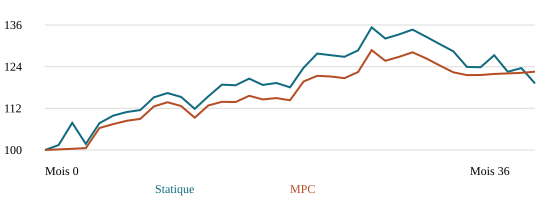

In [78]:
from riskmatch.dynamic.policies import simulate, POLICIES
from riskmatch.prototype import synthetic_returns
returns26 = synthetic_returns(seed=42)
policies26 = {}
paths26 = {}
for policy in ("static", "drift", *POLICIES):
    result = simulate(returns26[:, :2], returns26[:, 3], list(range(len(returns26))),
                      84, 100000, policy, [.6,.4], .30,.25)
    assert result["status"] == "computed" and len(result["ledger"]) == 36
    paths26[policy] = result["nav"]
    policies26[policy] = {k: result[k] for k in ("ending","fees","volatility","drawdown")}
display(pd.DataFrame.from_dict(policies26, orient="index").round(4))
# Monthly net wealth index, rebased to 100 at the beginning of the holdout.
from IPython.display import SVG
series = {key: 100 * np.asarray(paths26[key]) for key in ("static", "mpc")}
floor = np.floor(min(y.min() for y in series.values()))
ceiling = np.ceil(max(y.max() for y in series.values()))
parts = ['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 560 200" width="560"><title>Capital net synthétique, base 100</title>']
for tick in np.linspace(floor, ceiling, 4):
    y = 150 - 125 * (tick-floor)/(ceiling-floor)
    parts.append(f'<path d="M45 {y}h490" stroke="#ddd"/><text x="4" y="{y+4}" font-size="12">{tick:.0f}</text>')
for (label, values), color in zip(series.items(), ("#116b80", "#b64d25")):
    xy = [(45+490*i/(len(values)-1), 150-125*(v-floor)/(ceiling-floor)) for i,v in enumerate(values)]
    points = " ".join(f"{x:.2f},{y:.2f}" for x,y in xy)
    parts.append(f'<polyline points="{points}" stroke="{color}" stroke-width="2" fill="none"/>')
parts.append('<text x="45" y="175">Mois 0</text><text x="470" y="175">Mois 36</text><text x="155" y="193" fill="#116b80">Statique</text><text x="290" y="193" fill="#b64d25">MPC</text></svg>')
display(SVG("".join(parts)))

### 26.2 Validation

### 26.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [79]:
if historical_mode:
    review.chapter(26)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [80]:
show_checklist('26')

<a id="chapitre-27"></a>

## 27 — Integration and Validation

**Objective:** Reports, exports, UI tests, security, independent validation and paper trading.

Reference: [A–Z Guide, chapter 17](../docs/QUANT_GUIDE_A_Z.md).

Status: experimental integration and paper-only export. See [validation protocol](../docs/INTEGRATION.md).

### 27.1 Theory and Assumptions

[Note de recherche du projet](../docs/INTEGRATION.md)

#### Local paper workflow

Mandate → Discovery → Explore → My Matches → Confirm paper allocation → Dynamic management → Choose a policy → Export paper simulation ZIP.

The server reconstructs the Chapter 25 allocation and the Chapter 26 ledger from its frozen local inputs for every export. The selected policy must be computed over all expected dates. The validator checks capital continuity, cash flows, fees, P&L, funded weights, positions, transaction fees, return calculations and modeled stress limits. Infeasible or incomplete simulations do not produce an export. The result is deterministic for identical inputs and research versions.

| File | Meaning |
|---|---|
| weights.csv | Executed sleeve weights for each period |
| positions.csv | Ending sleeve-account notionals in USD |
| trades.csv | Actual simulated signed sleeve transfers in USD |
| nav.csv | Opening value, external flows, fees, profit/loss, end value, time-weighted return and turnover |
| metrics.json | Policy performance and costs |
| exposures.csv | Chapter 25 selected basket look-through weights before dynamic overlay |
| scenarios.csv | Chapter 25 selected basket stress returns before dynamic overlay |
| assumptions.json | Configuration, model and archive versions, scope and units |
| ledger.json | Full period-level simulation ledger |
| audit.json | Reconciliation status and SHA-256 digest of each ledger row |
| sensitivity.json | Cost and frequency comparisons |
| manifest.json | Stable run identity and content hashes for every other file |

All results are local research exports. Sleeve notionals are abstract funded accounts. Individual purchase quantities, broker execution, settlement and live orders are unavailable. Downloads contain derived information about the fictional mandate's capital and flows. Keep them private.

#### Save backups and recovery

The Saves screen offers a JSON backup of local encrypted entries and a restore option while locked. Imports merge by stable save ID and preserve existing entries. The original PIN or legacy passphrase is required to unlock an imported entry. The backup contains encrypted snapshots along with plaintext save names, IDs and encryption metadata. Four-digit PINs have a small search space and are suitable only for fictional local profiles. The project does not provide multi-user authentication or server-side account recovery.

#### Validation protocol

Run the unit suite, browser interaction tests, notebook schema and checklist checks, dependency graph check and Git path exclusion check. CI replays the entire notebook in its portable mode; historical calculations are enabled explicitly for local replay. Chapter 25 and 26 historical examples require privately held data and run locally. Chapter 27 has a deterministic synthetic export example for CI. Local API handler tests can verify route responses and JSON contracts without opening sockets.

The project remains an academic paper-simulation prototype. Actual host browser rendering, production authorization, independent financial and behavioral review, legal/privacy assessment, data distribution rights and full mandate/universe coverage remain formal acceptance items. No order execution endpoint is provided.

#### Local evidence (2026-11-25)

The 45-month historical 60/40 Mean Reversion / Black-Litterman MPC export returned HTTP-handler status 200 with a reconciled twelve-file ZIP. The unit suite passed 171 tests plus five subtests before the additional route test, which passed in the three-test export suite. All 33 browser interaction tests pass, and all 27 approved synthetic notebook cells execute directly in a Python namespace. Schema, checklist, DAG and tracked-path audits pass. The environment denied local port binding during the three HTTP integration tests and Jupyter kernel launch; those end-to-end transport tests still require host execution.

In [81]:
import numpy as np, base64, io, zipfile
from riskmatch.dynamic.policies import simulate, VERSION as dynamic_version
from riskmatch.integration import export_simulation
dates27 = [f'month-{i}' for i in range(24)]
fixture27 = simulate(np.tile([.01,.002], (24,1)), np.full(24,.001), dates27, 13, 100000, 'static', [.6,.4], .2,.15)
report27 = {'status':'experimental','version':dynamic_version,'match_version':'synthetic-fixture','reference_run':'synthetic-fixture','names':['A','B'],'dates':dates27[13:],'policies':{'static':fixture27},'settings':{'capital':100000,'stress_limit':.2},'selection':{'weights':{'A':.6,'B':.4},'scenarios':{'fixture':-.15}},'assumptions':'Synthetic CI demonstration','sensitivity':{}}
export27 = export_simulation(report27,'static')
with zipfile.ZipFile(io.BytesIO(base64.b64decode(export27['archive']))) as archive27:
    print(export27['status'], archive27.namelist())

reconciled ['weights.csv', 'positions.csv', 'trades.csv', 'nav.csv', 'metrics.json', 'exposures.csv', 'scenarios.csv', 'assumptions.json', 'audit.json', 'ledger.json', 'sensitivity.json', 'manifest.json']


### 27.2 Validation

### 27.3 — Résultats historiques et vérification du moteur web

Le mode historique affiche les paramètres et la réponse complète des calculs utilisés par la web app. Les états expérimentaux, partiels et indisponibles sont conservés. Les campagnes archivées sont vérifiées individuellement; la réestimation intégrale de toutes les archives requiert les scripts de construction et les sources originales.

In [82]:
if historical_mode:
    review.chapter(27)
else:
    print("Rapport historique disponible en mode historique; voir les instructions de reproduction.")

Rapport historique disponible en mode historique; voir les instructions de reproduction.


In [83]:
show_checklist('27')